# Projekt 2A – Przygotowanie i charakterystyka zbiorów danych

Notatnik obejmuje przygotowanie czterech szeregów czasowych do eksperymentów z modelami LSTM i GRU. **Nie trenuje żadnych modeli.** Sekcje 1–3 obejmują przygotowanie danych (opis i analiza wstępna, chronologiczny podział i skalowanie, okna czasowe; Raport 1) oraz pełną charakterystykę zbiorów (rozkład targetu w zbiorach, dekompozycja, stacjonarność, periodogram, zmienne pomocnicze i porównanie zbiorów; Raport 2, punkty 2.1 i 3.6–3.11).

| Zbiór | Domena | Dane surowe | Częstotliwość robocza | Target |
| --- | --- | --- | --- | --- |
| Jena Climate | pogoda | co 10 min | 1 h | temperatura `T (degC)` |
| Household Power Consumption | energia | co 1 min | 1 h | `Global_active_power` (kW) |
| Metro Interstate Traffic Volume | ruch drogowy | co 1 h | 1 h | `traffic_volume` |
| Air Passengers | lotnictwo | miesięcznie | 1 miesiąc | liczba pasażerów (tys.) |

**Przyjęte zasady:**

1. Jakość danych (braki, duplikaty, regularność znaczników czasu, wartości fizycznie niemożliwe) badamy **na danych surowych**, przed agregacją i uzupełnianiem luk.
2. Agregację do 1 h definiujemy osobno dla każdej zmiennej; wartość godzinową oznaczamy **końcem** przedziału, którego dotyczy.
3. Luki do 3 kroków uzupełniamy wyłącznie przyczynowo (ostatnia znana wartość); dłuższe zostają brakami.
4. Podział jest chronologiczny (60/20/20, granice na północy; Air Passengers: pełne lata). Skaler, profile sezonowe, ACF i porównanie lagów sezonowych dopasowujemy **wyłącznie na zbiorze uczącym**. Wykres całego szeregu jest wyłącznie opisowy.
5. Okno wejściowe zawiera wyłącznie obserwacje sprzed chwili prognozy; przykład należy do zbioru według czasu wartości docelowej.

**Uruchomienie:** Jupyter Lab → *Run All*. Wystarczy CPU i ok. 3 GB wolnej pamięci RAM. Pakiety: `pip install -r requirements.txt`. Przy pierwszym uruchomieniu potrzebny jest internet (ok. 35 MB danych); pobrane pliki zostają w folderze `data/`. Wyniki trafiają do folderu `outputs/dane/` (wykresy PNG i tabele CSV), spakowanego na końcu do pliku `dane_wyniki.zip`.

**Struktura notatnika.** Notatnik rozwijamy etapami; numeracja sekcji jest stała, a kolejne sekcje dochodzą wraz z kolejnymi raportami.

| Sekcja | Zawartość | Raport |
| --- | --- | --- |
| 0. Środowisko | wersje bibliotek, sprzęt, seed, moduł `ts_data.py` | 1 |
| 1. Dane i analiza wstępna | opis czterech zbiorów, jakość danych, agregacja, przebieg szeregu | 1, 2 |
| 2. Chronologiczny podział i skalowanie | tabela podziału, skaler dopasowany na train; 2.1 rozkład targetu w zbiorach | 1, 2 |
| 3. Okna czasowe i charakterystyka szeregów | sezonowość i ACF na train, `make_windows` z testem, kształty X i y, uzasadnienie długości okna; 3.6–3.11 dekompozycja, stacjonarność, periodogram, zmienne pomocnicze, wartości odstające, porównanie zbiorów | 1, 2 |
| 4. Architektura LSTM/GRU | modele w Keras, liczba parametrów, ustawienia treningu | 3 |
| 5. Trening i diagnostyka | EarlyStopping, krzywe uczenia, przeuczenie, czas treningu, wpływ architektury | 3 |
| 6. Modele bazowe | persistence, seasonal naive, regresja liniowa, Dense na tych samych oknach | 3 |
| 7. Walidacja i porównanie | metryki walidacyjne w oryginalnej skali, skill score, długość okna, wejście wielowymiarowe | 3 |
| 8. Ocena końcowa | jednorazowa ocena na zbiorze testowym, tabela końcowa, analiza reszt i największych błędów | 4 |
| 9. Rozszerzenie | dodatkowa architektura (Transformer albo TCN), jeśli pozwoli czas | 4 |

Bieżąca wersja zawiera sekcje 0–3 (Raporty 1 i 2).

## 0. Środowisko

In [1]:
import sys, time, platform, importlib, shutil
from pathlib import Path
import numpy as np, pandas as pd, matplotlib, matplotlib.pyplot as plt
import statsmodels, sklearn

SEED = 42
np.random.seed(SEED)
OUT = Path('outputs/dane'); OUT.mkdir(parents=True, exist_ok=True)
DATA = Path('data')
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
T0 = time.time()

pd.Series({'Python': platform.python_version(), 'pandas': pd.__version__, 'numpy': np.__version__,
           'statsmodels': statsmodels.__version__, 'scikit-learn': sklearn.__version__,
           'matplotlib': matplotlib.__version__, 'system': platform.platform(),
           'procesor': platform.processor()}, name='wersja').to_frame()

,wersja
Python,3.12.10
pandas,3.1.0
numpy,2.5.4
statsmodels,0.15.0
scikit-learn,1.9.1
matplotlib,3.11.2
system,Windows-11-10.0.26200-SP0
procesor,"Intel64 Family 6 Model 170 Stepping 4, Genuine..."


### 0.1 Moduł wspólny `ts_data.py`

Kolejna komórka zapisuje do pliku moduł z całym kodem wczytywania, kontroli jakości, agregacji, podziału, skalowania i tworzenia okien. Ten sam plik importujemy w notatnikach z eksperymentami, dzięki czemu przygotowanie danych jest zdefiniowane w jednym miejscu.

In [2]:
%%writefile ts_data.py
"""Projekt 2A - wczytywanie, kontrola jakosci, agregacja i podzial czterech szeregow.

Modul jest wspolny dla notatnika EDA (Raport 2) i pozniejszych eksperymentow
(Raport 3-4), zeby preprocessing byl zdefiniowany w jednym miejscu.

Zasady (zgodne z protokolem eksperymentalnym):
- EDA najpierw na danych surowych: braki, duplikaty, regularnosc znacznikow czasu,
  wartosci fizycznie niemozliwe - przed agregacja i uzupelnianiem luk.
- Agregacja do 1 h zdefiniowana osobno dla kazdej zmiennej; wartosc godzinowa
  oznaczona KONCEM przedzialu (closed='right', label='right').
- Uzupelnianie luk wylacznie przyczynowe (ffill) i tylko dla krotkich luk.
- Podzial chronologiczny; ACF, profile sezonowe i porownanie lagow
  liczone WYLACZNIE na czesci treningowej.
"""
from __future__ import annotations

import io
import urllib.request
import zipfile
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import pandas as pd

# ---------------------------------------------------------------------------
# Specyfikacje zbiorow
# ---------------------------------------------------------------------------


@dataclass(frozen=True)
class DatasetSpec:
    key: str
    name: str
    source: str
    url: str
    target: str
    unit: str
    freq: str                    # czestotliwosc robocza: 'h' albo 'MS'
    raw_step: str | None         # krok surowych danych (dla kontroli siatki)
    per_hour: int | None         # oczekiwana liczba surowych obserwacji na godzine
    horizons: tuple[int, ...]
    seasonal_candidates: tuple[int, ...]
    acf_nlags: int
    step_word: str               # 'h' albo 'mies.'


SPECS: dict[str, DatasetSpec] = {
    "jena": DatasetSpec(
        key="jena", name="Jena Climate",
        source="Max Planck Institute for Biogeochemistry (przez Keras)",
        url="https://storage.googleapis.com/tensorflow/tf-keras-datasets/jena_climate_2009_2016.csv.zip",
        target="T (degC)", unit="°C", freq="h", raw_step="10min", per_hour=6,
        horizons=(1, 6, 24), seasonal_candidates=(24, 168), acf_nlags=400, step_word="h"),
    "household": DatasetSpec(
        key="household", name="Household Power Consumption",
        source="UCI ML Repository, doi:10.24432/C58K54",
        url="https://archive.ics.uci.edu/static/public/235/individual+household+electric+power+consumption.zip",
        target="Global_active_power", unit="kW", freq="h", raw_step="1min", per_hour=60,
        horizons=(1, 6, 24), seasonal_candidates=(24, 168), acf_nlags=400, step_word="h"),
    "metro": DatasetSpec(
        key="metro", name="Metro Interstate Traffic Volume",
        source="UCI ML Repository, doi:10.24432/C5X60B",
        url="https://archive.ics.uci.edu/static/public/492/metro+interstate+traffic+volume.zip",
        target="traffic_volume", unit="pojazdy/h", freq="h", raw_step="1h", per_hour=1,
        horizons=(1, 6, 24), seasonal_candidates=(24, 168), acf_nlags=400, step_word="h"),
    "air": DatasetSpec(
        key="air", name="Air Passengers",
        source="Box i Jenkins (1976), kopia z Rdatasets",
        url="https://raw.githubusercontent.com/vincentarelbundock/Rdatasets/master/csv/datasets/AirPassengers.csv",
        target="passengers", unit="tys. pasażerów", freq="MS", raw_step=None, per_hour=None,
        horizons=(1, 3, 12), seasonal_candidates=(12,), acf_nlags=36, step_word="mies."),
}

JENA_COLS = ["p (mbar)", "T (degC)", "Tpot (K)", "Tdew (degC)", "rh (%)", "VPmax (mbar)",
             "VPact (mbar)", "VPdef (mbar)", "sh (g/kg)", "H2OC (mmol/mol)", "rho (g/m**3)",
             "wv (m/s)", "max. wv (m/s)", "wd (deg)"]
HOUSEHOLD_COLS = ["Global_active_power", "Global_reactive_power", "Voltage", "Global_intensity",
                  "Sub_metering_1", "Sub_metering_2", "Sub_metering_3"]
METRO_NUM = ["temp", "rain_1h", "snow_1h", "clouds_all", "traffic_volume"]

# ---------------------------------------------------------------------------
# Pobieranie i wczytywanie surowych danych
# ---------------------------------------------------------------------------


def download(key: str, data_dir: str | Path = "data") -> Path:
    """Pobiera plik zrodlowy (jesli nie ma go w data_dir) i zwraca sciezke."""
    spec = SPECS[key]
    data_dir = Path(data_dir)
    data_dir.mkdir(parents=True, exist_ok=True)
    path = data_dir / Path(spec.url).name
    if not path.exists():
        print(f"Pobieram {spec.name} ...")
        urllib.request.urlretrieve(spec.url, path)
    return path


def _zip_member(path: Path, suffixes: tuple[str, ...]) -> tuple[bytes, str]:
    with zipfile.ZipFile(path) as zf:
        names = [n for n in zf.namelist() if n.lower().endswith(suffixes) and not n.startswith("__MACOSX")]
        if not names:
            raise FileNotFoundError(f"Brak pliku {suffixes} w {path}")
        return zf.read(names[0]), names[0]


def load_raw(key: str, data_dir: str | Path = "data") -> pd.DataFrame:
    """Surowe dane z kolumna 'time' (bez sortowania i bez usuwania duplikatow)."""
    path = download(key, data_dir)
    if key == "jena":
        raw, _ = _zip_member(path, (".csv",))
        df = pd.read_csv(io.BytesIO(raw))
        df["time"] = pd.to_datetime(df["Date Time"], format="%d.%m.%Y %H:%M:%S")
        df = df.drop(columns="Date Time")
    elif key == "household":
        raw, _ = _zip_member(path, (".txt",))
        df = pd.read_csv(io.BytesIO(raw), sep=";", na_values=["?", ""], low_memory=False)
        df["time"] = pd.to_datetime(df["Date"] + " " + df["Time"], format="%d/%m/%Y %H:%M:%S")
        df = df.drop(columns=["Date", "Time"])
        df[HOUSEHOLD_COLS] = df[HOUSEHOLD_COLS].apply(pd.to_numeric, errors="coerce")
    elif key == "metro":
        raw, name = _zip_member(path, (".csv", ".csv.gz"))
        comp = "gzip" if name.endswith(".gz") else None
        df = pd.read_csv(io.BytesIO(raw), compression=comp)
        df["time"] = pd.to_datetime(df["date_time"], format="mixed")
        df = df.drop(columns="date_time")
        hol = df["holiday"].astype("string").str.strip()
        df["holiday"] = hol.where(~hol.isin(["None", "", "nan"]), pd.NA)
    elif key == "air":
        df = pd.read_csv(path)
        if len(df) != 144 or int(df["time"].iloc[0]) != 1949:
            raise ValueError("Nieoczekiwany format AirPassengers (oczekiwano 144 mies. od 1949)")
        df = pd.DataFrame({
            "time": pd.period_range("1949-01", periods=144, freq="M").to_timestamp(),
            "passengers": df["value"].astype(float).to_numpy(),
        })
    else:
        raise KeyError(key)
    cols = ["time"] + [c for c in df.columns if c != "time"]
    return df[cols]

# ---------------------------------------------------------------------------
# Kontrola jakosci danych surowych
# ---------------------------------------------------------------------------


def raw_regularity(df: pd.DataFrame, spec: DatasetSpec) -> pd.Series:
    """Regularnosc znacznikow czasu w danych surowych."""
    t = df["time"]
    uniq = t.drop_duplicates().sort_values()
    out = {
        "wiersze": len(df),
        "unikalne znaczniki czasu": t.nunique(),
        "wiersze ze zduplikowanym czasem": int(t.duplicated(keep=False).sum()),
        "nadmiarowe wiersze (duplikaty)": len(df) - t.nunique(),
        "posortowane rosnąco": bool(t.is_monotonic_increasing),
        "początek": t.min(),
        "koniec": t.max(),
    }
    if spec.raw_step is not None:
        step = pd.Timedelta(spec.raw_step)
        grid = pd.date_range(uniq.iloc[0].floor(step), uniq.iloc[-1], freq=step)
        on_grid = uniq.isin(grid)
        out["oczekiwane punkty siatki"] = len(grid)
        out["brakujące punkty siatki"] = int(len(grid) - on_grid.sum())
        out["znaczniki poza siatką"] = int((~on_grid).sum())
    else:
        grid = pd.date_range(uniq.iloc[0], uniq.iloc[-1], freq=spec.freq)
        out["oczekiwane punkty siatki"] = len(grid)
        out["brakujące punkty siatki"] = int(len(grid) - uniq.isin(grid).sum())
    diffs = uniq.diff().dropna()
    out["najczęstszy krok"] = diffs.mode().iloc[0] if len(diffs) else pd.NaT
    out["najdłuższa przerwa"] = diffs.max() if len(diffs) else pd.NaT
    return pd.Series(out, name=spec.name)


def missing_table(df: pd.DataFrame) -> pd.DataFrame:
    """Braki w kazdej kolumnie surowych danych."""
    n = df.isna().sum()
    return pd.DataFrame({"braki": n, "braki %": (100 * n / len(df)).round(3)}).rename_axis("kolumna")


def duplicate_report(df: pd.DataFrame, spec: DatasetSpec) -> pd.DataFrame:
    """Czy wiersze o tym samym czasie maja rozne wartosci (w szczegolnosci targetu)?"""
    dup = df[df["time"].duplicated(keep=False)]
    if dup.empty:
        return pd.DataFrame(columns=["kolumna", "grupy z różnymi wartościami"])
    rows = []
    for c in [c for c in df.columns if c != "time"]:
        n_diff = int((dup.groupby("time")[c].nunique(dropna=False) > 1).sum())
        rows.append({"kolumna": c, "grupy z różnymi wartościami": n_diff})
    out = pd.DataFrame(rows)
    out.attrs["grupy duplikatów"] = dup["time"].nunique()
    return out


# Reguly wartosci fizycznie niemozliwych (ustalone a priori, nie dopasowywane do danych).
ANOMALY_RULES = {
    "jena": [
        ("wv (m/s)", "prędkość wiatru < 0", lambda s: s < 0),
        ("max. wv (m/s)", "maks. prędkość wiatru < 0", lambda s: s < 0),
        ("rh (%)", "wilgotność poza [0, 100] %", lambda s: (s < 0) | (s > 100)),
        ("p (mbar)", "ciśnienie poza [800, 1100] mbar", lambda s: (s < 800) | (s > 1100)),
    ],
    "household": [
        ("Global_active_power", "moc czynna < 0", lambda s: s < 0),
        ("Global_reactive_power", "moc bierna < 0", lambda s: s < 0),
        ("Global_intensity", "natężenie < 0", lambda s: s < 0),
        ("Voltage", "napięcie poza [180, 280] V", lambda s: (s < 180) | (s > 280)),
    ],
    "metro": [
        ("temp", "temperatura ≤ 0 K", lambda s: s <= 0),
        ("rain_1h", "opad > 300 mm/h (powyżej rekordu świata)", lambda s: s > 300),
        ("snow_1h", "opad śniegu < 0", lambda s: s < 0),
        ("clouds_all", "zachmurzenie poza [0, 100] %", lambda s: (s < 0) | (s > 100)),
        ("traffic_volume", "natężenie ruchu < 0", lambda s: s < 0),
    ],
    "air": [
        ("passengers", "liczba pasażerów ≤ 0", lambda s: s <= 0),
    ],
}


def apply_anomaly_rules(df: pd.DataFrame, key: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Zamienia wartosci fizycznie niemozliwe na brak; zwraca tez tabele zliczen."""
    out = df.copy()
    rows = []
    for col, desc, rule in ANOMALY_RULES[key]:
        if col not in out.columns:
            continue
        mask = rule(out[col]).fillna(False).astype(bool)
        vals = out.loc[mask, col]
        rows.append({"kolumna": col, "reguła": desc, "liczba": int(mask.sum()),
                     "%": round(100 * mask.mean(), 4),
                     "przykładowe wartości": ", ".join(map(str, vals.unique()[:3]))})
        out.loc[mask, col] = np.nan
    return out, pd.DataFrame(rows)

# ---------------------------------------------------------------------------
# Agregacja do czestotliwosci roboczej
# ---------------------------------------------------------------------------


def _dedupe(d: pd.DataFrame, target: str) -> pd.DataFrame:
    """Laczy wiersze o tym samym czasie. Target: identyczne wartosci -> ta wartosc,
    sprzeczne wartosci -> brak (nie zgadujemy, ktory pomiar jest prawdziwy).
    Pozostale zmienne liczbowe: srednia."""
    g = d.groupby("time")
    out = g.mean(numeric_only=True)
    conflict = g[target].nunique() > 1
    out[target] = g[target].first().where(~conflict)
    return out.reset_index()


def _resample_hour(d: pd.DataFrame):
    return d.set_index("time").sort_index().resample("1h", closed="right", label="right")


def to_working_freq(df_clean: pd.DataFrame, spec: DatasetSpec) -> pd.DataFrame:
    """Agregacja wg regul per zmienna. Zwraca ramke na regularnej siatce z kolumna 'coverage'.

    Godzina, w ktorej jest mniej niz 50% surowych pomiarow targetu, jest traktowana jako brak.
    """
    key = spec.key
    if key == "jena":
        d = _dedupe(df_clean, spec.target)
        rad = np.deg2rad(d["wd (deg)"])
        d["wx (m/s)"] = d["wv (m/s)"] * np.cos(rad)                          # kierunek wiatru jako wektor
        d["wy (m/s)"] = d["wv (m/s)"] * np.sin(rad)
        d = d.drop(columns="wd (deg)")
        r = _resample_hour(d)
        h = r.mean()
        h["max. wv (m/s)"] = r["max. wv (m/s)"].max()
        h["coverage"] = r[spec.target].count() / spec.per_hour
    elif key == "household":
        d = _dedupe(df_clean, spec.target)
        r = _resample_hour(d)
        h = r.mean()
        sub = ["Sub_metering_1", "Sub_metering_2", "Sub_metering_3"]
        # Energia w godzinie [Wh] OSZACOWANA z dostepnych minut: srednia * 60.
        # Przy pelnej godzinie rowna sumie; przy niepelnej (pokrycie 50-99%) to korekta na brakujace
        # minuty (zwykla suma zanizalaby energie). Liczbe takich godzin raportuje data_accounting.
        h[sub] = h[sub] * 60
        h["coverage"] = r[spec.target].count() / spec.per_hour
    elif key == "metro":
        d = df_clean.copy()
        d["temp"] = d["temp"] - 273.15           # K -> °C (po usunieciu 0 K)
        weather = pd.get_dummies(d["weather_main"], prefix="w").astype(float)
        d = pd.concat([d[["time"] + METRO_NUM], weather], axis=1)
        d["holiday"] = df_clean["holiday"].notna().astype(float)
        agg = {c: "mean" for c in METRO_NUM}
        agg[spec.target] = "first"
        agg.update({c: "max" for c in weather.columns})
        agg["holiday"] = "max"
        h = d.groupby("time").agg(agg)           # kilka raportow pogody na godzine -> jeden wiersz
        conflict = d.groupby("time")[spec.target].nunique() > 1
        h.loc[conflict[conflict].index, spec.target] = np.nan   # sprzeczne natezenie ruchu -> brak
        h = h.rename(columns={"temp": "temp (degC)"})
        # swieto jest znane z gory: oznaczamy cala dobe, nie tylko godzine z wpisem
        hol_days = h.index[h["holiday"] > 0].normalize().unique()
        full = pd.date_range(h.index.min().floor("h"), h.index.max(), freq="h")
        h = h.reindex(full)
        h["holiday"] = h.index.normalize().isin(hol_days).astype(float)
        h["coverage"] = h[spec.target].notna().astype(float)
    elif key == "air":
        h = df_clean.set_index("time").asfreq("MS")
        h["coverage"] = h[spec.target].notna().astype(float)
    else:
        raise KeyError(key)
    h.index.name = "time"
    if key != "air":
        h = h.asfreq("h")
    low = h["coverage"].fillna(0) < 0.5
    value_cols = [c for c in h.columns if c != "coverage"]
    h.loc[low, value_cols] = np.nan
    return h

# ---------------------------------------------------------------------------
# Luki
# ---------------------------------------------------------------------------


def nan_runs(s: pd.Series) -> pd.DataFrame:
    """Ciagi brakow: poczatek, koniec, dlugosc (w krokach)."""
    isna = s.isna().to_numpy()
    if not isna.any():
        return pd.DataFrame(columns=["początek", "koniec", "długość"])
    edges = np.diff(np.concatenate([[0], isna.astype(int), [0]]))
    starts, ends = np.where(edges == 1)[0], np.where(edges == -1)[0] - 1
    return pd.DataFrame({"początek": s.index[starts], "koniec": s.index[ends], "długość": ends - starts + 1})


def gap_summary(s: pd.Series, max_fill: int, step_word: str) -> pd.DataFrame:
    runs = nan_runs(s)
    bins = [(1, 1), (2, max_fill), (max_fill + 1, 24), (25, 10**9)]
    labels = [f"1 {step_word}", f"2–{max_fill} {step_word}", f"{max_fill + 1}–24 {step_word}", f"> 24 {step_word}"]
    rows = []
    for (lo, hi), lab in zip(bins, labels):
        sel = runs[(runs["długość"] >= lo) & (runs["długość"] <= hi)] if len(runs) else runs
        rows.append({"długość luki": lab, "liczba luk": len(sel),
                     "brakujące kroki": int(sel["długość"].sum()) if len(sel) else 0,
                     "uzupełniana": "tak (ffill)" if hi <= max_fill else "nie"})
    return pd.DataFrame(rows)


def data_accounting(raw: pd.DataFrame, clean: pd.DataFrame, h: pd.DataFrame, h_f: pd.DataFrame,
                    spec: DatasetSpec) -> pd.DataFrame:
    """Bilans targetu od danych surowych do szeregu roboczego: ile polaczono, usunieto, uzupelniono."""
    y_raw, y_clean = raw[spec.target], clean[spec.target]
    dup = raw[raw["time"].duplicated(keep=False)]
    conflict = int((dup.groupby("time")[spec.target].nunique() > 1).sum()) if len(dup) else 0
    filled = h[spec.target].isna() & h_f[spec.target].notna()
    rows = [
        ("dane surowe", "wiersze", len(raw)),
        ("dane surowe", "nadmiarowe wiersze o powtórzonym czasie (połączone)", len(raw) - raw["time"].nunique()),
        ("dane surowe", "grupy duplikatów ze sprzecznym targetem (target → brak)", conflict),
        ("dane surowe", "braki targetu w pliku", int(y_raw.isna().sum())),
        ("dane surowe", "wartości targetu usunięte jako niemożliwe", int(y_clean.isna().sum() - y_raw.isna().sum())),
        ("szereg roboczy", f"kroki na regularnej siatce ({spec.freq})", len(h)),
        ("szereg roboczy", "kroki z niepełnym pokryciem 50–99% (wartość z dostępnych pomiarów)",
         int(((h["coverage"] >= 0.5) & (h["coverage"] < 1)).sum())),
        ("szereg roboczy", "kroki bez targetu po agregacji", int(h[spec.target].isna().sum())),
        ("szereg roboczy", "kroki targetu uzupełnione (luki ≤ 3)", int(filled.sum())),
        ("szereg roboczy", "kroki bez targetu po uzupełnieniu (długie luki)", int(h_f[spec.target].isna().sum())),
    ]
    return pd.DataFrame(rows, columns=["etap", "pozycja", "liczba"])


def fill_short_gaps(df: pd.DataFrame, max_gap: int = 3) -> tuple[pd.DataFrame, pd.Series]:
    """Przyczynowe uzupelnienie luk <= max_gap krokow (ostatnia znana wartosc). Dluzsze luki zostaja."""
    out = df.copy()
    flag = pd.Series(False, index=df.index, name="filled")
    for c in out.columns:
        s = out[c]
        if c == "coverage" or not pd.api.types.is_numeric_dtype(s):
            continue
        isna = s.isna()
        if not isna.any():
            continue
        run_id = (isna != isna.shift()).cumsum()
        run_len = isna.groupby(run_id).transform("sum")
        short = isna & (run_len <= max_gap)
        filled = s.ffill()
        ok = short & filled.notna()
        out.loc[ok, c] = filled[ok]
        flag |= ok
    return out, flag

# ---------------------------------------------------------------------------
# Podzial chronologiczny
# ---------------------------------------------------------------------------

SPLITS = ("train", "val", "test")


def chronological_split(index: pd.DatetimeIndex, spec: DatasetSpec) -> pd.Series:
    """Etykieta zbioru dla kazdego kroku. Granice: 60/20/20 osi czasu, zaokraglone do polnocy;
    Air Passengers: pelne lata 1949-1956 / 1957-1958 / 1959-1960."""
    if spec.key == "air":
        b1, b2 = pd.Timestamp("1957-01-01"), pd.Timestamp("1959-01-01")
    else:
        n = len(index)
        b1 = index[int(0.6 * n)].normalize()
        b2 = index[int(0.8 * n)].normalize()
    lab = np.where(index < b1, "train", np.where(index < b2, "val", "test"))
    return pd.Series(lab, index=index, name="split")


def split_table(h: pd.DataFrame, split: pd.Series, spec: DatasetSpec) -> pd.DataFrame:
    rows = []
    for name in SPLITS:
        part = h.loc[split == name, spec.target]
        rows.append({"zbiór": name, "od": part.index.min(), "do": part.index.max(),
                     "kroki": len(part), "udział %": round(100 * len(part) / len(h), 1),
                     "braki targetu": int(part.isna().sum()),
                     "średnia": round(part.mean(), 3), "odch. std.": round(part.std(), 3)})
    return pd.DataFrame(rows)

# ---------------------------------------------------------------------------
# Sezonowosc i autokorelacja (tylko train)
# ---------------------------------------------------------------------------


def acf_train(y_train: pd.Series, nlags: int, transform: str = "none") -> pd.Series:
    """ACF szeregu treningowego. transform: 'none', 'diff' (pierwsze roznice - usuwaja bezwladnosc
    i trend, wiec szczyty przy lagu s wskazuja na sezonowosc) albo 'dlog' (roznice logarytmu)."""
    from statsmodels.tsa.stattools import acf
    x = y_train.astype(float)
    if transform == "dlog":
        x = np.log(x).diff().iloc[1:]
    elif transform == "diff":
        x = x.diff().iloc[1:]
    nlags = min(nlags, len(x) // 2 - 1)
    vals = acf(x.to_numpy(), nlags=nlags, missing="conservative", fft=False)
    return pd.Series(vals, index=pd.RangeIndex(len(vals), name="lag"), name="ACF")


def seasonal_profiles(y_train: pd.Series, spec: DatasetSpec) -> dict[str, pd.DataFrame]:
    """Srednia i kwartyle targetu wg pory dnia, dnia tygodnia i miesiaca (train)."""
    idx = y_train.index
    groups = {"miesiąc": idx.month}
    if spec.freq == "h":
        groups = {"godzina": idx.hour, "dzień tygodnia": idx.dayofweek, **groups}
    out = {}
    for name, g in groups.items():
        out[name] = y_train.groupby(g).agg(
            średnia="mean", q25=lambda s: s.quantile(0.25), q75=lambda s: s.quantile(0.75))
    return out


def persistence_forecast(y: pd.Series, h: int) -> pd.Series:
    """ŷ(τ) = y(τ − h); indeks = czas celu τ."""
    return y.shift(h)


def seasonal_naive_forecast(y: pd.Series, h: int, s: int) -> pd.Series:
    """ŷ(t+h) = y(t+h − s(k+1)), k = ⌊(h−1)/s⌋; indeks = czas celu."""
    k = (h - 1) // s
    return y.shift(s * (k + 1))


def baseline_check_train(y_train: pd.Series, spec: DatasetSpec) -> pd.DataFrame:
    """MAE persistence i seasonal naive (kazdy kandydat s) na train; skill wzgledem persistence."""
    rows = []
    for h in spec.horizons:
        pers = persistence_forecast(y_train, h)
        for s in spec.seasonal_candidates:
            sn = seasonal_naive_forecast(y_train, h, s)
            m = y_train.notna() & pers.notna() & sn.notna()
            mae_p = (y_train[m] - pers[m]).abs().mean()
            mae_s = (y_train[m] - sn[m]).abs().mean()
            same = s * ((h - 1) // s + 1) == h
            rows.append({"horyzont": h, "s": s, "MAE persistence": round(mae_p, 4),
                         "MAE seasonal naive": round(mae_s, 4),
                         "skill SN": round(1 - mae_s / mae_p, 4),
                         "SN ≡ persistence": "tak" if same else "nie", "n": int(m.sum())})
    return pd.DataFrame(rows)


def propose_seasonal_period(lag_table: pd.DataFrame) -> int:
    """Okres s o najmniejszym srednim (po horyzontach) MAE seasonal naive na train."""
    return int(lag_table.groupby("s")["MAE seasonal naive"].mean().idxmin())


def feature_columns(h: pd.DataFrame, spec: DatasetSpec) -> list[str]:
    """Kolumny liczbowe modelu: target na pierwszym miejscu, potem pozostale zmienne (bez 'coverage')."""
    cols = [c for c in h.columns if c not in ("coverage",) and pd.api.types.is_numeric_dtype(h[c])]
    return [spec.target] + [c for c in cols if c != spec.target]


def fit_scaler(h: pd.DataFrame, split: pd.Series, cols: list[str]):
    """StandardScaler dopasowany WYLACZNIE na zbiorze uczacym. Kolumny binarne (0/1) nie sa skalowane."""
    from sklearn.preprocessing import StandardScaler
    train = h.loc[split == "train", cols]
    binary = [c for c in cols if set(train[c].dropna().unique()) <= {0.0, 1.0}]
    cont = [c for c in cols if c not in binary]
    scaler = StandardScaler().fit(train[cont].dropna())
    return scaler, cont


def apply_scaler(h: pd.DataFrame, cols: list[str], scaler, cont: list[str]) -> pd.DataFrame:
    out = h[cols].astype(float).copy()
    out[cont] = scaler.transform(out[cont])
    return out


def scaling_table(h_scaled: pd.DataFrame, split: pd.Series, scaler, cont: list[str], spec: DatasetSpec) -> pd.DataFrame:
    """Parametry skalera (z train) i kontrola: srednia/odch. targetu po skalowaniu w kazdym zbiorze."""
    i = cont.index(spec.target)
    row = {"średnia z train (skaler)": round(float(scaler.mean_[i]), 4),
           "odch. std. z train (skaler)": round(float(scaler.scale_[i]), 4)}
    for name in SPLITS:
        y = h_scaled.loc[split == name, spec.target]
        row[f"{name}: średnia po skalowaniu"] = round(float(y.mean()), 3)
        row[f"{name}: odch. std. po skalowaniu"] = round(float(y.std()), 3)
    return pd.Series(row, name=spec.target).to_frame()


def make_windows(data, window_size: int = 30, horizon: int = 1, target_col: int = 0):
    """Okna wejsciowe bez zagladania w przyszlosc.

    data: tablica (T,) lub (T, d). Przyklad i: X = data[i : i+L] (kroki t-L+1..t), y = data[i+L+h-1, target]
    (krok t+h). Zwraca X (n, L, d), y (n,) i pozycje celu w szeregu (n,). Okna z brakiem w wejsciu lub celu
    sa pomijane."""
    a = np.asarray(data, dtype=float)
    if a.ndim == 1:
        a = a[:, None]
    L, h = int(window_size), int(horizon)
    n = len(a) - L - h + 1
    if n <= 0:
        return np.empty((0, L, a.shape[1])), np.empty(0), np.empty(0, dtype=int)
    idx = np.arange(n)
    X = np.lib.stride_tricks.sliding_window_view(a, (L, a.shape[1]))[:n, 0]
    tgt = idx + L + h - 1
    y = a[tgt, target_col]
    ok = ~np.isnan(X).any(axis=(1, 2)) & ~np.isnan(y)
    return X[ok], y[ok], tgt[ok]


def windows_by_split(h_scaled: pd.DataFrame, split: pd.Series, cols: list[str], window_size: int, horizon: int):
    """Okna przypisane do zbiorow wg czasu CELU (wejscie moze siegac do konca poprzedniego zbioru)."""
    X, y, tgt = make_windows(h_scaled[cols].to_numpy(), window_size, horizon, target_col=0)
    lab = split.to_numpy()[tgt]
    return {name: (X[lab == name], y[lab == name], h_scaled.index[tgt[lab == name]]) for name in SPLITS}


def window_shape_table(h_scaled, split, cols, windows, horizons) -> pd.DataFrame:
    rows = []
    for L in windows:
        for hz in horizons:
            w = windows_by_split(h_scaled, split, cols, L, hz)
            row = {"okno L": L, "horyzont h": hz}
            for name in SPLITS:
                row[f"X_{name}"] = str(tuple(w[name][0].shape))
            rows.append(row)
    return pd.DataFrame(rows)


def check_windows(split: pd.Series) -> pd.DataFrame:
    """Testy make_windows na szeregu arytmetycznym 0, 1, 2, ...: cel = ostatni krok wejscia + h, brak przecieku."""
    series = np.arange(len(split), dtype=float)
    rows = []
    for L, hz in [(30, 1), (30, 6), (24, 12)]:
        X, y, tgt = make_windows(series, L, hz)
        ok_target = bool(np.all(y == X[:, -1, 0] + hz))
        ok_order = bool(np.all(X[:, -1, 0] < y))
        lab = split.to_numpy()[tgt]
        first_val = np.where(lab == "val")[0]
        crosses = bool(len(first_val) and split.to_numpy()[int(X[first_val[0], 0, 0])] == "train")
        rows.append({"okno L": L, "horyzont h": hz, "cel = ostatni krok wejścia + h": ok_target,
                     "wejście przed celem": ok_order, "1. okno val sięga do train (dozwolone)": crosses})
    return pd.DataFrame(rows)


def plot_window(h_scaled: pd.DataFrame, split: pd.Series, cols: list[str], scaler, cont, spec: DatasetSpec,
                window_size: int = 30, horizon: int = 1, out_dir=None):
    """Ostatnie okno zbioru uczacego (skala oryginalna) i wartosc prognozowana."""
    import matplotlib.pyplot as plt
    w = windows_by_split(h_scaled, split, cols, window_size, horizon)
    X, y, times = w["train"]
    i = cont.index(spec.target)
    inv = lambda v: v * scaler.scale_[i] + scaler.mean_[i]
    step = pd.Timedelta(hours=1) if spec.freq == "h" else pd.DateOffset(months=1)
    t_end = times[-1] - horizon * step
    t_in = [t_end - (window_size - 1 - k) * step for k in range(window_size)]
    fig, ax = plt.subplots(figsize=(11, 3.2))
    ax.plot(t_in, inv(X[-1, :, 0]), color=SERIES[0], marker="o", ms=3, lw=1.2, label=f"okno wejściowe ({window_size} kroków)")
    ax.plot([times[-1]], [inv(y[-1])], "o", color=SERIES[1], ms=9, label=f"wartość prognozowana (t + {horizon})")
    ax.axvline(t_end, color=GRID, lw=1)
    ax.set_title(f"{spec.name}: przykładowe okno i cel (L = {window_size}, h = {horizon}, zbiór uczący)")
    ax.set_ylabel(spec.unit)
    ax.legend(loc="upper left", bbox_to_anchor=(0, -0.12), ncol=2)
    _save(fig, out_dir, f"{spec.key}_okno_L{window_size}_h{horizon}")
    return fig


def window_counts(y: pd.Series, split: pd.Series, windows, horizons) -> pd.DataFrame:
    """Liczba uzytecznych przykladow (okno L, horyzont h) w kazdym zbiorze.

    Przyklad nalezy do zbioru wg czasu celu; wejscie moze siegac do konca poprzedniego zbioru
    (bylo znane w chwili prognozy). Przyklad jest odrzucany, gdy cel albo dowolny krok okna
    wejsciowego jest brakiem (dluga luka) - tak samo jak w eksperymentach."""
    nan = y.isna().to_numpy().astype(int)
    csum = np.concatenate([[0], np.cumsum(nan)])
    pos = np.arange(len(y))
    lab = split.to_numpy()
    rows = []
    for L in windows:
        for h in horizons:
            start, end = pos - h - L + 1, pos - h            # wejscie: kroki start..end
            full = start >= 0
            nan_in = np.zeros(len(y), dtype=int)
            nan_in[full] = csum[end[full] + 1] - csum[start[full]]
            ok = full & (nan_in == 0) & (nan == 0)
            row = {"okno L": L, "horyzont h": h}
            for name in SPLITS:
                row[name] = int((ok & (lab == name)).sum())
            row["odrzucone przez luki"] = int((full & ~ok).sum())
            rows.append(row)
    return pd.DataFrame(rows)


def lagged_correlations(h_train: pd.DataFrame, spec: DatasetSpec, max_cols: int = 20) -> pd.DataFrame:
    """Korelacja Pearsona: zmienna w chwili t vs target w chwili t+h (train). Wiersz targetu = odniesienie."""
    y = h_train[spec.target]
    cols = [c for c in h_train.columns
            if c not in ("coverage",) and pd.api.types.is_numeric_dtype(h_train[c]) and h_train[c].nunique() > 1]
    cols = [spec.target] + [c for c in cols if c != spec.target][:max_cols]
    out = pd.DataFrame(index=pd.Index(cols, name="zmienna w chwili t"))
    for h in spec.horizons:
        fut = y.shift(-h)
        out[f"corr z y(t+{h})"] = [round(h_train[c].corr(fut), 3) for c in cols]
    return out

# ---------------------------------------------------------------------------
# Wykresy (matplotlib)
# ---------------------------------------------------------------------------

INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]
SPLIT_SHADE = {"val": "#ecebe7", "test": "#dcdbd6"}


def set_style():
    import matplotlib as mpl
    mpl.rcParams.update({
        "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
        "axes.edgecolor": INK2, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
        "text.color": INK, "axes.titlecolor": INK, "axes.titlesize": 12, "axes.titleweight": "bold",
        "axes.labelsize": 10, "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.fontsize": 9,
        "legend.frameon": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
        "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 1.0,
        "figure.dpi": 110,
    })


def _save(fig, out_dir, name):
    if out_dir is not None:
        p = Path(out_dir) / "figures"
        p.mkdir(parents=True, exist_ok=True)
        fig.savefig(p / f"{name}.png", dpi=150, bbox_inches="tight")


def _shade_splits(ax, split: pd.Series):
    v0 = split.index[split == "val"].min()
    t0 = split.index[split == "test"].min()
    end = split.index.max()
    for name, a, b in (("val", v0, t0), ("test", t0, end)):
        ax.axvspan(a, b, color=SPLIT_SHADE[name], zorder=0, lw=0)
        ax.text(a, 1.0, f" {name}", transform=ax.get_xaxis_transform(),
                va="top", ha="left", fontsize=9, color=INK2)


def plot_series(h: pd.DataFrame, split: pd.Series, spec: DatasetSpec, out_dir=None):
    import matplotlib.pyplot as plt
    y = h[spec.target]
    fig, ax = plt.subplots(figsize=(11, 3.4))
    _shade_splits(ax, split)
    ax.plot(y.index, y, color=SERIES[0], lw=0.4 if spec.freq == "h" else 1.4, label=spec.target)
    if spec.freq == "h":
        roll = y.rolling(24 * 30, min_periods=24 * 10).mean()       # srednia kroczaca wstecz (30 dni)
        ax.plot(roll.index, roll, color=SERIES[1], lw=1.6, label="średnia z ostatnich 30 dni")
        ax.legend(loc="upper left", bbox_to_anchor=(0, -0.1), ncol=2)
    ax.set_title(f"{spec.name}: przebieg szeregu i podział chronologiczny")
    ax.set_ylabel(spec.unit)
    _save(fig, out_dir, f"{spec.key}_przebieg")
    return fig


def plot_zoom(y: pd.Series, start, periods: int, spec: DatasetSpec, out_dir=None):
    import matplotlib.pyplot as plt
    part = y.loc[pd.Timestamp(start):].iloc[:periods]
    fig, ax = plt.subplots(figsize=(11, 3))
    ax.plot(part.index, part, color=SERIES[0], lw=1.2, marker="o" if spec.freq != "h" else None, ms=3)
    ax.set_title(f"{spec.name}: fragment {part.index.min():%Y-%m-%d} – {part.index.max():%Y-%m-%d} (train)")
    ax.set_ylabel(spec.unit)
    _save(fig, out_dir, f"{spec.key}_fragment")
    return fig


def plot_hist(y_train: pd.Series, spec: DatasetSpec, out_dir=None):
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(6, 3.2))
    ax.hist(y_train.dropna(), bins=60 if spec.freq == "h" else 20, color=SERIES[0], edgecolor=SURFACE, lw=0.5)
    ax.set_title(f"{spec.name}: rozkład targetu (train)")
    ax.set_xlabel(spec.unit)
    ax.set_ylabel("liczba kroków")
    _save(fig, out_dir, f"{spec.key}_histogram")
    return fig


def plot_profiles(profiles: dict[str, pd.DataFrame], spec: DatasetSpec, out_dir=None):
    import matplotlib.pyplot as plt
    labels = {"dzień tygodnia": ["pn", "wt", "śr", "cz", "pt", "so", "nd"]}
    fig, axes = plt.subplots(1, len(profiles), figsize=(4 * len(profiles), 3.2), squeeze=False)
    for ax, (name, p) in zip(axes[0], profiles.items()):
        ax.fill_between(p.index, p["q25"], p["q75"], color=SERIES[0], alpha=0.15, lw=0, label="kwartyle 25–75%")
        ax.plot(p.index, p["średnia"], color=SERIES[0], lw=2, marker="o", ms=3, label="średnia")
        ax.set_title(f"wg: {name}")
        ax.set_ylabel(spec.unit)
        if name in labels:
            ax.set_xticks(range(7), labels[name])
        elif name == "godzina":
            ax.set_xticks(range(0, 24, 3))
        else:
            ax.set_xticks(p.index)
    axes[0][0].legend(loc="best")
    fig.suptitle(f"{spec.name}: profile sezonowe (train)", fontweight="bold", x=0.01, ha="left")
    fig.tight_layout()
    _save(fig, out_dir, f"{spec.key}_profile")
    return fig


def plot_acf(acf_vals: pd.Series, n: int, spec: DatasetSpec, title_suffix: str = "", out_dir=None, name="acf"):
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(11, 3.2))
    lags = acf_vals.index[1:]
    ax.vlines(lags, 0, acf_vals.iloc[1:], color=SERIES[0], lw=0.8 if len(lags) > 60 else 2)
    conf = 1.96 / np.sqrt(n)
    ax.axhspan(-conf, conf, color=GRID, zorder=0, lw=0)
    ax.axhline(0, color=INK2, lw=0.8)
    for s in spec.seasonal_candidates:
        if s < len(acf_vals):
            ax.plot([s], [acf_vals.iloc[s]], "o", color=SERIES[1], ms=6, zorder=3)
            ax.annotate(f"lag {s}: {acf_vals.iloc[s]:.2f}", (s, acf_vals.iloc[s]),
                        textcoords="offset points", xytext=(6, 6), fontsize=9, color=INK)
    ax.set_ylim(top=max(1.15, acf_vals.iloc[1:].max() + 0.15))
    ax.set_title(f"{spec.name}: autokorelacja na zbiorze uczącym{title_suffix}")
    ax.set_xlabel(f"opóźnienie [{spec.step_word}]")
    ax.set_ylabel("ACF")
    _save(fig, out_dir, f"{spec.key}_{name}")
    return fig


def plot_missing(h_before_fill: pd.DataFrame, spec: DatasetSpec, out_dir=None):
    import matplotlib.pyplot as plt
    miss = h_before_fill[spec.target].isna().resample("MS").sum()
    fig, ax = plt.subplots(figsize=(11, 2.6))
    ax.bar(miss.index, miss.to_numpy(), width=20, color=SERIES[0])
    ax.set_title(f"{spec.name}: brakujące godziny targetu w miesiącu (przed uzupełnieniem)")
    ax.set_ylabel("godziny")
    _save(fig, out_dir, f"{spec.key}_braki")
    return fig


def save_table(df: pd.DataFrame, out_dir, name: str, index: bool = True):
    p = Path(out_dir) / "tables"
    p.mkdir(parents=True, exist_ok=True)
    df.to_csv(p / f"{name}.csv", index=index)
    return df

# ---------------------------------------------------------------------------
# Charakterystyka rozszerzona (Raport 2): dekompozycja, stacjonarnosc, widmo,
# zmienne pomocnicze, rozklad w zbiorach. Wszystko liczone na zbiorze uczacym,
# z wyjatkiem porownania rozkladow train / val / test (opisowe).
# ---------------------------------------------------------------------------


def longest_segment(y: pd.Series) -> pd.Series:
    """Najdluzszy ciagly fragment bez brakow. Dekompozycja, testy stacjonarnosci i periodogram wymagaja
    szeregu bez luk; zamiast interpolowac dlugie przerwy (np. 307 dni w Metro) bierzemy najdluzszy fragment."""
    ok = y.notna().to_numpy().astype(int)
    edges = np.diff(np.concatenate([[0], ok, [0]]))
    starts, ends = np.where(edges == 1)[0], np.where(edges == -1)[0]
    i = int(np.argmax(ends - starts))
    return y.iloc[starts[i]:ends[i]].astype(float)


def decompose(y_train: pd.Series, spec: DatasetSpec):
    """Dekompozycja STL/MSTL fragmentu zbioru uczacego: trend + skladowe sezonowe + reszta.
    Zbiory godzinowe: MSTL z okresami 24 i 168 h (cykl roczny trafia do trendu); Air Passengers: STL
    logarytmu z okresem 12 (sezonowosc multiplikatywna staje sie addytywna).
    Sila skladowej (Wang, Smith i Hyndman, 2006): F = max(0, 1 - Var(R) / Var(X + R)), X = trend lub sezon."""
    from statsmodels.tsa.seasonal import MSTL, STL
    seg = longest_segment(y_train)
    if spec.freq == "h":
        res = MSTL(seg, periods=(24, 168), stl_kwargs={"robust": True}).fit()
        seas = res.seasonal if isinstance(res.seasonal, pd.DataFrame) else res.seasonal.to_frame()
        seas.columns = [f"sezon {c.split('_')[-1]} h" for c in seas.columns]
        x = seg
    else:
        x = np.log(seg)
        res = STL(x, period=12, robust=True).fit()
        seas = res.seasonal.to_frame("sezon 12 mies.")
    comp = pd.concat([x.rename("szereg" if spec.freq == "h" else "log(szereg)"), res.trend.rename("trend"),
                      seas, res.resid.rename("reszta")], axis=1)
    R = comp["reszta"]
    strength = {"fragment": f"{seg.index[0]:%Y-%m-%d} – {seg.index[-1]:%Y-%m-%d}", "kroki": len(seg),
                "siła trendu F_T": round(float(max(0.0, 1 - R.var() / (comp["trend"] + R).var())), 3)}
    for c in seas.columns:
        strength[f"siła: {c}"] = round(float(max(0.0, 1 - R.var() / (comp[c] + R).var())), 3)
    strength["udział wariancji reszty"] = round(float(R.var() / comp.iloc[:, 0].var()), 3)
    return comp, strength


def plot_decomposition(comp: pd.DataFrame, spec: DatasetSpec, out_dir=None, last: int | None = None):
    """Skladowe dekompozycji; dla zbiorow godzinowych ostatnie `last` krokow fragmentu (np. 4 tygodnie)."""
    import matplotlib.pyplot as plt
    part = comp if last is None else comp.iloc[-last:]
    fig, axes = plt.subplots(len(part.columns), 1, figsize=(11, 1.6 * len(part.columns)), sharex=True)
    for ax, c in zip(axes, part.columns):
        ax.plot(part.index, part[c], color=SERIES[0] if c != "reszta" else INK2, lw=0.9)
        ax.set_ylabel(c, fontsize=9)
    rng = f"{part.index[0]:%Y-%m-%d} – {part.index[-1]:%Y-%m-%d}"
    axes[0].set_title(f"{spec.name}: dekompozycja {'MSTL' if spec.freq == 'h' else 'STL logarytmu'} ({rng}, train)")
    fig.tight_layout()
    _save(fig, out_dir, f"{spec.key}_dekompozycja")
    return fig


def stationarity_table(y_train: pd.Series, spec: DatasetSpec, s: int) -> pd.DataFrame:
    """Testy ADF (H0: pierwiastek jednostkowy, czyli niestacjonarnosc) i KPSS (H0: stacjonarnosc wokol stalej)
    na najdluzszym ciaglym fragmencie zbioru uczacego: poziomy, pierwsze roznice i roznice sezonowe (lag s).
    Dla Air Passengers testujemy logarytm. Szereg uznajemy za stacjonarny, gdy ADF odrzuca H0 (p < 0,05),
    a KPSS jej nie odrzuca (p > 0,05)."""
    import warnings
    from statsmodels.tsa.stattools import adfuller, kpss
    seg = longest_segment(y_train)
    if spec.freq != "h":
        seg = np.log(seg)
    variants = {"poziomy": seg, "pierwsze różnice": seg.diff(), f"różnice sezonowe (lag {s})": seg.diff(s)}
    rows = []
    for name, x in variants.items():
        x = x.dropna().to_numpy()
        maxlag = None if spec.freq != "h" else 48
        adf = adfuller(x, maxlag=maxlag, autolag="AIC")
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            kp = kpss(x, regression="c", nlags="auto")
        ok = adf[1] < 0.05 and kp[1] > 0.05
        rows.append({"wariant": name, "n": len(x), "ADF statystyka": round(adf[0], 2), "ADF p": round(adf[1], 4),
                     "KPSS statystyka": round(kp[0], 3), "KPSS p": round(kp[1], 3),
                     "wniosek": "stacjonarny" if ok else ("niejednoznaczny" if adf[1] < 0.05 or kp[1] > 0.05
                                                          else "niestacjonarny")})
    return pd.DataFrame(rows)


def periodogram(y_train: pd.Series, spec: DatasetSpec, top: int = 6):
    """Periodogram najdluzszego ciaglego fragmentu zbioru uczacego (z usunietym trendem liniowym; Air:
    logarytm, aby sezonowosc byla addytywna). Rozpatrujemy okresy do polowy dlugosci fragmentu, wiec dla
    Jena Climate miesci sie tez cykl roczny. Zwraca widmo i najsilniejsze okresy (lokalne maksima)."""
    from scipy.signal import find_peaks, periodogram as pg
    seg = longest_segment(y_train)
    x = np.log(seg) if spec.freq != "h" else seg
    f, p = pg(x.to_numpy(), fs=1.0, detrend="linear", scaling="spectrum")
    f, p = f[1:], p[1:]
    period = 1 / f
    keep = period <= len(x) / 2
    period, p = period[keep], p[keep]
    pk, _ = find_peaks(p)
    best = pk[np.argsort(p[pk])[::-1][:top]]
    peaks = pd.DataFrame({"okres": np.round(period[best], 1), "udział mocy [%]": np.round(100 * p[best] / p.sum(), 2)})
    return pd.Series(p, index=pd.Index(period, name="okres")), peaks


def plot_periodogram(spec_series: pd.Series, peaks: pd.DataFrame, spec: DatasetSpec, out_dir=None):
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(11, 3))
    s = spec_series.sort_index()
    ax.plot(s.index, s.values, color=SERIES[0], lw=0.7)
    ax.set_xscale("log")
    ax.set_yscale("log")
    marks = (12, 24, 168, 8766) if spec.freq == "h" else (3, 4, 6, 12)
    for m in marks:
        if s.index.min() <= m <= s.index.max():
            ax.axvline(m, color=SERIES[1], lw=0.8, ls="--")
            ax.text(m, 1.0, f" {m}", transform=ax.get_xaxis_transform(), va="top", fontsize=8, color=SERIES[1])
    ax.set_xlabel(f"okres [{spec.step_word}]")
    ax.set_ylabel("moc widma")
    ax.set_title(f"{spec.name}: periodogram (train)")
    _save(fig, out_dir, f"{spec.key}_periodogram")
    return fig


def feature_correlations(h_train: pd.DataFrame, spec: DatasetSpec, max_cols: int = 16) -> pd.DataFrame:
    """Macierz korelacji Pearsona zmiennych liczbowych na zbiorze uczacym (redundancja zmiennych)."""
    cols = [c for c in h_train.columns
            if c != "coverage" and pd.api.types.is_numeric_dtype(h_train[c]) and h_train[c].nunique() > 2]
    cols = [spec.target] + [c for c in cols if c != spec.target][:max_cols - 1]
    return h_train[cols].corr().round(3)


def plot_corr_matrix(corr: pd.DataFrame, spec: DatasetSpec, out_dir=None):
    import matplotlib.pyplot as plt
    n = len(corr)
    fig, ax = plt.subplots(figsize=(0.55 * n + 3, 0.45 * n + 2))
    im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(n), corr.columns, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(n), corr.index, fontsize=8)
    ax.grid(False)
    if n <= 16:
        for i in range(n):
            for j in range(n):
                ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=6.5,
                        color="white" if abs(corr.values[i, j]) > 0.6 else INK)
    fig.colorbar(im, ax=ax, shrink=0.8)
    ax.set_title(f"{spec.name}: korelacje zmiennych (train)")
    fig.tight_layout()
    _save(fig, out_dir, f"{spec.key}_korelacje_zmiennych")
    return fig


def plot_lagged_correlations(lc: pd.DataFrame, spec: DatasetSpec, out_dir=None, top: int = 10):
    """Korelacja zmiennej w chwili t z targetem w chwili t + h; najsilniejsze zmienne (bez samego targetu)."""
    import matplotlib.pyplot as plt
    other = lc.drop(index=spec.target)
    order = other.abs().max(axis=1).sort_values(ascending=False).index[:top]
    part = pd.concat([lc.loc[[spec.target]], other.loc[order]])
    fig, ax = plt.subplots(figsize=(9, 0.35 * len(part) + 1.2))
    yy = np.arange(len(part))
    w = 0.8 / len(part.columns)
    for k, c in enumerate(part.columns):
        ax.barh(yy + k * w, part[c], height=w, color=SERIES[k % 3], label=c.replace("corr z ", ""))
    ax.set_yticks(yy + w, part.index, fontsize=8)
    ax.invert_yaxis()
    ax.axvline(0, color=INK2, lw=0.8)
    ax.set_xlim(-1, 1)
    ax.set_xlabel("korelacja Pearsona")
    ax.legend(ncol=3, loc="lower right", fontsize=8)
    ax.set_title(f"{spec.name}: zmienna w chwili t a target w chwili t + h (train)")
    fig.tight_layout()
    _save(fig, out_dir, f"{spec.key}_korelacje_opoznione")
    return fig


def split_distribution(h: pd.DataFrame, split: pd.Series, spec: DatasetSpec) -> pd.DataFrame:
    """Rozklad targetu w zbiorach (oryginalne jednostki) i odleglosc od zbioru uczacego: statystyka
    Kolmogorowa-Smirnowa (0 = identyczne rozklady, 1 = rozlaczne) i udzial wartosci poza zakresem train."""
    from scipy.stats import ks_2samp
    y = h[spec.target]
    tr = y[split == "train"].dropna()
    rows = []
    for name in SPLITS:
        x = y[split == name].dropna()
        q = x.quantile([0.05, 0.5, 0.95])
        rows.append({"zbiór": name, "n": len(x), "średnia": round(x.mean(), 3), "odch. std.": round(x.std(), 3),
                     "min": round(x.min(), 3), "kwantyl 5%": round(q[0.05], 3), "mediana": round(q[0.5], 3),
                     "kwantyl 95%": round(q[0.95], 3), "max": round(x.max(), 3),
                     "KS vs train": round(ks_2samp(tr, x).statistic, 3) if name != "train" else 0.0,
                     "poza zakresem train [%]": round(100 * ((x < tr.min()) | (x > tr.max())).mean(), 1)})
    return pd.DataFrame(rows)


def plot_split_distribution(h: pd.DataFrame, split: pd.Series, spec: DatasetSpec, out_dir=None):
    import matplotlib.pyplot as plt
    y = h[spec.target]
    fig, ax = plt.subplots(figsize=(7, 3.2))
    data = [y[split == s].dropna() for s in SPLITS]
    bins = np.histogram_bin_edges(y.dropna(), bins=50 if spec.freq == "h" else 15)
    for k, (s, x) in enumerate(zip(SPLITS, data)):
        ax.hist(x, bins=bins, density=True, histtype="step", lw=1.6, color=SERIES[k], label=s)
    ax.set_xlabel(spec.unit)
    ax.set_ylabel("gęstość")
    ax.legend()
    ax.set_title(f"{spec.name}: rozkład targetu w zbiorach train / val / test")
    fig.tight_layout()
    _save(fig, out_dir, f"{spec.key}_rozklad_zbiorow")
    return fig


# ---------------------------------------------------------------------------
# Wartosci odstajace (Raport 2): IQR dla zmiennych i odchylenia od profilu sezonowego
# ---------------------------------------------------------------------------


def outlier_iqr_table(h_train: pd.DataFrame, spec: DatasetSpec) -> pd.DataFrame:
    """Metoda IQR (Tukey): wartosc odstajaca lezy ponizej Q1 - 1,5 IQR albo powyzej Q3 + 1,5 IQR.
    Liczona na zbiorze uczacym dla zmiennych liczbowych o wiecej niz dwoch wartosciach (bez kolumn 0/1)."""
    cols = [c for c in h_train.columns
            if c != "coverage" and pd.api.types.is_numeric_dtype(h_train[c]) and h_train[c].nunique() > 2]
    cols = [spec.target] + [c for c in cols if c != spec.target]
    rows = []
    for c in cols:
        x = h_train[c].dropna()
        q1, q3 = x.quantile(0.25), x.quantile(0.75)
        iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        nlo, nhi = int((x < lo).sum()), int((x > hi).sum())
        rows.append({"zmienna": c, "Q1": round(q1, 3), "Q3": round(q3, 3), "IQR": round(iqr, 3),
                     "dolna granica": round(lo, 3), "górna granica": round(hi, 3),
                     "poniżej": nlo, "powyżej": nhi, "odstające %": round(100 * (nlo + nhi) / len(x), 2),
                     "min": round(x.min(), 3), "max": round(x.max(), 3), "udział zer %": round(100 * (x == 0).mean(), 1)})
    return pd.DataFrame(rows)


def seasonal_anomalies(h_train: pd.DataFrame, spec: DatasetSpec, z: float = 4.0, top: int = 10, min_group: int = 10):
    """Anomalie wzgledem sezonowosci, wyznaczane WYLACZNIE na zbiorze uczacym (opisowo, nie jako cecha modelu).

    Zbiory godzinowe: profil = mediana targetu dla pary (miesiac, godzina) dla Jena i (dzien tygodnia, godzina)
    dla Household i Metro, na train; grupy z mniej niz
    min_group obserwacjami sa pomijane (brak wiarygodnego profilu). Air Passengers: reszta STL logarytmu na train;
    STL korzysta z sasiednich obserwacji (takze pozniejszych), wiec nadaje sie tylko do opisu EDA.
    Odporna skala: sigma_robust = 1,4826 * MAD odchylen; anomalia, gdy |odchylenie - mediana| > z * sigma_robust.
    Gdy MAD = 0 (np. wiele identycznych odchylen), stosujemy zastepczo 1,2533 * srednie odchylenie bezwzgledne;
    gdy i ono jest zerem, anomalii nie wyznaczamy."""
    y = h_train[spec.target].dropna().astype(float)
    if spec.freq == "h":
        # profil zgodny z sezonowoscia zbioru: Jena - miesiac x godzina (cykl roczny i dobowy, brak tygodniowego);
        # Household i Metro - dzien tygodnia x godzina (okres s = 168 h)
        first = y.index.month if spec.key == "jena" else y.index.dayofweek
        g = y.groupby([first, y.index.hour])
        expected = g.transform("median")
        size = g.transform("size")
        ok = size >= min_group
        y, expected = y[ok], expected[ok]
        dev = y - expected
    else:
        from statsmodels.tsa.seasonal import STL
        r = STL(np.log(y), period=12, robust=True).fit()
        expected = np.exp(r.trend + r.seasonal)
        dev = np.log(y) - (r.trend + r.seasonal)
    med = dev.median()
    mad = (dev - med).abs().median()
    scale, scale_name = 1.4826 * mad, "1,4826·MAD"
    if scale == 0:
        scale, scale_name = 1.2533 * (dev - med).abs().mean(), "1,2533·średnie odchylenie bezwzględne (MAD = 0)"
    rz = (dev - med) / scale if scale > 0 else dev * 0.0
    flag = rz.abs() > z
    summ = {"kroki": len(y), "skala": scale_name, "sigma_robust": round(float(scale), 4),
            f"anomalie (|z| > {z:g})": int(flag.sum()), "anomalie %": round(100 * flag.mean(), 2),
            "w górę": int((rz > z).sum()), "w dół": int((rz < -z).sum())}
    if spec.freq == "h":
        summ["dni z anomaliami"] = int(pd.Series(y.index[flag].normalize()).nunique())
    order = rz.abs().sort_values(ascending=False).index[:top]
    tops = pd.DataFrame({"czas": order, "dzień tygodnia": [["pn", "wt", "śr", "cz", "pt", "so", "nd"][t.dayofweek] for t in order],
                         "wartość": y[order].round(3).values,
                         "oczekiwana (profil)": np.asarray(expected[order]).round(3),
                         "odporny z": rz[order].round(1).values})
    if spec.key == "metro":               # zmienne ze zbioru, ktore pozwalaja sprawdzic mozliwy kontekst
        ctx = h_train.loc[order]
        tops["święto"] = ctx["holiday"].values
        for c in ("temp (degC)", "rain_1h", "snow_1h"):
            tops[c] = ctx[c].round(2).values
        wcols = [c for c in h_train.columns if c.startswith("w_")]
        tops["typ pogody"] = [", ".join(c[2:] for c in wcols if row[c] > 0) for _, row in ctx[wcols].iterrows()]
    return summ, tops, rz


def plot_outliers(h_train: pd.DataFrame, spec: DatasetSpec, rz: pd.Series, z: float = 4.0, out_dir=None):
    """Lewy panel: wykres pudelkowy standaryzowanych zmiennych liczbowych (train). Prawy panel: odporny z-score
    odchylenia targetu od profilu sezonowego w czasie, z progiem |z| = z."""
    import matplotlib.pyplot as plt
    cols = [c for c in h_train.columns
            if c != "coverage" and pd.api.types.is_numeric_dtype(h_train[c]) and h_train[c].nunique() > 2]
    cols = [spec.target] + [c for c in cols if c != spec.target]
    X = h_train[cols]
    Xs = (X - X.mean()) / X.std()
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [max(2, len(cols)) * 0.5 + 1, 6]})
    ax = axes[0]
    ax.boxplot([Xs[c].dropna() for c in cols], vert=True, whis=1.5, widths=0.6, showfliers=True,
               flierprops=dict(marker=".", ms=2, alpha=0.3, color=SERIES[1]),
               medianprops=dict(color=SERIES[1]), boxprops=dict(color=SERIES[0]))
    ax.set_xticks(range(1, len(cols) + 1), [c.split(" (")[0] for c in cols], rotation=60, ha="right", fontsize=8)
    ax.set_ylabel("wartość standaryzowana (train)")
    ax.set_title("Wykresy pudełkowe (IQR, wąsy 1,5·IQR)", fontsize=10)
    ax = axes[1]
    rzp = rz.reindex(h_train.index)            # luki pokazujemy jako przerwy w linii
    ax.plot(rzp.index, rzp.values, color=SERIES[0], lw=0.4 if spec.freq == "h" else 1.2)
    for s in (z, -z):
        ax.axhline(s, color=SERIES[1], lw=0.9, ls="--")
    big = rz[rz.abs() > z]
    ax.plot(big.index, big.values, "o", color=SERIES[1], ms=2.5)
    ax.set_ylabel("odporny z-score")
    ax.set_title("Odchylenie targetu od profilu sezonowego (train)" if spec.freq == "h"
                 else "Reszta STL logarytmu (train)", fontsize=10)
    fig.suptitle(f"{spec.name}: wartości odstające", fontweight="bold", x=0.01, ha="left")
    fig.tight_layout()
    _save(fig, out_dir, f"{spec.key}_odstajace")
    return fig

Overwriting ts_data.py


In [3]:
import ts_data as td
importlib.reload(td)
td.set_style()
for key in td.SPECS:
    td.download(key, DATA)
D = {}   # stan każdego zbioru: szereg roboczy, podział, skaler, wyniki analiz
pd.DataFrame([{'zbiór': s.name, 'źródło': s.source, 'plik': Path(s.url).name,
               'rozmiar [MB]': round((DATA / Path(s.url).name).stat().st_size / 2**20, 1)}
              for s in td.SPECS.values()])

,zbiór,źródło,plik,rozmiar [MB]
0,Jena Climate,Max Planck Institute for Biogeochemistry (prze...,jena_climate_2009_2016.csv.zip,12.9
1,Household Power Consumption,"UCI ML Repository, doi:10.24432/C58K54",individual+household+electric+power+consumptio...,19.7
2,Metro Interstate Traffic Volume,"UCI ML Repository, doi:10.24432/C5X60B",metro+interstate+traffic+volume.zip,0.4
3,Air Passengers,"Box i Jenkins (1976), kopia z Rdatasets",AirPassengers.csv,0.0


## 1. Dane i analiza wstępna

Dla każdego zbioru podajemy źródło, liczbę obserwacji, częstotliwość, zakres czasu, zmienne i braki danych, opisujemy obsługę braków i wartości odstających oraz pokazujemy przebieg szeregu z oceną trendu, sezonowości i anomalii.

### 1.1 Jena Climate

Pomiary meteorologiczne ze stacji Instytutu Maxa Plancka w Jenie, zapisywane co 10 minut (14 zmiennych). Target: temperatura powietrza `T (degC)`.

Decyzje agregacji: kierunek wiatru `wd (deg)` zamieniamy przed uśrednieniem na składowe wektora wiatru (`wx`, `wy`), bo średnia kątów jest błędna (359° i 1° dają 180°); `max. wv` agregujemy maksimum, pozostałe zmienne średnią.

In [4]:
spec = td.SPECS['jena']
raw = td.load_raw('jena', DATA)
print('Wiersze surowe:', len(raw), '| zakres:', raw['time'].min(), '–', raw['time'].max())
display(raw.head())
td.save_table(raw.describe().T.round(3), OUT, 'jena_statystyki')

Wiersze surowe: 420551 | zakres: 2009-01-01 00:10:00 – 2017-01-01 00:00:00


,time,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
0,2009-01-01 00:10:00,996.52,-8.02,265.40,-8.90,93.3,3.33,3.11,0.22,1.94,3.12,1307.75,1.03,1.75,152.3
1,2009-01-01 00:20:00,996.57,-8.41,265.01,-9.28,93.4,3.23,3.02,0.21,1.89,3.03,1309.80,0.72,1.50,136.1
2,2009-01-01 00:30:00,996.53,-8.51,264.91,-9.31,93.9,3.21,3.01,0.20,1.88,3.02,1310.24,0.19,0.63,171.6
3,2009-01-01 00:40:00,996.51,-8.31,265.12,-9.07,94.2,3.26,3.07,0.19,1.92,3.08,1309.19,0.34,0.50,198.0
4,2009-01-01 00:50:00,996.51,-8.27,265.15,-9.04,94.1,3.27,3.08,0.19,1.92,3.09,1309.00,0.32,0.63,214.3


,count,mean,min,25%,50%,75%,max,std
time,420551,2012-12-30 06:26:51.498724,2009-01-01 00:10:00,2010-12-31 03:25:00,2012-12-30 06:20:00,2014-12-29 18:55:00,2017-01-01 00:00:00,NaN
p (mbar),420551.0,989.212776,913.6,984.2,989.58,994.72,1015.35,8.358481
T (degC),420551.0,9.450147,-23.01,3.36,9.42,15.47,37.28,8.423365
Tpot (K),420551.0,283.492743,250.6,277.43,283.47,289.53,311.34,8.504471
Tdew (degC),420551.0,4.955854,-25.01,0.24,5.22,10.07,23.11,6.730674
rh (%),420551.0,76.008259,12.95,65.21,79.3,89.4,100.0,16.476175
VPmax (mbar),420551.0,13.576251,0.95,7.78,11.82,17.6,63.77,7.73902
VPact (mbar),420551.0,9.533756,0.79,6.21,8.86,12.35,28.32,4.184164
VPdef (mbar),420551.0,4.042412,0.0,0.87,2.19,5.3,46.01,4.896851
sh (g/kg),420551.0,6.022408,0.5,3.92,5.59,7.8,18.13,2.656139


**Jakość danych surowych.** Regularność znaczników czasu, braki w kolumnach, duplikaty oraz wartości fizycznie niemożliwe (reguły ustalone z góry, a nie dopasowywane do danych; takie wartości zamieniamy na braki).

In [5]:
reg = td.raw_regularity(raw, spec)
display(td.save_table(reg.to_frame('wartość'), OUT, 'jena_regularnosc'))
display(td.save_table(td.missing_table(raw), OUT, 'jena_braki_kolumny'))
dup = td.duplicate_report(raw, spec)
if len(dup):
    print('Grupy zduplikowanych znaczników czasu:', dup.attrs.get('grupy duplikatów'))
    display(td.save_table(dup, OUT, 'jena_duplikaty', index=False))
else:
    print('Brak zduplikowanych znaczników czasu.')
clean, anom = td.apply_anomaly_rules(raw, 'jena')
td.save_table(anom, OUT, 'jena_anomalie', index=False)

,wartość
wiersze,420551
unikalne znaczniki czasu,420224
wiersze ze zduplikowanym czasem,654
nadmiarowe wiersze (duplikaty),327
posortowane rosnąco,False
początek,2009-01-01 00:10:00
koniec,2017-01-01 00:00:00
oczekiwane punkty siatki,420768
brakujące punkty siatki,544
znaczniki poza siatką,0


,braki,braki %
kolumna,,
time,0,0.0
p (mbar),0,0.0
T (degC),0,0.0
Tpot (K),0,0.0
Tdew (degC),0,0.0
rh (%),0,0.0
VPmax (mbar),0,0.0
VPact (mbar),0,0.0
VPdef (mbar),0,0.0


Grupy zduplikowanych znaczników czasu: 327


,kolumna,grupy z różnymi wartościami
0,p (mbar),0
1,T (degC),0
2,Tpot (K),0
3,Tdew (degC),0
4,rh (%),0
5,VPmax (mbar),0
6,VPact (mbar),0
7,VPdef (mbar),0
8,sh (g/kg),0
9,H2OC (mmol/mol),0


,kolumna,reguła,liczba,%,przykładowe wartości
0,wv (m/s),prędkość wiatru < 0,18,0.0043,-9999.0
1,max. wv (m/s),maks. prędkość wiatru < 0,20,0.0048,-9999.0
2,rh (%),"wilgotność poza [0, 100] %",0,0.0000,
3,p (mbar),"ciśnienie poza [800, 1100] mbar",0,0.0000,


**Agregacja do 1 h i luki.** Godzinę uznajemy za brakującą, gdy brakuje w niej ponad połowy pomiarów targetu. Luki do 3 h uzupełniamy ostatnią znaną wartością; dłuższe zostają, a okna, które je przecinają, są pomijane (sekcja 3). Tabela bilansu pokazuje, ile wierszy połączono, ile wartości usunięto jako niemożliwe, ile kroków uzupełniono i ile braków zostało.

Kroki robocze: 70128 | kolumny: ['p (mbar)', 'T (degC)', 'Tpot (K)', 'Tdew (degC)', 'rh (%)', 'VPmax (mbar)', 'VPact (mbar)', 'VPdef (mbar)', 'sh (g/kg)', 'H2OC (mmol/mol)', 'rho (g/m**3)', 'wv (m/s)', 'max. wv (m/s)', 'wx (m/s)', 'wy (m/s)', 'coverage']


,długość luki,liczba luk,brakujące kroki,uzupełniana
0,1 h,0,0,tak (ffill)
1,2–3 h,0,0,tak (ffill)
2,4–24 h,1,16,nie
3,> 24 h,1,74,nie


Kroki uzupełnione (dowolna kolumna): 3 (0.00%)


,etap,pozycja,liczba
0,dane surowe,wiersze,420551
1,dane surowe,nadmiarowe wiersze o powtórzonym czasie (połąc...,327
2,dane surowe,grupy duplikatów ze sprzecznym targetem (targe...,0
3,dane surowe,braki targetu w pliku,0
4,dane surowe,wartości targetu usunięte jako niemożliwe,0
5,szereg roboczy,kroki na regularnej siatce (h),70128
6,szereg roboczy,kroki z niepełnym pokryciem 50–99% (wartość z ...,4
7,szereg roboczy,kroki bez targetu po agregacji,90
8,szereg roboczy,kroki targetu uzupełnione (luki ≤ 3),0
9,szereg roboczy,kroki bez targetu po uzupełnieniu (długie luki),90


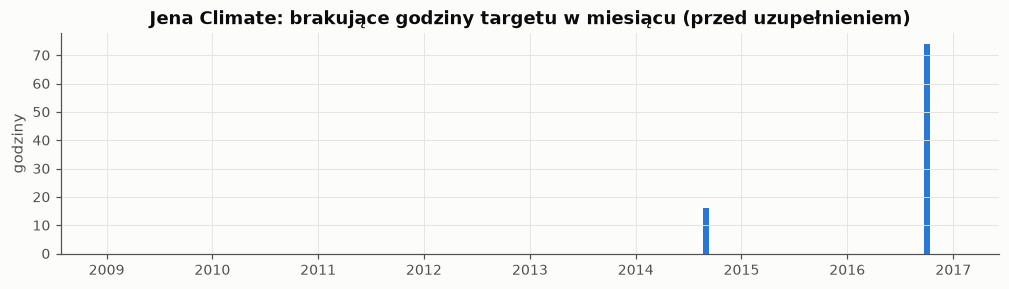

In [6]:
h = td.to_working_freq(clean, spec)
print('Kroki robocze:', len(h), '| kolumny:', list(h.columns))
display(td.save_table(td.gap_summary(h[spec.target], 3, spec.step_word), OUT, 'jena_luki', index=False))
h_f, filled = td.fill_short_gaps(h, max_gap=3)
print(f'Kroki uzupełnione (dowolna kolumna): {int(filled.sum())} ({100 * filled.mean():.2f}%)')
display(td.save_table(td.data_accounting(raw, clean, h, h_f, spec), OUT, 'jena_bilans_danych', index=False))
td.plot_missing(h, spec, OUT); plt.show()
split = td.chronological_split(h_f.index, spec)   # granice podziału: sekcja 2
D['jena'] = dict(spec=spec, h_f=h_f, split=split, raw_rows=len(raw), reg=reg, anom=anom,
                  range=f"{raw['time'].min():%Y-%m-%d} – {raw['time'].max():%Y-%m-%d}",
                  miss_after=h[spec.target].isna().mean(), miss_final=h_f[spec.target].isna().mean())
del raw, clean

**Przebieg szeregu.** Cały szereg (opisowo; szare pasy oznaczają zbiór walidacyjny i testowy) oraz fragment zbioru uczącego.

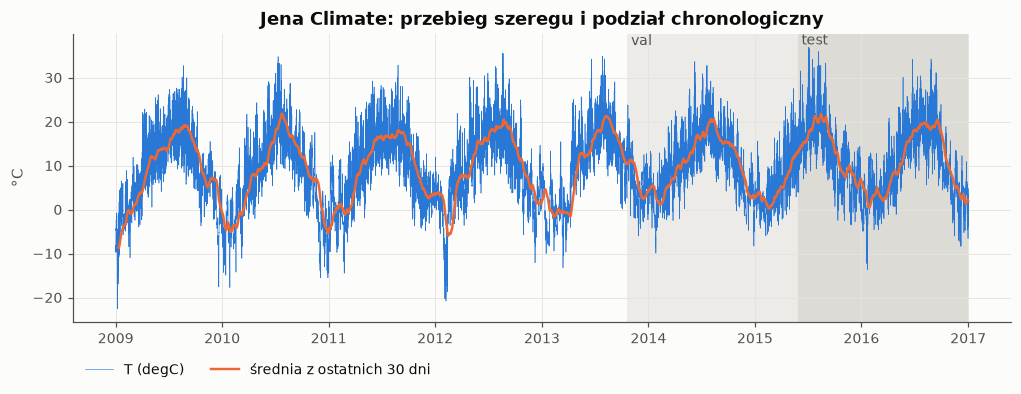

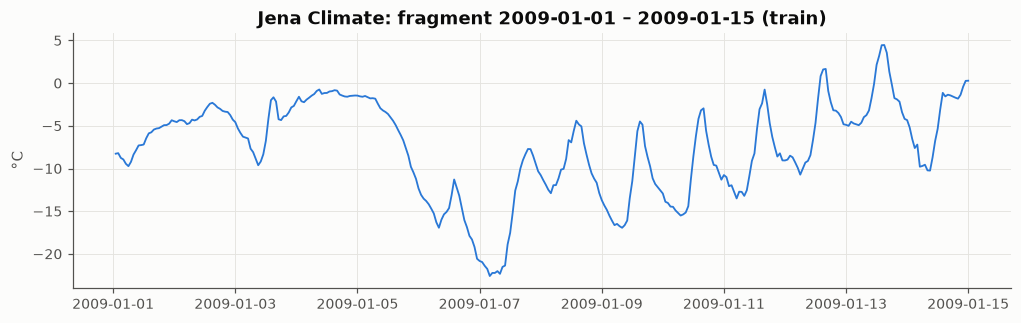

In [7]:
td.plot_series(D['jena']['h_f'], D['jena']['split'], spec, OUT); plt.show()
td.plot_zoom(D['jena']['h_f'][spec.target], D['jena']['h_f'].index[0], 24 * 14, spec, OUT); plt.show()

**Komentarz.** Plik nie jest posortowany chronologicznie, więc sortujemy go przed przetwarzaniem. 327 nadmiarowych wierszy o powtórzonym czasie ma identyczne wartości we wszystkich kolumnach, dlatego łączymy je bez utraty informacji. Siatce 10-minutowej brakuje 544 punktów (najdłuższa przerwa: 3 dni 2 h 20 min). Wartość −9999 w `wv` (18 razy) i `max. wv` (20 razy) jest kodem braku i zamieniamy ją na brak. Temperatura nie ma braków w pliku; po agregacji 90 godzin bez targetu tworzy dwie długie luki (16 h w 2014 r. w zbiorze walidacyjnym i 74 h w 2016 r. w testowym), których nie uzupełniamy. Zbiór uczący jest kompletny.

Przebieg pokazuje silny cykl roczny (średnia 30-dniowa od ok. −5 do ok. 20 °C) bez trendu długookresowego. We fragmencie zbioru uczącego (pierwsze dwa tygodnie 2009 r.) widać cykl dobowy, który w pierwszych dniach przesłaniają zmiany pogody (spadek do ok. −22 °C 7 stycznia). Anomalie wartości (−9999) dotyczą tylko wiatru, nie targetu.

### 1.2 Household Power Consumption

Pomiary zużycia energii w jednym gospodarstwie domowym w Sceaux pod Paryżem, zapisywane co minutę. Braki są oznaczone w pliku znakiem `?`. Target: moc czynna `Global_active_power` (kW).

Decyzje agregacji: moce, napięcie i natężenie uśredniamy; podliczniki `Sub_metering_1–3` to energia w Wh na minutę, więc energię w godzinie liczymy jako średnią z dostępnych minut × 60. Przy pełnej godzinie jest to dokładnie suma; przy godzinie niepełnej (50–99% minut) jest to oszacowanie z korektą na brakujące minuty, bo zwykła suma zaniżałaby energię. Liczbę takich godzin podaje tabela bilansu danych. Podliczniki sumują się z mocą całkowitą w tej samej chwili, dlatego w modelach mogą występować tylko z przeszłości okna.

In [8]:
spec = td.SPECS['household']
raw = td.load_raw('household', DATA)
print('Wiersze surowe:', len(raw), '| zakres:', raw['time'].min(), '–', raw['time'].max())
display(raw.head())
td.save_table(raw.describe().T.round(3), OUT, 'household_statystyki')

Wiersze surowe: 2075259 | zakres: 2006-12-16 17:24:00 – 2010-11-26 21:02:00


,time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,2006-12-16 17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,2006-12-16 17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,2006-12-16 17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,2006-12-16 17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,2006-12-16 17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


,count,mean,min,25%,50%,75%,max,std
time,2075259,2008-12-06 07:13:00,2006-12-16 17:24:00,2007-12-12 00:18:30,2008-12-06 07:13:00,2009-12-01 14:07:30,2010-11-26 21:02:00,NaN
Global_active_power,2049280.0,1.091615,0.076,0.308,0.602,1.528,11.122,1.057294
Global_reactive_power,2049280.0,0.123714,0.0,0.048,0.1,0.194,1.39,0.112722
Voltage,2049280.0,240.839858,223.2,238.99,241.01,242.89,254.15,3.239987
Global_intensity,2049280.0,4.627759,0.2,1.4,2.6,6.4,48.4,4.444396
Sub_metering_1,2049280.0,1.121923,0.0,0.0,0.0,0.0,88.0,6.153031
Sub_metering_2,2049280.0,1.29852,0.0,0.0,0.0,1.0,80.0,5.822026
Sub_metering_3,2049280.0,6.458447,0.0,0.0,1.0,17.0,31.0,8.437154


**Jakość danych surowych.** Regularność znaczników czasu, braki w kolumnach, duplikaty oraz wartości fizycznie niemożliwe (reguły ustalone z góry, a nie dopasowywane do danych; takie wartości zamieniamy na braki).

In [9]:
reg = td.raw_regularity(raw, spec)
display(td.save_table(reg.to_frame('wartość'), OUT, 'household_regularnosc'))
display(td.save_table(td.missing_table(raw), OUT, 'household_braki_kolumny'))
dup = td.duplicate_report(raw, spec)
if len(dup):
    print('Grupy zduplikowanych znaczników czasu:', dup.attrs.get('grupy duplikatów'))
    display(td.save_table(dup, OUT, 'household_duplikaty', index=False))
else:
    print('Brak zduplikowanych znaczników czasu.')
clean, anom = td.apply_anomaly_rules(raw, 'household')
td.save_table(anom, OUT, 'household_anomalie', index=False)

,wartość
wiersze,2075259
unikalne znaczniki czasu,2075259
wiersze ze zduplikowanym czasem,0
nadmiarowe wiersze (duplikaty),0
posortowane rosnąco,True
początek,2006-12-16 17:24:00
koniec,2010-11-26 21:02:00
oczekiwane punkty siatki,2075259
brakujące punkty siatki,0
znaczniki poza siatką,0


,braki,braki %
kolumna,,
time,0,0.000
Global_active_power,25979,1.252
Global_reactive_power,25979,1.252
Voltage,25979,1.252
Global_intensity,25979,1.252
Sub_metering_1,25979,1.252
Sub_metering_2,25979,1.252
Sub_metering_3,25979,1.252


Brak zduplikowanych znaczników czasu.


,kolumna,reguła,liczba,%,przykładowe wartości
0,Global_active_power,moc czynna < 0,0,0.0,
1,Global_reactive_power,moc bierna < 0,0,0.0,
2,Global_intensity,natężenie < 0,0,0.0,
3,Voltage,"napięcie poza [180, 280] V",0,0.0,


**Agregacja do 1 h i luki.** Godzinę uznajemy za brakującą, gdy brakuje w niej ponad połowy pomiarów targetu. Luki do 3 h uzupełniamy ostatnią znaną wartością; dłuższe zostają, a okna, które je przecinają, są pomijane (sekcja 3). Tabela bilansu pokazuje, ile wierszy połączono, ile wartości usunięto jako niemożliwe, ile kroków uzupełniono i ile braków zostało.

Kroki robocze: 34589 | kolumny: ['Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3', 'coverage']


,długość luki,liczba luk,brakujące kroki,uzupełniana
0,1 h,5,5,tak (ffill)
1,2–3 h,1,2,tak (ffill)
2,4–24 h,1,15,nie
3,> 24 h,6,411,nie


Kroki uzupełnione (dowolna kolumna): 7 (0.02%)


,etap,pozycja,liczba
0,dane surowe,wiersze,2075259
1,dane surowe,nadmiarowe wiersze o powtórzonym czasie (połąc...,0
2,dane surowe,grupy duplikatów ze sprzecznym targetem (targe...,0
3,dane surowe,braki targetu w pliku,25979
4,dane surowe,wartości targetu usunięte jako niemożliwe,0
5,szereg roboczy,kroki na regularnej siatce (h),34589
6,szereg roboczy,kroki z niepełnym pokryciem 50–99% (wartość z ...,72
7,szereg roboczy,kroki bez targetu po agregacji,433
8,szereg roboczy,kroki targetu uzupełnione (luki ≤ 3),7
9,szereg roboczy,kroki bez targetu po uzupełnieniu (długie luki),426


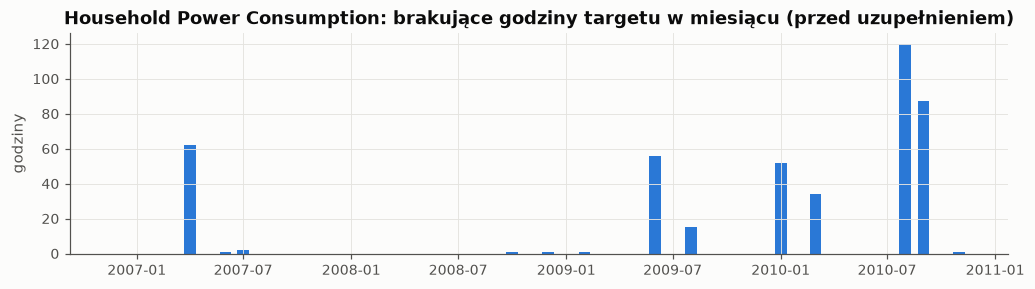

In [10]:
h = td.to_working_freq(clean, spec)
print('Kroki robocze:', len(h), '| kolumny:', list(h.columns))
display(td.save_table(td.gap_summary(h[spec.target], 3, spec.step_word), OUT, 'household_luki', index=False))
h_f, filled = td.fill_short_gaps(h, max_gap=3)
print(f'Kroki uzupełnione (dowolna kolumna): {int(filled.sum())} ({100 * filled.mean():.2f}%)')
display(td.save_table(td.data_accounting(raw, clean, h, h_f, spec), OUT, 'household_bilans_danych', index=False))
td.plot_missing(h, spec, OUT); plt.show()
split = td.chronological_split(h_f.index, spec)   # granice podziału: sekcja 2
D['household'] = dict(spec=spec, h_f=h_f, split=split, raw_rows=len(raw), reg=reg, anom=anom,
                  range=f"{raw['time'].min():%Y-%m-%d} – {raw['time'].max():%Y-%m-%d}",
                  miss_after=h[spec.target].isna().mean(), miss_final=h_f[spec.target].isna().mean())
del raw, clean

**Przebieg szeregu.** Cały szereg (opisowo; szare pasy oznaczają zbiór walidacyjny i testowy) oraz fragment zbioru uczącego.

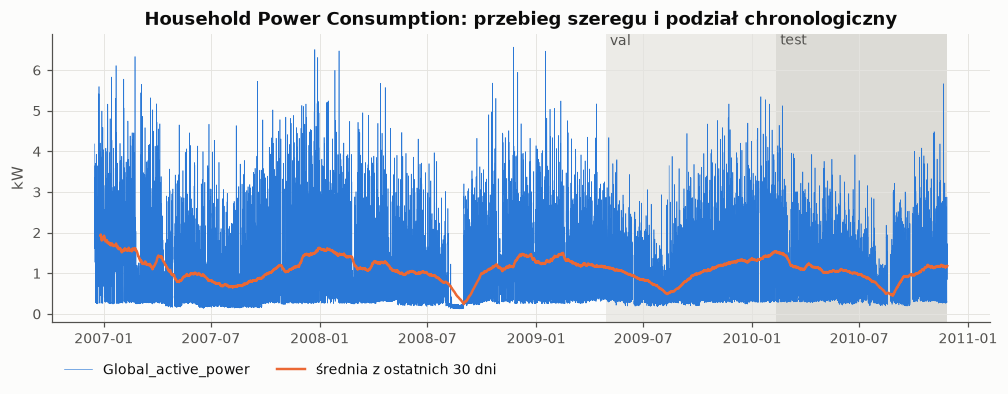

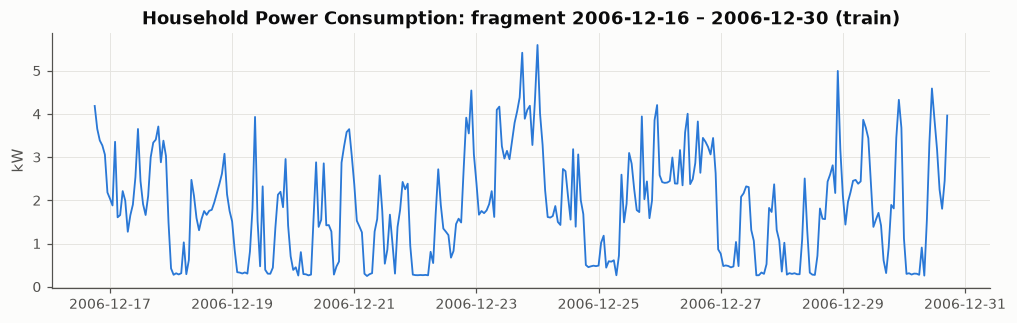

In [11]:
td.plot_series(D['household']['h_f'], D['household']['split'], spec, OUT); plt.show()
td.plot_zoom(D['household']['h_f'][spec.target], D['household']['h_f'].index[0], 24 * 14, spec, OUT); plt.show()

**Komentarz.** Siatka minutowa jest kompletna i bez duplikatów, ale w 25 979 minutach (1,25%) wszystkie kolumny pomiarowe mają jednocześnie wartość `?`, co oznacza przerwy w rejestracji. Reguły fizyczne nie wykrywają wartości niemożliwych. Po agregacji brakuje 433 godzin targetu: 7 kroków w krótkich lukach uzupełniamy, a 426 godzin w siedmiu długich lukach (jedna 15 h i sześć dłuższych niż doba) pozostaje. Braki przybywają w późniejszych latach (train 62 h, val 123 h, test 241 h).

Szereg jest silnie zaszumiony i nie ma trendu. Widoczny jest cykl roczny z wyraźnym spadkiem zużycia w sierpniu (w sierpniu 2008 r. prawie do poziomu stałego obciążenia), związany najpewniej z wyjazdami wakacyjnymi. Minutowe szczyty mocy do 11,1 kW są skrajne, ale możliwe, więc je zostawiamy.

### 1.3 Metro Interstate Traffic Volume

Godzinowe natężenie ruchu na autostradzie I-94 (Minneapolis–St Paul) wraz z pogodą i świętami. Target: `traffic_volume` (pojazdy/h).

Decyzje: UCI deklaruje brak braków, ale ciągłość siatki godzinowej i duplikaty sprawdzamy sami (czas lokalny, zmiana czasu letniego). Kilka wierszy dla jednej godziny (różne raporty pogodowe) łączymy w jeden: natężenie ruchu przyjmujemy, gdy we wszystkich wierszach jest identyczne, a gdy jest sprzeczne, godzinę traktujemy jako brak (nie sumujemy i nie uśredniamy ruchu); zmienne pogodowe liczbowe uśredniamy, a typ pogody kodujemy one-hot (maksimum). Temperaturę przeliczamy z K na °C. Święto jest znane z wyprzedzeniem, więc flagę `holiday` ustawiamy dla całej doby, a nie tylko dla godziny z wpisem.

In [12]:
spec = td.SPECS['metro']
raw = td.load_raw('metro', DATA)
print('Wiersze surowe:', len(raw), '| zakres:', raw['time'].min(), '–', raw['time'].max())
display(raw.head())
td.save_table(raw.describe().T.round(3), OUT, 'metro_statystyki')

Wiersze surowe: 48204 | zakres: 2012-10-02 09:00:00 – 2018-09-30 23:00:00


,time,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,traffic_volume
0,2012-10-02 09:00:00,<NA>,288.28,0.0,0.0,40,Clouds,scattered clouds,5545
1,2012-10-02 10:00:00,<NA>,289.36,0.0,0.0,75,Clouds,broken clouds,4516
2,2012-10-02 11:00:00,<NA>,289.58,0.0,0.0,90,Clouds,overcast clouds,4767
3,2012-10-02 12:00:00,<NA>,290.13,0.0,0.0,90,Clouds,overcast clouds,5026
4,2012-10-02 13:00:00,<NA>,291.14,0.0,0.0,75,Clouds,broken clouds,4918


,count,mean,min,25%,50%,75%,max,std
time,48204,2016-01-05 10:46:16.773711,2012-10-02 09:00:00,2014-02-06 11:45:00,2016-06-11 03:30:00,2017-08-11 06:00:00,2018-09-30 23:00:00,NaN
temp,48204.0,281.20587,0.0,272.16,282.45,291.806,310.07,13.338232
rain_1h,48204.0,0.334264,0.0,0.0,0.0,0.0,9831.3,44.789133
snow_1h,48204.0,0.000222,0.0,0.0,0.0,0.0,0.51,0.008168
clouds_all,48204.0,49.362231,0.0,1.0,64.0,90.0,100.0,39.01575
traffic_volume,48204.0,3259.818355,0.0,1193.0,3380.0,4933.0,7280.0,1986.86067


**Jakość danych surowych.** Regularność znaczników czasu, braki w kolumnach, duplikaty oraz wartości fizycznie niemożliwe (reguły ustalone z góry, a nie dopasowywane do danych; takie wartości zamieniamy na braki).

In [13]:
reg = td.raw_regularity(raw, spec)
display(td.save_table(reg.to_frame('wartość'), OUT, 'metro_regularnosc'))
display(td.save_table(td.missing_table(raw), OUT, 'metro_braki_kolumny'))
dup = td.duplicate_report(raw, spec)
if len(dup):
    print('Grupy zduplikowanych znaczników czasu:', dup.attrs.get('grupy duplikatów'))
    display(td.save_table(dup, OUT, 'metro_duplikaty', index=False))
else:
    print('Brak zduplikowanych znaczników czasu.')
clean, anom = td.apply_anomaly_rules(raw, 'metro')
td.save_table(anom, OUT, 'metro_anomalie', index=False)

,wartość
wiersze,48204
unikalne znaczniki czasu,40575
wiersze ze zduplikowanym czasem,13074
nadmiarowe wiersze (duplikaty),7629
posortowane rosnąco,True
początek,2012-10-02 09:00:00
koniec,2018-09-30 23:00:00
oczekiwane punkty siatki,52551
brakujące punkty siatki,11976
znaczniki poza siatką,0


,braki,braki %
kolumna,,
time,0,0.000
holiday,48143,99.873
temp,0,0.000
rain_1h,0,0.000
snow_1h,0,0.000
clouds_all,0,0.000
weather_main,0,0.000
weather_description,0,0.000
traffic_volume,0,0.000


Grupy zduplikowanych znaczników czasu: 5445


,kolumna,grupy z różnymi wartościami
0,holiday,0
1,temp,78
2,rain_1h,9
3,snow_1h,0
4,clouds_all,32
5,weather_main,5349
6,weather_description,5386
7,traffic_volume,0


,kolumna,reguła,liczba,%,przykładowe wartości
0,temp,temperatura ≤ 0 K,10,0.0207,0.0
1,rain_1h,opad > 300 mm/h (powyżej rekordu świata),1,0.0021,9831.3
2,snow_1h,opad śniegu < 0,0,0.0000,
3,clouds_all,"zachmurzenie poza [0, 100] %",0,0.0000,
4,traffic_volume,natężenie ruchu < 0,0,0.0000,


**Agregacja do 1 h i luki.** Godzinę uznajemy za brakującą, gdy brakuje w niej ponad połowy pomiarów targetu. Luki do 3 h uzupełniamy ostatnią znaną wartością; dłuższe zostają, a okna, które je przecinają, są pomijane (sekcja 3). Tabela bilansu pokazuje, ile wierszy połączono, ile wartości usunięto jako niemożliwe, ile kroków uzupełniono i ile braków zostało.

Kroki robocze: 52551 | kolumny: ['temp (degC)', 'rain_1h', 'snow_1h', 'clouds_all', 'traffic_volume', 'w_Clear', 'w_Clouds', 'w_Drizzle', 'w_Fog', 'w_Haze', 'w_Mist', 'w_Rain', 'w_Smoke', 'w_Snow', 'w_Squall', 'w_Thunderstorm', 'holiday', 'coverage']


,długość luki,liczba luk,brakujące kroki,uzupełniana
0,1 h,2192,2192,tak (ffill)
1,2–3 h,260,579,tak (ffill)
2,4–24 h,125,1019,nie
3,> 24 h,11,8186,nie


Kroki uzupełnione (dowolna kolumna): 2772 (5.27%)


,etap,pozycja,liczba
0,dane surowe,wiersze,48204
1,dane surowe,nadmiarowe wiersze o powtórzonym czasie (połąc...,7629
2,dane surowe,grupy duplikatów ze sprzecznym targetem (targe...,0
3,dane surowe,braki targetu w pliku,0
4,dane surowe,wartości targetu usunięte jako niemożliwe,0
5,szereg roboczy,kroki na regularnej siatce (h),52551
6,szereg roboczy,kroki z niepełnym pokryciem 50–99% (wartość z ...,0
7,szereg roboczy,kroki bez targetu po agregacji,11976
8,szereg roboczy,kroki targetu uzupełnione (luki ≤ 3),2771
9,szereg roboczy,kroki bez targetu po uzupełnieniu (długie luki),9205


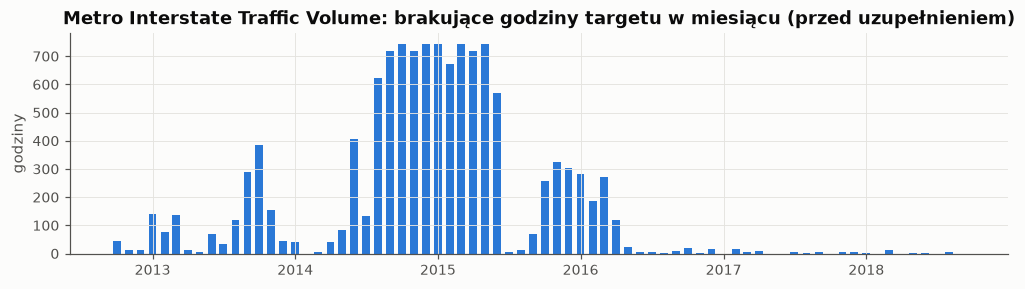

In [14]:
h = td.to_working_freq(clean, spec)
print('Kroki robocze:', len(h), '| kolumny:', list(h.columns))
display(td.save_table(td.gap_summary(h[spec.target], 3, spec.step_word), OUT, 'metro_luki', index=False))
h_f, filled = td.fill_short_gaps(h, max_gap=3)
print(f'Kroki uzupełnione (dowolna kolumna): {int(filled.sum())} ({100 * filled.mean():.2f}%)')
display(td.save_table(td.data_accounting(raw, clean, h, h_f, spec), OUT, 'metro_bilans_danych', index=False))
td.plot_missing(h, spec, OUT); plt.show()
split = td.chronological_split(h_f.index, spec)   # granice podziału: sekcja 2
D['metro'] = dict(spec=spec, h_f=h_f, split=split, raw_rows=len(raw), reg=reg, anom=anom,
                  range=f"{raw['time'].min():%Y-%m-%d} – {raw['time'].max():%Y-%m-%d}",
                  miss_after=h[spec.target].isna().mean(), miss_final=h_f[spec.target].isna().mean())
del raw, clean

**Przebieg szeregu.** Cały szereg (opisowo; szare pasy oznaczają zbiór walidacyjny i testowy) oraz fragment zbioru uczącego.

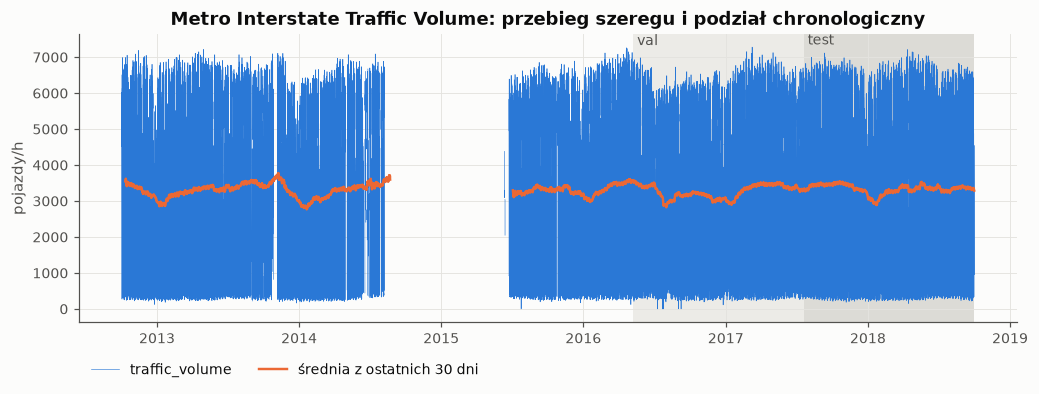

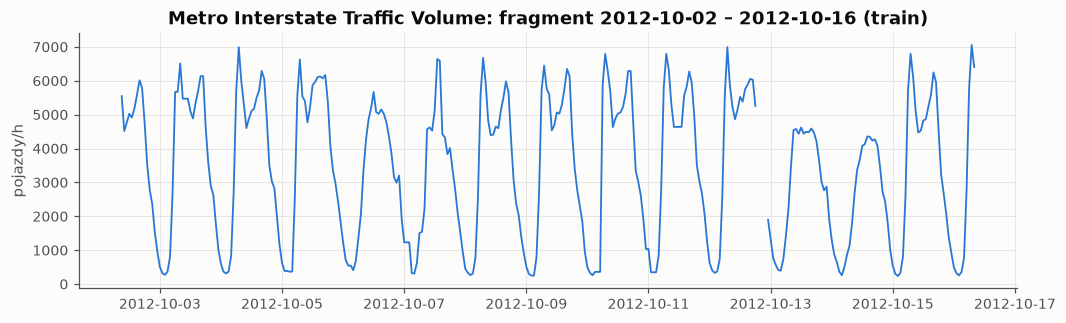

In [15]:
td.plot_series(D['metro']['h_f'], D['metro']['split'], spec, OUT); plt.show()
td.plot_zoom(D['metro']['h_f'][spec.target], D['metro']['h_f'].index[0], 24 * 14, spec, OUT); plt.show()

**Komentarz.** UCI deklaruje brak braków, ale kontrola siatki pokazuje 11 976 brakujących godzin (22,8%) i przerwę 307 dni 19 h (sierpień 2014 – czerwiec 2015). 7 629 nadmiarowych wierszy w 5 445 grupach to różne raporty pogody dla tej samej godziny (typ pogody różni się w 5 349 grupach); natężenie ruchu jest w każdej grupie identyczne, więc żadnej godziny nie unieważniamy. Dziesięć temperatur 0 K i jeden opad 9831,3 mm/h zamieniamy na braki. Uzupełniamy 2 771 kroków w lukach do 3 h (5,3% szeregu); po uzupełnieniu brakuje 17,52% godzin targetu, prawie wyłącznie w zbiorze uczącym (9 173 h).

Poziom szeregu jest stabilny (30-dniowa średnia ok. 3000–3500 pojazdów/h), bez trendu. We fragmencie zbioru uczącego widać cykl dobowy z dwoma szczytami w dni robocze i niższy, jednoszczytowy przebieg w weekend (13–14 października 2012 r.) oraz krótką lukę 12–13 października.

### 1.4 Air Passengers

Klasyczny szereg Boxa i Jenkinsa: miesięczna liczba pasażerów linii międzynarodowych (tys.), 1949–1960, 144 obserwacje. Jest to jedyna zmienna, więc wariant wielowymiarowy nie dotyczy tego zbioru.

In [16]:
spec = td.SPECS['air']
raw = td.load_raw('air', DATA)
print('Wiersze surowe:', len(raw), '| zakres:', raw['time'].min(), '–', raw['time'].max())
display(raw.head())
td.save_table(raw.describe().T.round(3), OUT, 'air_statystyki')

Wiersze surowe: 144 | zakres: 1949-01-01 00:00:00 – 1960-12-01 00:00:00


,time,passengers
0,1949-01-01,112.0
1,1949-02-01,118.0
2,1949-03-01,132.0
3,1949-04-01,129.0
4,1949-05-01,121.0


,count,mean,min,25%,50%,75%,max,std
time,144,1954-12-16 05:00:00,1949-01-01 00:00:00,1951-12-24 06:00:00,1954-12-16 12:00:00,1957-12-08 18:00:00,1960-12-01 00:00:00,NaN
passengers,144.0,280.298611,104.0,180.0,265.5,360.5,622.0,119.966317


**Jakość danych surowych.** Regularność znaczników czasu, braki w kolumnach, duplikaty oraz wartości fizycznie niemożliwe (reguły ustalone z góry, a nie dopasowywane do danych; takie wartości zamieniamy na braki).

In [17]:
reg = td.raw_regularity(raw, spec)
display(td.save_table(reg.to_frame('wartość'), OUT, 'air_regularnosc'))
display(td.save_table(td.missing_table(raw), OUT, 'air_braki_kolumny'))
dup = td.duplicate_report(raw, spec)
if len(dup):
    print('Grupy zduplikowanych znaczników czasu:', dup.attrs.get('grupy duplikatów'))
    display(td.save_table(dup, OUT, 'air_duplikaty', index=False))
else:
    print('Brak zduplikowanych znaczników czasu.')
clean, anom = td.apply_anomaly_rules(raw, 'air')
td.save_table(anom, OUT, 'air_anomalie', index=False)

,wartość
wiersze,144
unikalne znaczniki czasu,144
wiersze ze zduplikowanym czasem,0
nadmiarowe wiersze (duplikaty),0
posortowane rosnąco,True
początek,1949-01-01 00:00:00
koniec,1960-12-01 00:00:00
oczekiwane punkty siatki,144
brakujące punkty siatki,0
najczęstszy krok,31 days 00:00:00


,braki,braki %
kolumna,,
time,0,0.0
passengers,0,0.0


Brak zduplikowanych znaczników czasu.


,kolumna,reguła,liczba,%,przykładowe wartości
0,passengers,liczba pasażerów ≤ 0,0,0.0,


**Siatka miesięczna i luki.**

In [18]:
h = td.to_working_freq(clean, spec)
print('Kroki robocze:', len(h), '| kolumny:', list(h.columns))
display(td.save_table(td.gap_summary(h[spec.target], 3, spec.step_word), OUT, 'air_luki', index=False))
h_f, filled = td.fill_short_gaps(h, max_gap=3)
print(f'Kroki uzupełnione (dowolna kolumna): {int(filled.sum())} ({100 * filled.mean():.2f}%)')
display(td.save_table(td.data_accounting(raw, clean, h, h_f, spec), OUT, 'air_bilans_danych', index=False))
split = td.chronological_split(h_f.index, spec)   # granice podziału: sekcja 2
D['air'] = dict(spec=spec, h_f=h_f, split=split, raw_rows=len(raw), reg=reg, anom=anom,
                  range=f"{raw['time'].min():%Y-%m-%d} – {raw['time'].max():%Y-%m-%d}",
                  miss_after=h[spec.target].isna().mean(), miss_final=h_f[spec.target].isna().mean())
del raw, clean

Kroki robocze: 144 | kolumny: ['passengers', 'coverage']


,długość luki,liczba luk,brakujące kroki,uzupełniana
0,1 mies.,0,0,tak (ffill)
1,2–3 mies.,0,0,tak (ffill)
2,4–24 mies.,0,0,nie
3,> 24 mies.,0,0,nie


Kroki uzupełnione (dowolna kolumna): 0 (0.00%)


,etap,pozycja,liczba
0,dane surowe,wiersze,144
1,dane surowe,nadmiarowe wiersze o powtórzonym czasie (połąc...,0
2,dane surowe,grupy duplikatów ze sprzecznym targetem (targe...,0
3,dane surowe,braki targetu w pliku,0
4,dane surowe,wartości targetu usunięte jako niemożliwe,0
5,szereg roboczy,kroki na regularnej siatce (MS),144
6,szereg roboczy,kroki z niepełnym pokryciem 50–99% (wartość z ...,0
7,szereg roboczy,kroki bez targetu po agregacji,0
8,szereg roboczy,kroki targetu uzupełnione (luki ≤ 3),0
9,szereg roboczy,kroki bez targetu po uzupełnieniu (długie luki),0


**Przebieg szeregu.** Cały szereg (opisowo; szare pasy oznaczają zbiór walidacyjny i testowy) oraz fragment zbioru uczącego.

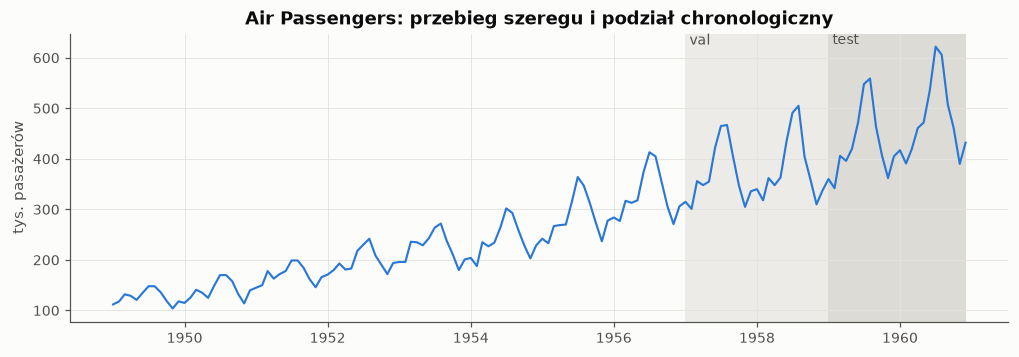

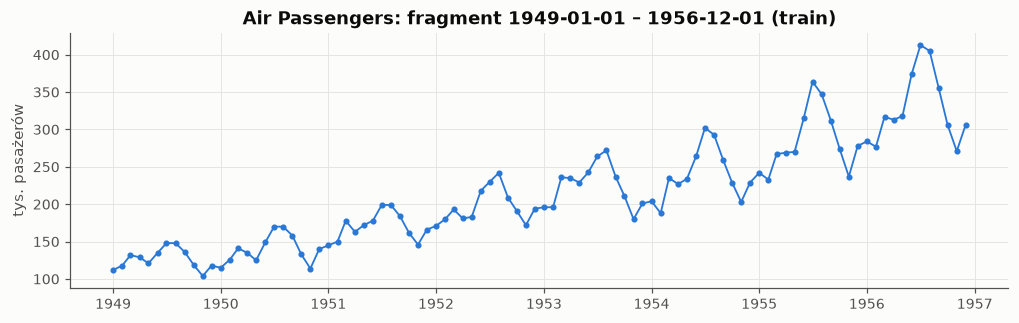

In [19]:
td.plot_series(D['air']['h_f'], D['air']['split'], spec, OUT); plt.show()
td.plot_zoom(D['air']['h_f'][spec.target], D['air']['h_f'].index[0], 96, spec, OUT); plt.show()

**Komentarz.** Szereg jest kompletny: 144 miesiące bez braków, duplikatów i wartości niemożliwych. Ma silny trend rosnący (od 104 do 622 tys. pasażerów) i sezonowość roczną z maksimum latem. Amplituda wahań rośnie wraz z poziomem, co wskazuje na sezonowość multiplikatywną i uzasadnia użycie różnic logarytmu w analizie autokorelacji (sekcja 3.1).

## 2. Chronologiczny podział i skalowanie

Każdy szereg dzielimy chronologicznie, bez losowania. Dla trzech zbiorów godzinowych granice wypadają na 60% i 80% osi czasu, zaokrąglone do północy; dla Air Passengers podział jest wyrównany do pełnych lat (1949–1956 / 1957–1958 / 1959–1960), aby każdy zbiór zawierał całe cykle roczne. Skalowanie (`StandardScaler`) dopasowujemy wyłącznie do zbioru uczącego i stosujemy bez zmian do zbiorów walidacyjnego i testowego. Kolumny binarne (typ pogody, święto) pozostają bez skalowania.

In [20]:
split_rows = []
for key in td.SPECS:
    d = D[key]; spec = d['spec']
    ends = {s: d['h_f'].index[d['split'] == s] for s in td.SPLITS}
    assert ends['train'].max() < ends['val'].min() and ends['val'].max() < ends['test'].min(), 'zbiory muszą być rozłączne w czasie'
    t = td.split_table(d['h_f'], d['split'], spec); t.insert(0, 'zbiór danych', spec.name)
    split_rows.append(t)
td.save_table(pd.concat(split_rows), OUT, 'podzial', index=False)

,zbiór danych,zbiór,od,do,kroki,udział %,braki targetu,średnia,odch. std.
0,Jena Climate,train,2009-01-01 01:00:00,2013-10-19 23:00:00,42071,60.0,0,8.994,8.821
1,Jena Climate,val,2013-10-20 00:00:00,2015-05-26 23:00:00,14016,20.0,16,8.941,7.117
2,Jena Climate,test,2015-05-27 00:00:00,2017-01-01 00:00:00,14041,20.0,74,11.295,8.100
0,Household Power Consumption,train,2006-12-16 18:00:00,2009-04-28 23:00:00,20742,60.0,62,1.131,0.960
1,Household Power Consumption,val,2009-04-29 00:00:00,2010-02-10 23:00:00,6912,20.0,123,1.057,0.835
2,Household Power Consumption,test,2010-02-11 00:00:00,2010-11-26 22:00:00,6935,20.0,241,1.005,0.736
0,Metro Interstate Traffic Volume,train,2012-10-02 09:00:00,2016-05-07 23:00:00,31527,60.0,9173,3306.892,2015.504
1,Metro Interstate Traffic Volume,val,2016-05-08 00:00:00,2017-07-19 23:00:00,10512,20.0,26,3258.336,1931.416
2,Metro Interstate Traffic Volume,test,2017-07-20 00:00:00,2018-09-30 23:00:00,10512,20.0,6,3345.886,1985.683
0,Air Passengers,train,1949-01-01 00:00:00,1956-12-01 00:00:00,96,66.7,0,213.708,71.918


**Skalowanie.** Parametry skalera (średnia i odchylenie standardowe targetu) pochodzą wyłącznie ze zbioru uczącego. Po skalowaniu zbiór uczący ma średnią 0 i odchylenie 1 z definicji; odchylenia tych wartości w walidacji i teście pokazują, jak bardzo rozkład późniejszych danych różni się od uczącego (np. przez trend).

In [21]:
scale_rows = []
for key in td.SPECS:
    d = D[key]; spec = d['spec']
    cols = td.feature_columns(d['h_f'], spec)
    scaler, cont = td.fit_scaler(d['h_f'], d['split'], cols)
    d.update(cols=cols, scaler=scaler, cont=cont, h_s=td.apply_scaler(d['h_f'], cols, scaler, cont))
    t = td.scaling_table(d['h_s'], d['split'], scaler, cont, spec).T; t.insert(0, 'zbiór danych', spec.name)
    scale_rows.append(t)
td.save_table(pd.concat(scale_rows), OUT, 'skalowanie', index=False)

,zbiór danych,średnia z train (skaler),odch. std. z train (skaler),train: średnia po skalowaniu,train: odch. std. po skalowaniu,val: średnia po skalowaniu,val: odch. std. po skalowaniu,test: średnia po skalowaniu,test: odch. std. po skalowaniu
T (degC),Jena Climate,8.9944,8.8211,0.0,1.000,-0.006,0.807,0.261,0.918
Global_active_power,Household Power Consumption,1.1312,0.9603,-0.0,1.000,-0.078,0.869,-0.132,0.766
traffic_volume,Metro Interstate Traffic Volume,3307.7816,2015.2380,-0.0,1.000,-0.025,0.958,0.019,0.985
passengers,Air Passengers,213.7083,71.5427,-0.0,1.005,2.250,0.843,3.334,1.066


**Komentarz.** Wszystkie zbiory są rozłączne w czasie (asercja przechodzi). Rozkład targetu w walidacji i teście porównujemy ze zbiorem uczącym na podstawie wartości po skalowaniu:

- **Jena Climate:** średnia testowa jest wyższa o 0,26 odchylenia (11,30 wobec 8,99 °C), bo test obejmuje lata 2015 i 2016, ale tylko jedną pełną zimę; jest to efekt składu sezonowego, a nie trendu.
- **Household Power Consumption:** późniejsze dane mają niższą średnią i mniejszą zmienność (test: −0,13 / 0,77), więc błędy bezwzględne na teście mogą być mniejsze niezależnie od modelu.
- **Metro Interstate Traffic Volume:** rozkład jest stabilny we wszystkich częściach (średnie po skalowaniu −0,03 i 0,02).
- **Air Passengers:** średnia walidacyjna leży 2,25, a testowa 3,33 odchylenia powyżej uczącej. Maksimum zbioru uczącego (413 tys.) przekracza 25% miesięcy walidacyjnych i 62,5% testowych. Sieci uczone na poziomach musiałyby więc ekstrapolować poza zakres uczenia, co grozi niedoszacowaniem; persistence i seasonal naive nie mają tego problemu. Dlatego zgodnie z protokołem sieci dla tego zbioru uczymy na logarytmie wartości (wariant podstawowy) i na różnicach sezonowych z lagiem 12 (wariant kontrolny), z wyborem na walidacji. Logarytm zmniejsza przesunięcie, ale go nie usuwa (po standaryzacji logarytmu: walidacja 1,81, test 2,37 odchylenia). Prognozy walidacyjne sprawdzimy pod kątem niedoszacowania w Raporcie 2.

Odchylenie zbioru uczącego Air Passengers po skalowaniu wynosi 1,005, a nie 1, bo skaler używa odchylenia populacyjnego, a tabela odchylenia z próby (n = 96).

### 2.1 Rozkład targetu w zbiorach uczącym, walidacyjnym i testowym

Porównujemy rozkład targetu (w oryginalnych jednostkach) w trzech częściach podziału. Statystyka Kołmogorowa–Smirnowa (KS) mierzy największą różnicę dystrybuant dwóch rozkładów: 0 oznacza rozkłady identyczne, 1 rozkłady całkowicie rozłączne. Kolumna „poza zakresem train” podaje odsetek wartości mniejszych od minimum lub większych od maksimum zbioru uczącego; takie wartości model musi ekstrapolować. Porównanie jest opisowe i nie wpływa na żadną decyzję modelową.

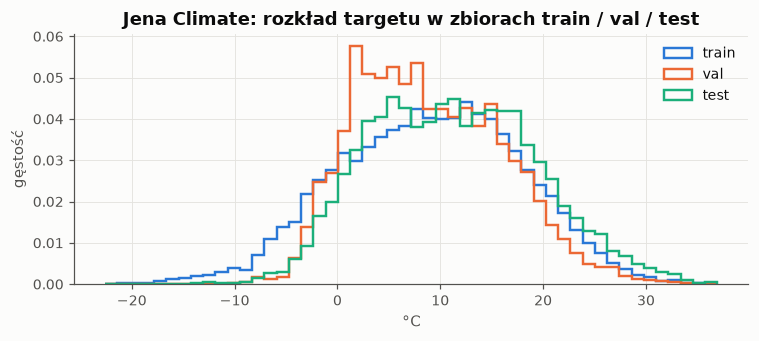

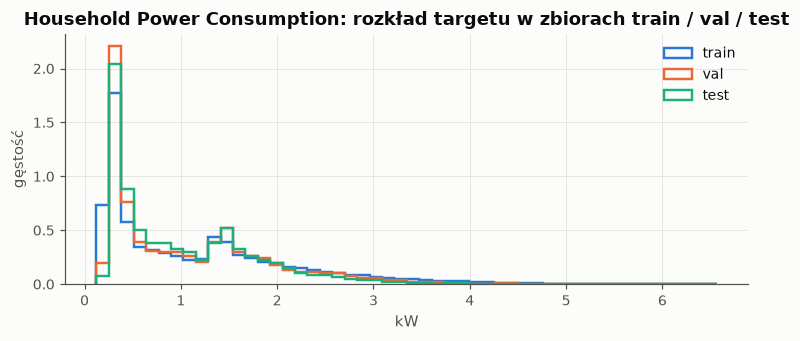

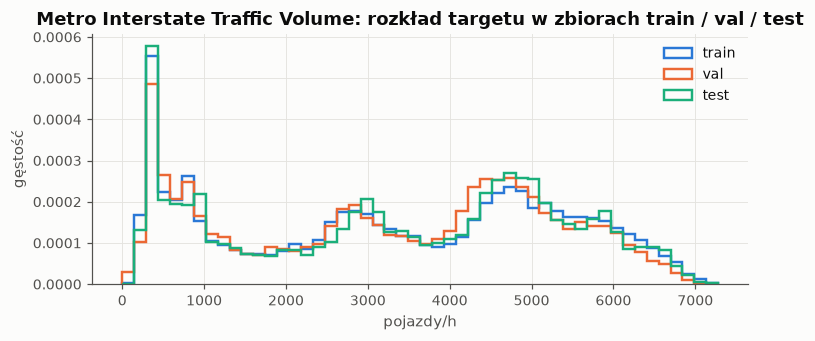

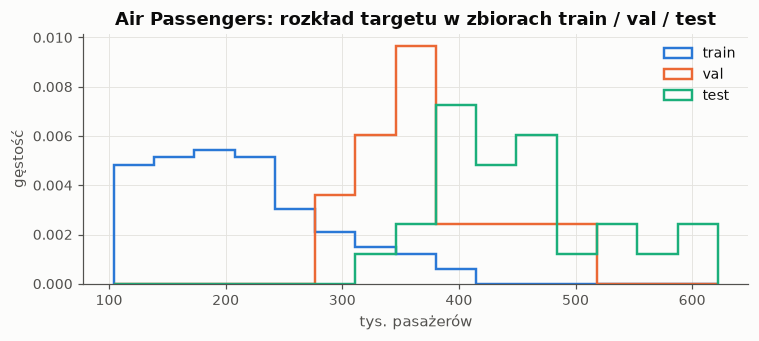

,zbiór danych,zbiór,n,średnia,odch. std.,min,kwantyl 5%,mediana,kwantyl 95%,max,KS vs train,poza zakresem train [%]
0,Jena Climate,train,42071,8.994,8.821,-22.592,-5.467,9.272,22.940,35.520,0.000,0.0
1,Jena Climate,val,14000,8.941,7.117,-9.900,-1.475,8.216,20.995,33.655,0.077,0.0
2,Jena Climate,test,13967,11.295,8.100,-13.655,-1.074,11.043,25.135,36.943,0.102,0.1
0,Household Power Consumption,train,20680,1.131,0.960,0.124,0.205,0.826,3.041,6.566,0.000,0.0
1,Household Power Consumption,val,6789,1.057,0.835,0.180,0.274,0.780,2.700,5.346,0.096,0.0
2,Household Power Consumption,test,6694,1.005,0.736,0.195,0.289,0.767,2.425,5.666,0.132,0.0
0,Metro Interstate Traffic Volume,train,22354,3306.892,2015.504,1.000,337.000,3412.000,6273.000,7260.000,0.000,0.0
1,Metro Interstate Traffic Volume,val,10486,3258.336,1931.416,0.000,349.000,3453.000,6091.000,7280.000,0.043,0.0
2,Metro Interstate Traffic Volume,test,10506,3345.886,1985.683,151.000,347.000,3536.500,6252.750,7213.000,0.029,0.0
0,Air Passengers,train,96,213.708,71.918,104.000,118.000,200.000,349.000,413.000,0.000,0.0


In [22]:
dist_rows = []
for key in td.SPECS:
    d = D[key]; spec = d['spec']
    t = td.split_distribution(d['h_f'], d['split'], spec); t.insert(0, 'zbiór danych', spec.name)
    dist_rows.append(t)
    d['dist'] = t
    td.plot_split_distribution(d['h_f'], d['split'], spec, OUT); plt.show()
td.save_table(pd.concat(dist_rows), OUT, 'rozklad_zbiorow', index=False)

**Komentarz.** Rozkłady trzech zbiorów godzinowych w walidacji i teście są bliskie rozkładowi uczącemu (statystyka KS najwyżej 0,13), a Air Passengers wyraźnie od niego odbiega:

- **Jena Climate:** średnie 8,99 / 8,94 / 11,30 °C (train / val / test), KS 0,077 i 0,102. Test jest cieplejszy o ok. 2,3 °C, a walidacja ma mniejszy rozrzut (odch. std. 7,12 wobec 8,82 °C), co wynika ze składu sezonowego tych lat (m.in. łagodniejsze zimy), a nie z trendu. Poza zakresem uczącym jest tylko 0,1% godzin testowych (maksimum testu 36,94 °C wobec 35,52 °C w train).
- **Household Power Consumption:** średnia i rozrzut maleją w czasie (1,131 → 1,057 → 1,005 kW; odch. std. 0,96 → 0,84 → 0,74 kW), KS 0,096 i 0,132, bez wartości poza zakresem uczącym. Późniejsze dane są „spokojniejsze”, więc błędy bezwzględne na walidacji i teście mogą być mniejsze niezależnie od modelu; porównania między okresami opieramy więc na skill score.
- **Metro Interstate Traffic Volume:** rozkład jest stabilny (średnie 3307 / 3258 / 3346 pojazdów/h, KS 0,043 i 0,029).
- **Air Passengers:** KS 0,854 (val) i 0,938 (test); 25% miesięcy walidacyjnych i 62,5% testowych leży powyżej maksimum zbioru uczącego (413 tys.). Jest to jedyny zbiór, w którym model musi ekstrapolować, co uzasadnia uczenie na logarytmie i różnicach sezonowych.

## 3. Okna czasowe

Funkcja `make_windows(data, window_size, horizon)` tworzy przykłady w postaci okna `L` kolejnych kroków (wejście, kroki t−L+1, …, t) i wartości targetu w chwili t + h (cel). Okna, w których wejście lub cel przecina dłuższą lukę, są pomijane. Przykład przypisujemy do zbioru według czasu celu; okno wejściowe może obejmować końcowe obserwacje poprzedniego zbioru, ponieważ w chwili prognozy były już znane.

Długość okna uzasadniamy autokorelacją i okresami sezonowymi wyznaczonymi na zbiorze uczącym (sekcja 3.1).

### 3.1 Sezonowość i autokorelacja na zbiorze uczącym

Rozkład targetu, profile sezonowe (średnia i kwartyle wg godziny, dnia tygodnia i miesiąca) oraz ACF liczymy tylko na zbiorze uczącym. Wysoka ACF poziomów może wynikać z samej bezwładności szeregu, a nie z sezonowości, dlatego pokazujemy też ACF pierwszych różnic (dla Air Passengers: różnic logarytmu); wyraźne szczyty przy lagu s na tym wykresie świadczą o rzeczywistym okresie sezonowym. Szary pas to przybliżony 95% przedział istotności (±1,96/√n). Tabela lagów porównuje MAE prognozy naiwnej (persistence) i sezonowej (seasonal naive, ŷ(t+h) = y(t+h − s(k+1)), k = ⌊(h−1)/s⌋); proponowany okres s to kandydat o najmniejszym średnim MAE prognozy sezonowej.

#### Jena Climate

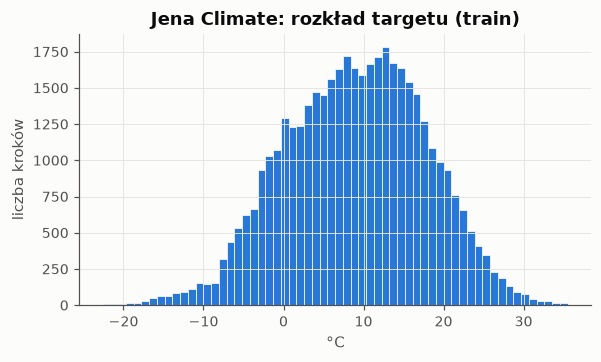

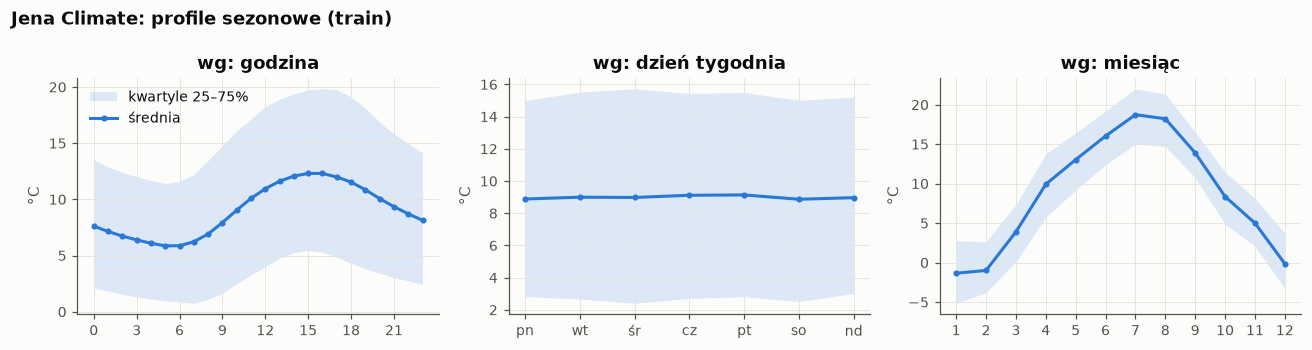

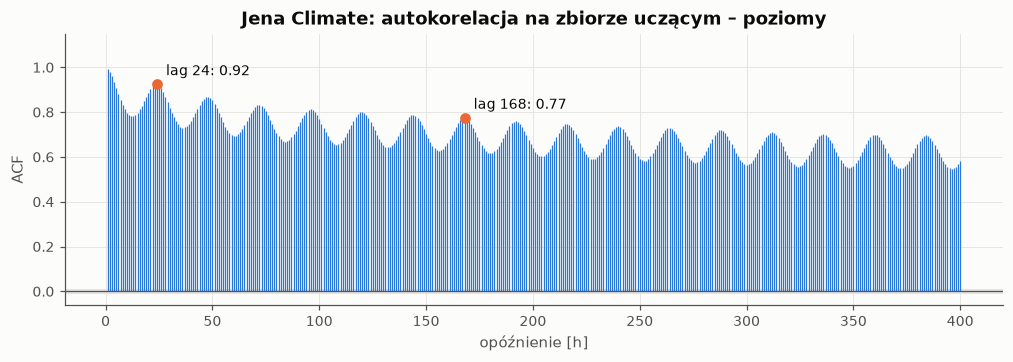

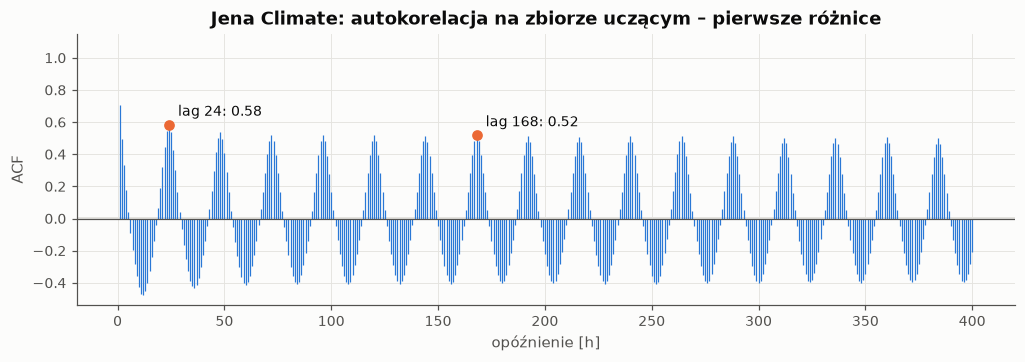

,horyzont,s,MAE persistence,MAE seasonal naive,skill SN,SN ≡ persistence,n
0,1,24,0.6819,2.6187,-2.8401,nie,42047
1,1,168,0.6824,4.6240,-5.7763,nie,41903
2,6,24,3.2193,2.6187,0.1866,nie,42047
3,6,168,3.2221,4.6240,-0.4351,nie,41903
4,24,24,2.6187,2.6187,0.0000,tak,42047
5,24,168,2.6106,4.6240,-0.7712,nie,41903


Proponowany okres sezonowy s: 24


,corr z y(t+1),corr z y(t+6),corr z y(t+24)
zmienna w chwili t,,,
T (degC),0.994,0.882,0.925
p (mbar),-0.016,0.008,0.048
Tpot (K),0.991,0.878,0.917
Tdew (degC),0.905,0.878,0.842
rh (%),-0.546,-0.340,-0.508
VPmax (mbar),0.942,0.809,0.870
VPact (mbar),0.875,0.847,0.814
VPdef (mbar),0.745,0.555,0.683
sh (g/kg),0.874,0.846,0.812


In [23]:
d = D['jena']; spec = d['spec']
y_train = d['h_f'].loc[d['split'] == 'train', spec.target]
td.plot_hist(y_train, spec, OUT); plt.show()
profiles = td.seasonal_profiles(y_train, spec)
td.plot_profiles(profiles, spec, OUT); plt.show()
for name, p in profiles.items():
    td.save_table(p.round(3), OUT, f'jena_profil_{name.replace(" ", "_")}')
acf_lvl = td.acf_train(y_train, spec.acf_nlags)
acf_tr = td.acf_train(y_train, spec.acf_nlags, transform='diff')
td.plot_acf(acf_lvl, y_train.notna().sum(), spec, ' – poziomy', OUT, 'acf_poziomy'); plt.show()
td.plot_acf(acf_tr, y_train.notna().sum() - 1, spec, ' – pierwsze różnice', OUT, 'acf_roznice'); plt.show()
td.save_table(pd.concat({'poziomy': acf_lvl, 'pierwsze różnice': acf_tr}, axis=1).round(4), OUT, 'jena_acf')
lag_table = td.save_table(td.baseline_check_train(y_train, spec), OUT, 'jena_lagi_train', index=False)
display(lag_table)
d.update(acf_lvl=acf_lvl, acf_tr=acf_tr, s=td.propose_seasonal_period(lag_table))
print('Proponowany okres sezonowy s:', d['s'])
td.save_table(td.lagged_correlations(d['h_f'][d['split'] == 'train'], spec), OUT, 'jena_korelacje')

**Komentarz.** Profil dobowy ma minimum ok. 5,9 °C o godz. 5–6 i maksimum ok. 12,3 °C o godz. 15–16; cyklu tygodniowego nie ma (średnie dni tygodnia 8,9–9,1 °C), a średnie miesięczne zmieniają się od −1,3 °C (styczeń) do 18,7 °C (lipiec). ACF różnic ma szczyty co 24 h; szczyt przy lagu 168 (0,52) jest tylko wielokrotnością doby i jest niższy niż przy lagu 24 (0,58). Prognoza sezonowa z s = 24 ma mniejsze MAE niż z s = 168 (2,62 wobec 4,62 °C), więc przyjmujemy **s = 24**. Na horyzoncie 1 h persistence jest znacznie lepsza (MAE 0,68 °C), a przy h = 6 lepsza jest prognoza sezonowa. Z przyszłą temperaturą najsilniej korelują zmienne niemal ją powielające (`Tpot` 0,991, `rho` −0,960, `VPmax` 0,942), a ciśnienie i wiatr prawie wcale (|r| ≤ 0,14).

#### Household Power Consumption

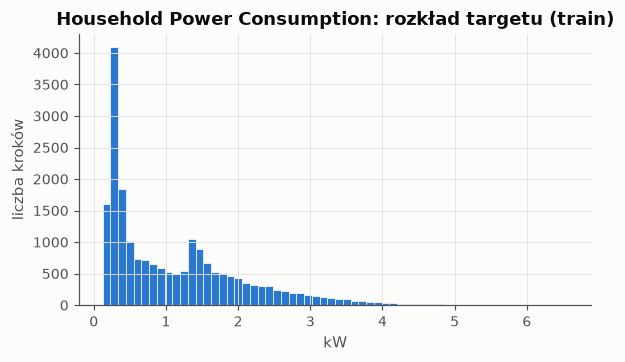

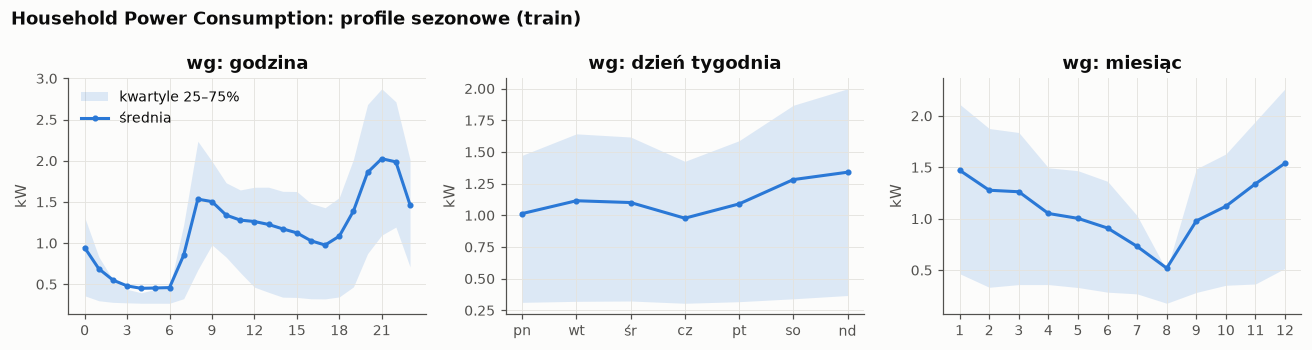

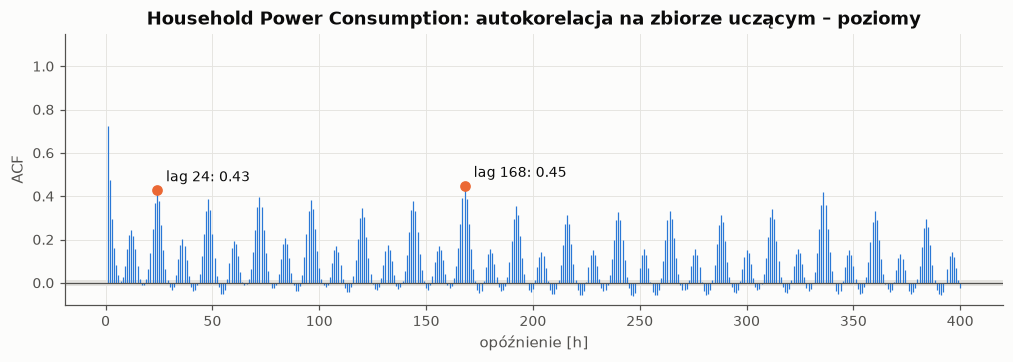

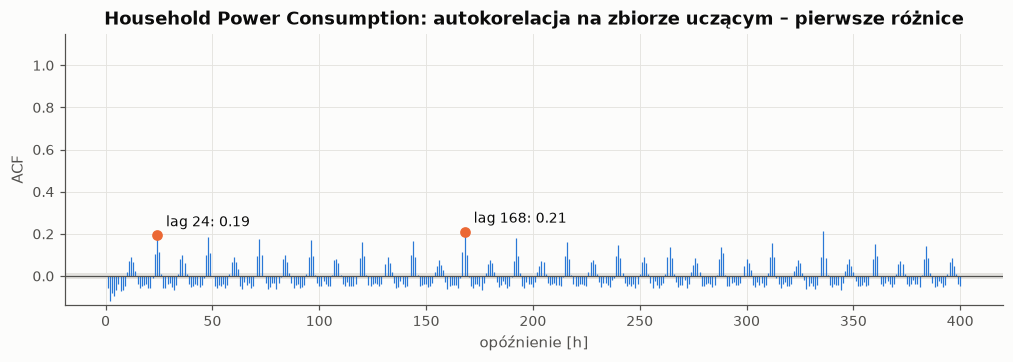

,horyzont,s,MAE persistence,MAE seasonal naive,skill SN,SN ≡ persistence,n
0,1,24,0.4626,0.6940,-0.5002,nie,20632
1,1,168,0.4616,0.6755,-0.4634,nie,20449
2,6,24,1.0118,0.6940,0.3141,nie,20632
3,6,168,1.0087,0.6757,0.3302,nie,20444
4,24,24,0.6940,0.6940,0.0000,tak,20632
5,24,168,0.6920,0.6759,0.0233,nie,20426


Proponowany okres sezonowy s: 168


,corr z y(t+1),corr z y(t+6),corr z y(t+24)
zmienna w chwili t,,,
Global_active_power,0.722,0.035,0.428
Global_reactive_power,0.280,-0.026,0.122
Voltage,-0.273,0.204,-0.174
Global_intensity,0.723,0.032,0.427
Sub_metering_1,0.299,0.007,0.152
Sub_metering_2,0.265,0.068,0.073
Sub_metering_3,0.448,0.037,0.285


In [24]:
d = D['household']; spec = d['spec']
y_train = d['h_f'].loc[d['split'] == 'train', spec.target]
td.plot_hist(y_train, spec, OUT); plt.show()
profiles = td.seasonal_profiles(y_train, spec)
td.plot_profiles(profiles, spec, OUT); plt.show()
for name, p in profiles.items():
    td.save_table(p.round(3), OUT, f'household_profil_{name.replace(" ", "_")}')
acf_lvl = td.acf_train(y_train, spec.acf_nlags)
acf_tr = td.acf_train(y_train, spec.acf_nlags, transform='diff')
td.plot_acf(acf_lvl, y_train.notna().sum(), spec, ' – poziomy', OUT, 'acf_poziomy'); plt.show()
td.plot_acf(acf_tr, y_train.notna().sum() - 1, spec, ' – pierwsze różnice', OUT, 'acf_roznice'); plt.show()
td.save_table(pd.concat({'poziomy': acf_lvl, 'pierwsze różnice': acf_tr}, axis=1).round(4), OUT, 'household_acf')
lag_table = td.save_table(td.baseline_check_train(y_train, spec), OUT, 'household_lagi_train', index=False)
display(lag_table)
d.update(acf_lvl=acf_lvl, acf_tr=acf_tr, s=td.propose_seasonal_period(lag_table))
print('Proponowany okres sezonowy s:', d['s'])
td.save_table(td.lagged_correlations(d['h_f'][d['split'] == 'train'], spec), OUT, 'household_korelacje')

**Komentarz.** Profil dobowy ma minimum nocne ok. 0,45 kW, szczyt poranny ok. 1,5 kW (godz. 8–9) i wieczorny ok. 2,0 kW (godz. 21–22). W weekendy zużycie jest wyższe (sobota 1,28 kW, niedziela 1,34 kW wobec 0,98–1,12 kW w dni robocze), a w sierpniu najniższe (0,52 kW). ACF różnic jest słaba i prawie równa przy lagu 24 (0,19) i 168 (0,21). Okres tygodniowy daje nieco mniejsze MAE prognozy sezonowej (0,676 wobec 0,694 kW), więc przyjmujemy **s = 168**, choć przewaga to tylko ok. 3%. Z wartością za 1 h najsilniej korelują moc i natężenie (0,72), a za 6 h żadna zmienna nie przekracza |r| = 0,21.

#### Metro Interstate Traffic Volume

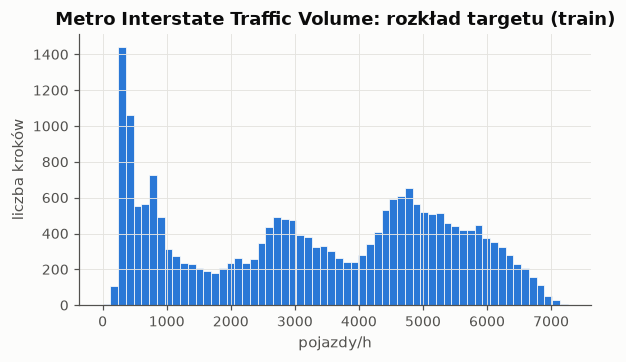

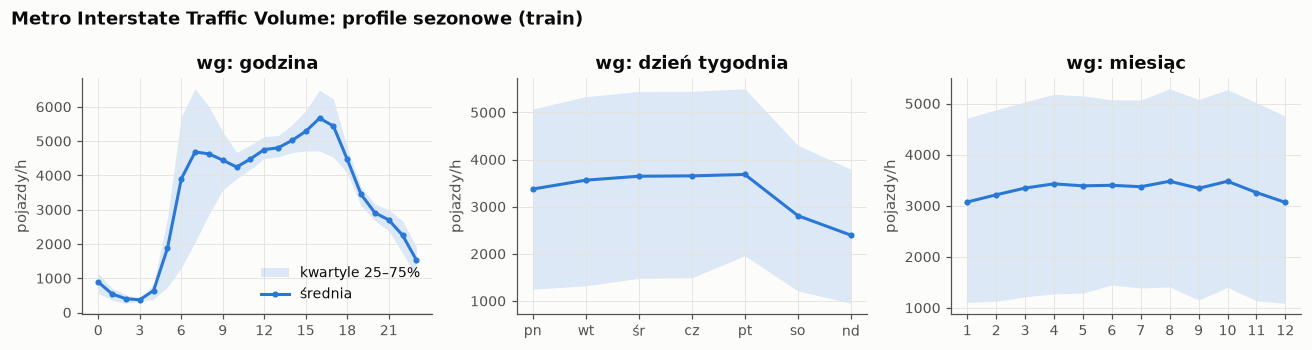

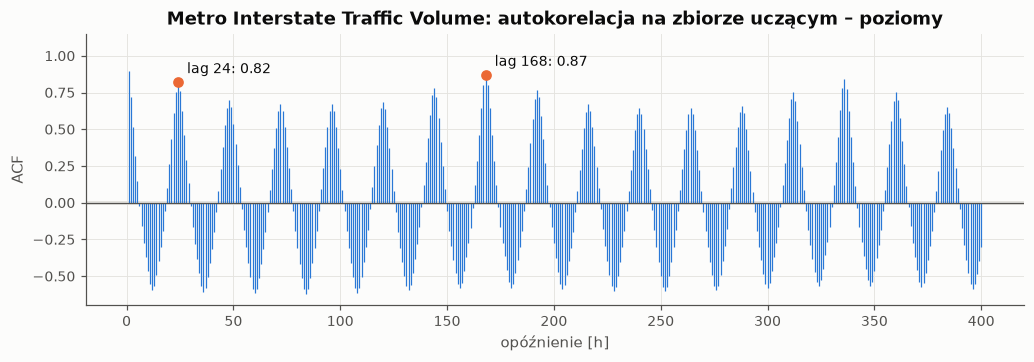

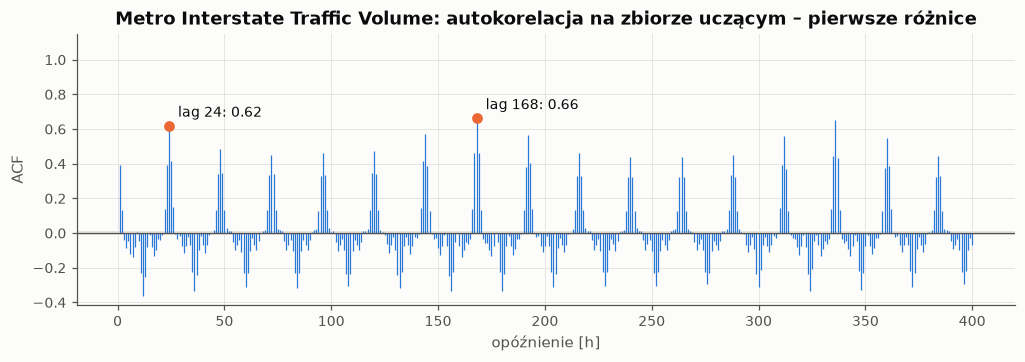

,horyzont,s,MAE persistence,MAE seasonal naive,skill SN,SN ≡ persistence,n
0,1,24,575.4025,642.7487,-0.1170,nie,21514
1,1,168,574.3007,422.6593,0.2640,nie,20877
2,6,24,2415.3210,642.1899,0.7341,nie,21269
3,6,168,2412.2230,421.6202,0.8252,nie,20576
4,24,24,642.7787,642.7787,0.0000,tak,21597
5,24,168,641.2941,419.4533,0.3459,nie,20436


Proponowany okres sezonowy s: 168


,corr z y(t+1),corr z y(t+6),corr z y(t+24)
zmienna w chwili t,,,
traffic_volume,0.901,-0.020,0.848
temp (degC),0.124,-0.039,0.147
rain_1h,-0.013,0.010,0.004
snow_1h,0.000,-0.011,0.001
clouds_all,0.037,-0.012,0.052
w_Clear,-0.051,-0.013,-0.056
w_Clouds,0.062,-0.047,0.062
w_Drizzle,-0.004,0.010,0.013
w_Fog,-0.011,0.058,-0.023


In [25]:
d = D['metro']; spec = d['spec']
y_train = d['h_f'].loc[d['split'] == 'train', spec.target]
td.plot_hist(y_train, spec, OUT); plt.show()
profiles = td.seasonal_profiles(y_train, spec)
td.plot_profiles(profiles, spec, OUT); plt.show()
for name, p in profiles.items():
    td.save_table(p.round(3), OUT, f'metro_profil_{name.replace(" ", "_")}')
acf_lvl = td.acf_train(y_train, spec.acf_nlags)
acf_tr = td.acf_train(y_train, spec.acf_nlags, transform='diff')
td.plot_acf(acf_lvl, y_train.notna().sum(), spec, ' – poziomy', OUT, 'acf_poziomy'); plt.show()
td.plot_acf(acf_tr, y_train.notna().sum() - 1, spec, ' – pierwsze różnice', OUT, 'acf_roznice'); plt.show()
td.save_table(pd.concat({'poziomy': acf_lvl, 'pierwsze różnice': acf_tr}, axis=1).round(4), OUT, 'metro_acf')
lag_table = td.save_table(td.baseline_check_train(y_train, spec), OUT, 'metro_lagi_train', index=False)
display(lag_table)
d.update(acf_lvl=acf_lvl, acf_tr=acf_tr, s=td.propose_seasonal_period(lag_table))
print('Proponowany okres sezonowy s:', d['s'])
td.save_table(td.lagged_correlations(d['h_f'][d['split'] == 'train'], spec), OUT, 'metro_korelacje')

**Komentarz.** Ruch ma minimum ok. 370 pojazdów/h o godz. 3, szczyt poranny ok. 4700 pojazdów/h (godz. 7) i popołudniowy ok. 5670 pojazdów/h (godz. 16). W dni robocze średnio 3370–3680 pojazdów/h, w sobotę 2810, w niedzielę 2400; cykl roczny jest słaby. ACF różnic jest wyższa przy lagu 168 niż 24 (0,66 wobec 0,62), a prognoza sezonowa z s = 168 ma wyraźnie mniejsze MAE (423 wobec 643 pojazdów/h) i jest lepsza od persistence już przy h = 1 (575 pojazdów/h). Przyjmujemy **s = 168**. Zmienne pogodowe i flaga święta są słabo skorelowane z przyszłym ruchem (|r| ≤ 0,15), więc w wariancie wielowymiarowym większej roli spodziewamy się po zmiennych kalendarzowych.

#### Air Passengers

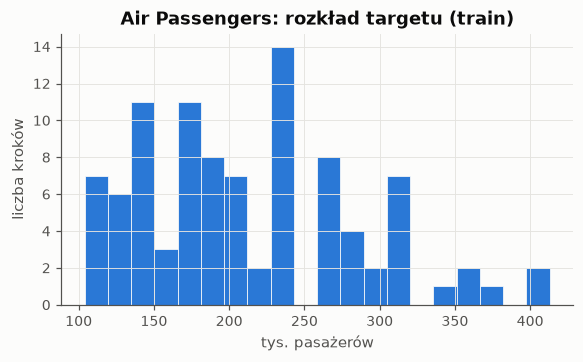

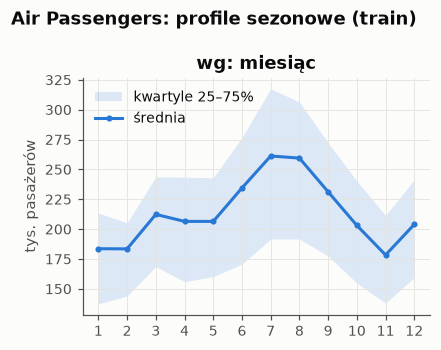

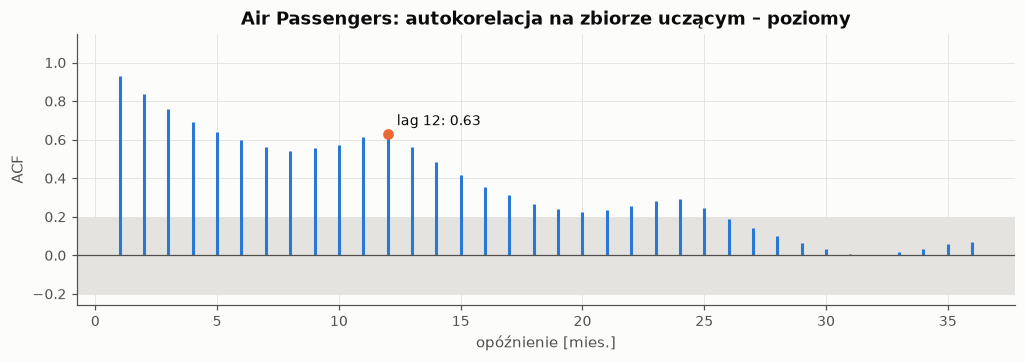

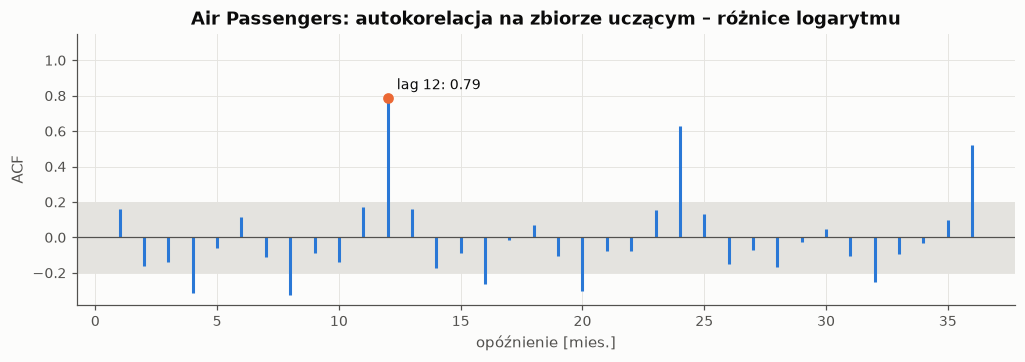

,horyzont,s,MAE persistence,MAE seasonal naive,skill SN,SN ≡ persistence,n
0,1,12,19.7619,29.2024,-0.4777,nie,84
1,3,12,37.2857,29.2024,0.2168,nie,84
2,12,12,29.2024,29.2024,0.0000,tak,84


Proponowany okres sezonowy s: 12


In [26]:
d = D['air']; spec = d['spec']
y_train = d['h_f'].loc[d['split'] == 'train', spec.target]
td.plot_hist(y_train, spec, OUT); plt.show()
profiles = td.seasonal_profiles(y_train, spec)
td.plot_profiles(profiles, spec, OUT); plt.show()
for name, p in profiles.items():
    td.save_table(p.round(3), OUT, f'air_profil_{name.replace(" ", "_")}')
acf_lvl = td.acf_train(y_train, spec.acf_nlags)
acf_tr = td.acf_train(y_train, spec.acf_nlags, transform='dlog')
td.plot_acf(acf_lvl, y_train.notna().sum(), spec, ' – poziomy', OUT, 'acf_poziomy'); plt.show()
td.plot_acf(acf_tr, y_train.notna().sum() - 1, spec, ' – różnice logarytmu', OUT, 'acf_roznice'); plt.show()
td.save_table(pd.concat({'poziomy': acf_lvl, 'różnice logarytmu': acf_tr}, axis=1).round(4), OUT, 'air_acf')
lag_table = td.save_table(td.baseline_check_train(y_train, spec), OUT, 'air_lagi_train', index=False)
display(lag_table)
d.update(acf_lvl=acf_lvl, acf_tr=acf_tr, s=td.propose_seasonal_period(lag_table))
print('Proponowany okres sezonowy s:', d['s'])

**Komentarz.** Średnie miesięczne na zbiorze uczącym są najwyższe w lipcu i sierpniu (261 i 260 tys.), a najniższe w listopadzie (178 tys.). ACF poziomów maleje powoli (0,93 przy lagu 1), co jest efektem trendu. ACF różnic logarytmu ma wyraźne szczyty przy lagach 12, 24 i 36 (0,79, 0,63 i 0,52), co potwierdza **s = 12**. Na zbiorze uczącym persistence ma przy h = 1 mniejsze MAE (19,8 tys.) niż prognoza sezonowa (29,2 tys.), a przy h = 3 jest odwrotnie (37,3 wobec 29,2 tys.).

### 3.2 Implementacja i test funkcji `make_windows`

Poprawność funkcji sprawdzamy na szeregu arytmetycznym 0, 1, 2, …, w którym wartość jest równa numerowi kroku: cel każdego okna musi być równy ostatniemu krokowi wejścia powiększonemu o h, a całe wejście musi poprzedzać cel.

In [27]:
import inspect
print(inspect.getsource(td.make_windows))
tests = td.check_windows(D['jena']['split'])
display(tests)
assert tests['cel = ostatni krok wejścia + h'].all() and tests['wejście przed celem'].all()

def make_windows(data, window_size: int = 30, horizon: int = 1, target_col: int = 0):
    """Okna wejsciowe bez zagladania w przyszlosc.

    data: tablica (T,) lub (T, d). Przyklad i: X = data[i : i+L] (kroki t-L+1..t), y = data[i+L+h-1, target]
    (krok t+h). Zwraca X (n, L, d), y (n,) i pozycje celu w szeregu (n,). Okna z brakiem w wejsciu lub celu
    sa pomijane."""
    a = np.asarray(data, dtype=float)
    if a.ndim == 1:
        a = a[:, None]
    L, h = int(window_size), int(horizon)
    n = len(a) - L - h + 1
    if n <= 0:
        return np.empty((0, L, a.shape[1])), np.empty(0), np.empty(0, dtype=int)
    idx = np.arange(n)
    X = np.lib.stride_tricks.sliding_window_view(a, (L, a.shape[1]))[:n, 0]
    tgt = idx + L + h - 1
    y = a[tgt, target_col]
    ok = ~np.isnan(X).any(axis=(1, 2)) & ~np.isnan(y)
    return X[ok], y[ok], tgt[ok]



,okno L,horyzont h,cel = ostatni krok wejścia + h,wejście przed celem,1. okno val sięga do train (dozwolone)
0,30,1,True,True,True
1,30,6,True,True,True
2,24,12,True,True,True


### 3.3 Kształty X i y

Punktem wyjścia jest okno 30 kroków i horyzont 1 (prognoza kolejnego kroku). Dla zbiorów godzinowych pokazujemy też okno 72 h przyjęte w porównaniu podstawowym, a dla Air Passengers okna 12 i 24 miesiące. `X` ma kształt (liczba przykładów, długość okna, liczba cech); wariant jednowymiarowy używa tylko pierwszej cechy (targetu).

In [28]:
shape_rows = []
for key in td.SPECS:
    d = D[key]; spec = d['spec']
    windows = (30, 72) if spec.freq == 'h' else (12, 24, 30)
    t = td.window_shape_table(d['h_s'], d['split'], d['cols'], windows, spec.horizons)
    t.insert(0, 'zbiór danych', spec.name); shape_rows.append(t)
td.save_table(pd.concat(shape_rows), OUT, 'ksztalty_okien', index=False)

,zbiór danych,okno L,horyzont h,X_train,X_val,X_test
0,Jena Climate,30,1,"(42041, 30, 15)","(13970, 30, 15)","(13937, 30, 15)"
1,Jena Climate,30,6,"(42036, 30, 15)","(13965, 30, 15)","(13932, 30, 15)"
2,Jena Climate,30,24,"(42018, 30, 15)","(13955, 30, 15)","(13914, 30, 15)"
3,Jena Climate,72,1,"(41999, 72, 15)","(13928, 72, 15)","(13895, 72, 15)"
4,Jena Climate,72,6,"(41994, 72, 15)","(13923, 72, 15)","(13890, 72, 15)"
5,Jena Climate,72,24,"(41976, 72, 15)","(13913, 72, 15)","(13872, 72, 15)"
0,Household Power Consumption,30,1,"(20620, 30, 7)","(6699, 30, 7)","(6604, 30, 7)"
1,Household Power Consumption,30,6,"(20610, 30, 7)","(6684, 30, 7)","(6589, 30, 7)"
2,Household Power Consumption,30,24,"(20574, 30, 7)","(6639, 30, 7)","(6535, 30, 7)"
3,Household Power Consumption,72,1,"(20536, 72, 7)","(6573, 72, 7)","(6478, 72, 7)"


In [29]:
td.save_table(td.window_counts(D['air']['h_f']['passengers'], D['air']['split'], (6, 12, 24, 30), td.SPECS['air'].horizons),
              OUT, 'air_liczba_okien', index=False)

,okno L,horyzont h,train,val,test,odrzucone przez luki
0,6,1,90,24,24,0
1,6,3,88,24,24,0
2,6,12,79,24,24,0
3,12,1,84,24,24,0
4,12,3,82,24,24,0
5,12,12,73,24,24,0
6,24,1,72,24,24,0
7,24,3,70,24,24,0
8,24,12,61,24,24,0
9,30,1,66,24,24,0


### 3.4 Przykładowe okno i wartość prognozowana

Ostatnie okno zbioru uczącego (L = 30, h = 1) w oryginalnych jednostkach targetu.

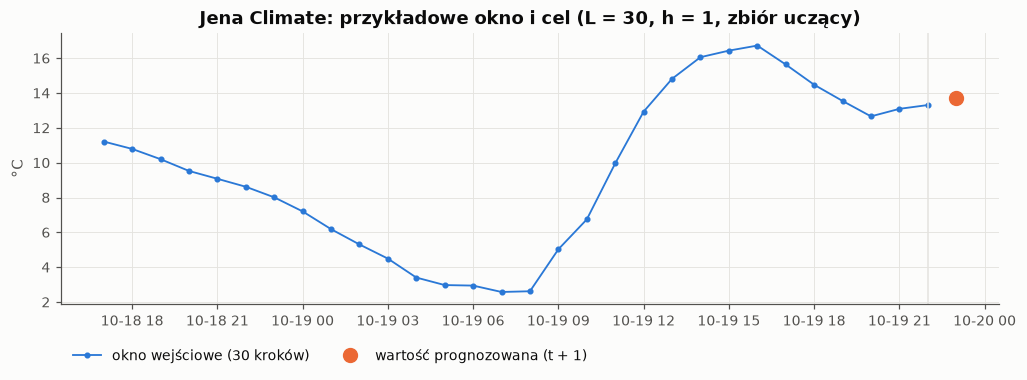

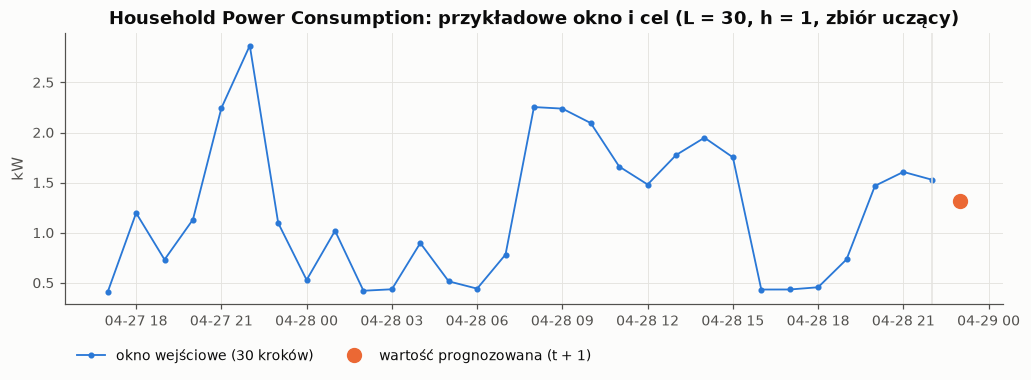

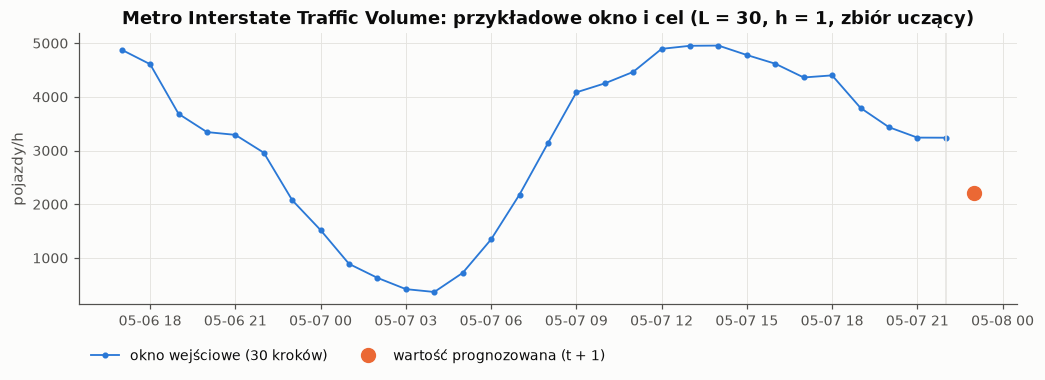

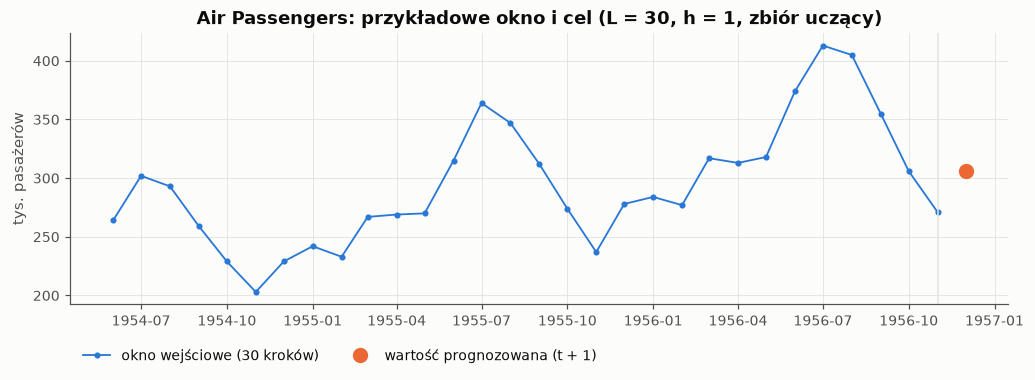

In [30]:
for key in td.SPECS:
    d = D[key]
    td.plot_window(d['h_s'], d['split'], d['cols'], d['scaler'], d['cont'], d['spec'], 30, 1, OUT); plt.show()

### 3.5 Uzasadnienie długości okna

Okno 30 kroków jest punktem wyjścia. Dla danych godzinowych obejmuje jeden pełny cykl dobowy, ale nie obejmuje cyklu tygodniowego. Dlatego w porównaniu podstawowym przyjmujemy okno 72 h, które zawiera trzy cykle dobowe, a w eksperymencie z długością okna porównujemy dla Jena Climate okna 12 h (krótsze od doby), 24 h, 72 h i 168 h (pełny tydzień). Okno 30 h zostaje jako przebieg kontrolny.

**Wniosek z sekcji 3.1.** Dla Jena Climate (s = 24) okno 72 h obejmuje dominujący okres z zapasem. Dla Household i Metro dominujący okres wynosi 168 h, więc okno 72 h nie zawiera wartości sprzed tygodnia. Dla Metro, gdzie lag tygodniowy jest najsilniejszym pojedynczym predyktorem, w eksperymencie z długością okna dodajemy okno 168 h. Dla Household przewaga okresu tygodniowego jest niewielka (ok. 3%), więc tego eksperymentu nie rozszerzamy.

Dla Air Passengers okno 30 miesięcy obejmuje dwa i pół cyklu rocznego, ale zmniejsza liczbę przykładów uczących (tabela powyżej). Przyjmujemy okno 24 miesiące (dwa pełne cykle roczne), a w eksperymencie z długością okna porównujemy okna 6 miesięcy (krótsze od roku), 12 i 24 miesiące. Ostateczny wybór długości okna następuje na zbiorze walidacyjnym.

### 3.6 Dekompozycja: trend, sezonowość i reszta

Dekompozycja rozkłada szereg na sumę składowych: trend (zmiany wolne), składowe sezonowe (powtarzające się cykle) i resztę (część nieregularna). Dla zbiorów godzinowych stosujemy MSTL z okresami 24 i 168 h, czyli dekompozycję STL rozszerzoną na kilka okresów; wolniejsze zmiany, w tym cykl roczny, trafiają wtedy do trendu. Dla Air Passengers stosujemy STL logarytmu z okresem 12, bo logarytm zamienia sezonowość multiplikatywną na addytywną. Dekompozycja wymaga szeregu bez luk, dlatego liczymy ją na najdłuższym ciągłym fragmencie zbioru uczącego, zamiast interpolować długie przerwy.

Siłę składowej mierzymy wskaźnikiem F = max(0, 1 − Var(R) / Var(X + R)), gdzie R to reszta, a X trend albo składowa sezonowa (Wang, Smith i Hyndman, 2006). F bliskie 1 oznacza składową wyraźną, a bliskie 0 – składową słabą w porównaniu z szumem. Wykres pokazuje ostatnie 4 tygodnie fragmentu (Air Passengers: cały zbiór uczący).

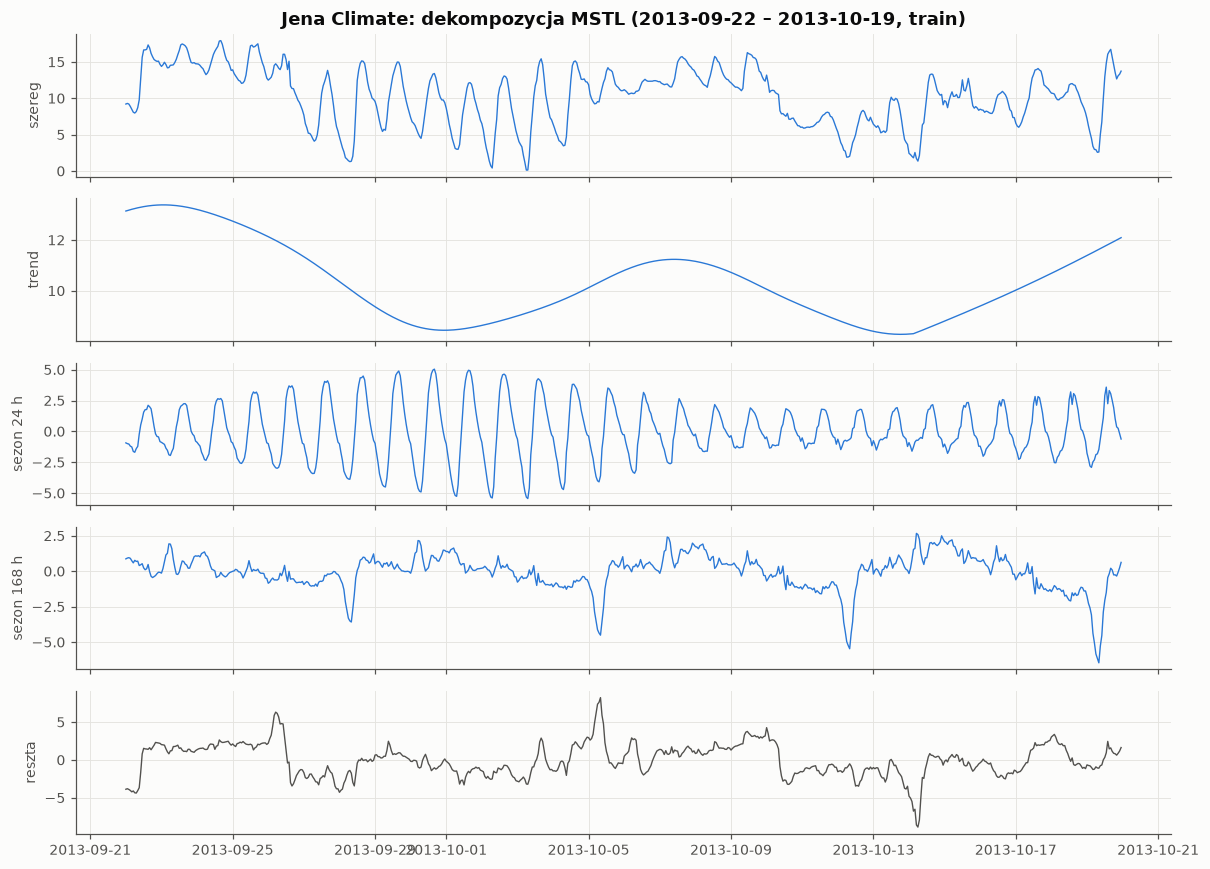

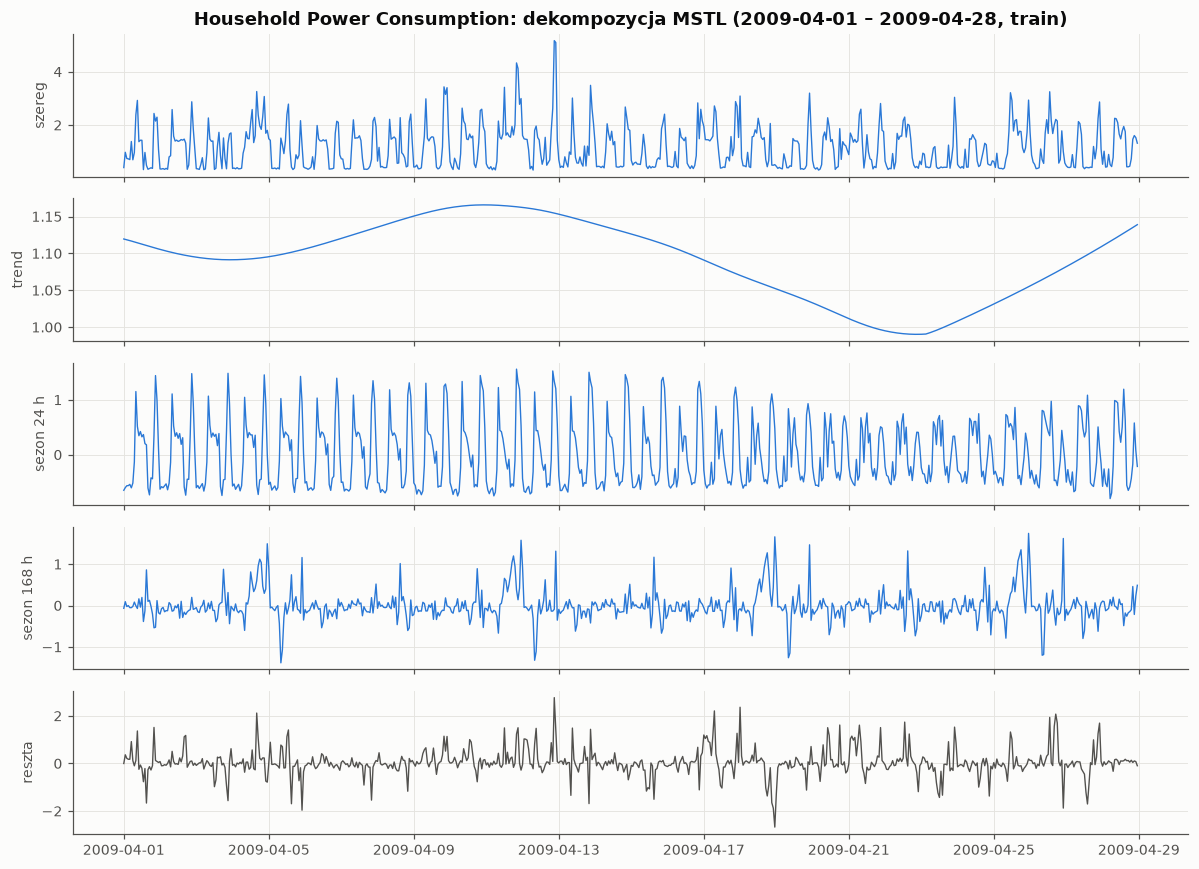

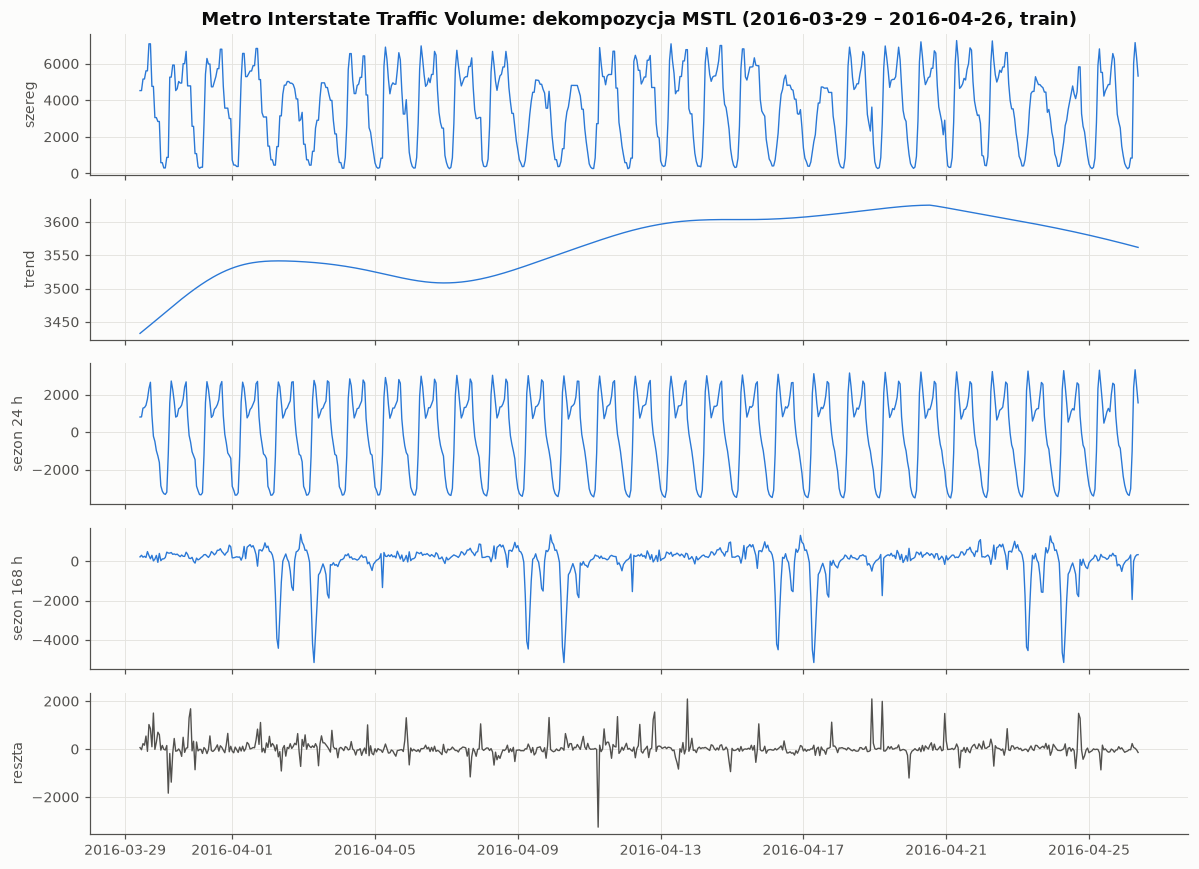

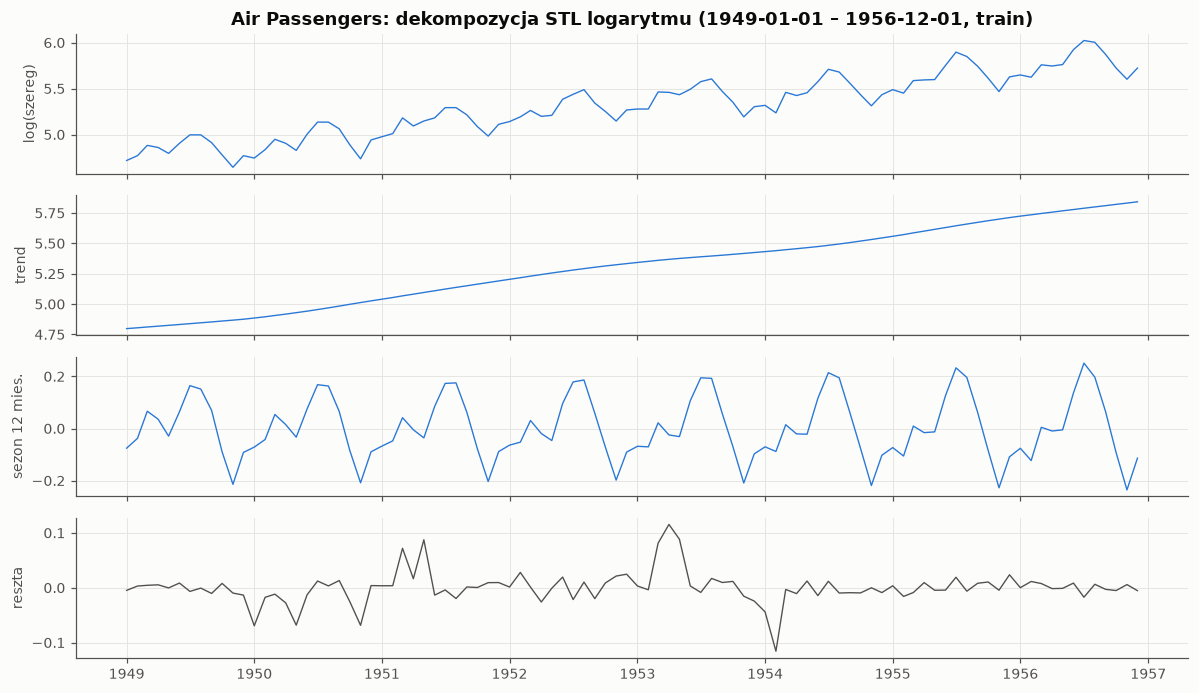

,zbiór danych,fragment,kroki,siła trendu F_T,siła: sezon 24 h,siła: sezon 168 h,udział wariancji reszty,siła: sezon 12 mies.
0,Jena Climate,2009-01-01 – 2013-10-19,42071,0.901,0.505,0.117,0.089,NaN
1,Household Power Consumption,2007-04-30 – 2009-04-28,17505,0.193,0.392,0.159,0.489,NaN
2,Metro Interstate Traffic Volume,2015-10-27 – 2016-04-26,4370,0.109,0.918,0.686,0.082,NaN
3,Air Passengers,1949-01-01 – 1956-12-01,96,0.991,NaN,NaN,0.008,0.943


In [31]:
strength_rows = []
for key in td.SPECS:
    d = D[key]; spec = d['spec']
    y_train = d['h_f'].loc[d['split'] == 'train', spec.target]
    comp, st = td.decompose(y_train, spec)
    d['strength'] = st
    strength_rows.append({'zbiór danych': spec.name, **st})
    td.plot_decomposition(comp, spec, OUT, last=None if spec.freq != 'h' else 24 * 28); plt.show()
td.save_table(pd.DataFrame(strength_rows), OUT, 'sila_skladowych', index=False)

**Komentarz.** Dekompozycja potwierdza różny charakter zbiorów (tabela `sila_skladowych`):

- **Jena Climate** (cały zbiór uczący, 2009-01-01 – 2013-10-19, 42 071 h): dominuje trend (F_T = 0,901), który obejmuje cykl roczny i kilkudniowe zmiany pogody; cykl dobowy jest umiarkowany (F = 0,505), tygodniowego praktycznie nie ma (F = 0,117; składowa 168 h przejmuje tu nieregularne zmiany pogody). Reszta to 8,9% wariancji. Prognoza zależy więc głównie od śledzenia bieżącego poziomu i cyklu dobowego.
- **Household Power Consumption** (2007-04-30 – 2009-04-28, 17 505 h): wszystkie składowe są słabe (F_T = 0,193, dobowa 0,392, tygodniowa 0,159), a reszta to 48,9% wariancji. Jest to najbardziej zaszumiony szereg: prawie połowa zmienności pozostaje niewyjaśniona przez trend i cykle (głównie nieregularne włączenia urządzeń). Udział reszty nie jest ścisłą miarą nieprzewidywalności, bo inne modele mogą wykryć zależności pominięte w dekompozycji, ale wskazuje, że regularna część sygnału jest tu najmniejsza.
- **Metro Interstate Traffic Volume** (najdłuższy ciągły fragment bez luk: 2015-10-27 – 2016-04-26, 4370 h): najsilniejsza i najbardziej regularna sezonowość, dobowa (F = 0,918) i tygodniowa (F = 0,686, wyraźne spadki w weekendy); trend jest słaby (0,109), reszta to 8,2% wariancji.
- **Air Passengers** (logarytm, 96 miesięcy): trend (F_T = 0,991) i sezonowość roczna (F = 0,943) opisują szereg niemal całkowicie; reszta to 0,8% wariancji.

Fragmenty mają różną długość, bo dekompozycja wymaga szeregu bez luk; dla Metro jest to tylko ok. pół roku, dlatego wynik dla tego zbioru dotyczy okresu jesień–wiosna.

### 3.7 Stacjonarność

Szereg stacjonarny ma w czasie stałą średnią, wariancję i strukturę autokorelacji. Stosujemy dwa uzupełniające się testy na najdłuższym ciągłym fragmencie zbioru uczącego (Air Passengers: logarytm):

- **ADF** (rozszerzony test Dickeya–Fullera): hipoteza zerowa to pierwiastek jednostkowy, czyli niestacjonarność; małe p (< 0,05) przemawia za stacjonarnością.
- **KPSS**: hipoteza zerowa to stacjonarność wokół stałej; małe p przemawia przeciw stacjonarności. Biblioteka podaje p tylko w przedziale 0,01–0,10, więc wartości na granicach oznaczają „≤ 0,01” albo „≥ 0,10”.

Szereg uznajemy za stacjonarny, gdy ADF odrzuca swoją hipotezę, a KPSS nie; gdy oba testy wskazują to samo w przeciwną stronę – za niestacjonarny; w pozostałych przypadkach wynik jest niejednoznaczny. Testujemy poziomy, pierwsze różnice i różnice sezonowe (lag s).

In [32]:
stat_rows = []
for key in td.SPECS:
    d = D[key]; spec = d['spec']
    y_train = d['h_f'].loc[d['split'] == 'train', spec.target]
    t = td.stationarity_table(y_train, spec, d['s']); t.insert(0, 'zbiór danych', spec.name)
    d['stationarity'] = t
    stat_rows.append(t)
td.save_table(pd.concat(stat_rows), OUT, 'stacjonarnosc', index=False)

C:\projekt2a\ts_data.py:846: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf = adfuller(x, maxlag=maxlag, autolag="AIC")
C:\projekt2a\ts_data.py:846: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf = adfuller(x, maxlag=maxlag, autolag="AIC")
C:\projekt2a\ts_data.py:846: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autol

,zbiór danych,wariant,n,ADF statystyka,ADF p,KPSS statystyka,KPSS p,wniosek
0,Jena Climate,poziomy,42071,-7.27,0.0000,0.834,0.01,niejednoznaczny
1,Jena Climate,pierwsze różnice,42070,-32.86,0.0000,0.014,0.10,stacjonarny
2,Jena Climate,różnice sezonowe (lag 24),42047,-24.19,0.0000,0.015,0.10,stacjonarny
0,Household Power Consumption,poziomy,17505,-9.24,0.0000,2.609,0.01,niejednoznaczny
1,Household Power Consumption,pierwsze różnice,17504,-32.14,0.0000,0.009,0.10,stacjonarny
2,Household Power Consumption,różnice sezonowe (lag 168),17337,-13.85,0.0000,0.034,0.10,stacjonarny
0,Metro Interstate Traffic Volume,poziomy,4370,-8.05,0.0000,0.858,0.01,niejednoznaczny
1,Metro Interstate Traffic Volume,pierwsze różnice,4369,-14.02,0.0000,0.010,0.10,stacjonarny
2,Metro Interstate Traffic Volume,różnice sezonowe (lag 168),4202,-7.61,0.0000,0.096,0.10,stacjonarny
0,Air Passengers,poziomy,96,-0.72,0.8407,1.594,0.01,niestacjonarny


**Komentarz.** - **Zbiory godzinowe – poziomy:** ADF odrzuca hipotezę pierwiastka jednostkowego (p < 0,001), ale KPSS odrzuca hipotezę stacjonarności (p ≤ 0,01), więc wynik jest niejednoznaczny. Taki układ jest typowy dla szeregów z silną sezonowością i wolno zmieniającym się poziomem (cykl roczny w Jenie, zmiany zużycia w Household): szereg wraca do średniej, ale bardzo powoli. Po pierwszych różnicach i po różnicach sezonowych oba testy są zgodne – szeregi są stacjonarne.
- **Air Passengers:** logarytm poziomów jest niestacjonarny (ADF p = 0,84, KPSS p ≤ 0,01). Dla pierwszych różnic (ADF p = 0,079) i różnic sezonowych (ADF p = 0,152) KPSS nie odrzuca stacjonarności, ale ADF też jej nie potwierdza, co przy 95 i 84 obserwacjach wynika w dużej mierze z małej mocy testu.

**Wniosek dla modeli:** modele dostają okna poziomów, a nie różnic; przy zbiorach godzinowych nie stanowi to problemu, bo okno zawiera bieżący poziom, a rozkłady w walidacji i teście są bliskie uczącemu (punkt 2.1). Dla Air Passengers niestacjonarność poziomów potwierdza potrzebę przekształcenia: wariant podstawowy (logarytm) zostawia trend, a wariant kontrolny (różnice sezonowe) go usuwa.

### 3.8 Periodogram

Periodogram rozkłada wariancję szeregu na składowe okresowe: wysoki pik przy okresie p oznacza, że szereg zawiera wyraźny cykl o tej długości. Jest to niezależne od ACF potwierdzenie okresów sezonowych. Liczymy go na najdłuższym ciągłym fragmencie zbioru uczącego (Air Passengers: na pierwszych różnicach logarytmu, aby trend nie zdominował widma). Przerywane linie oznaczają okresy 12, 24 i 168 h oraz rok (8766 h); dla Air Passengers 3, 4, 6 i 12 miesięcy. Tabela podaje najsilniejsze lokalne maksima i ich udział w całkowitej mocy widma.

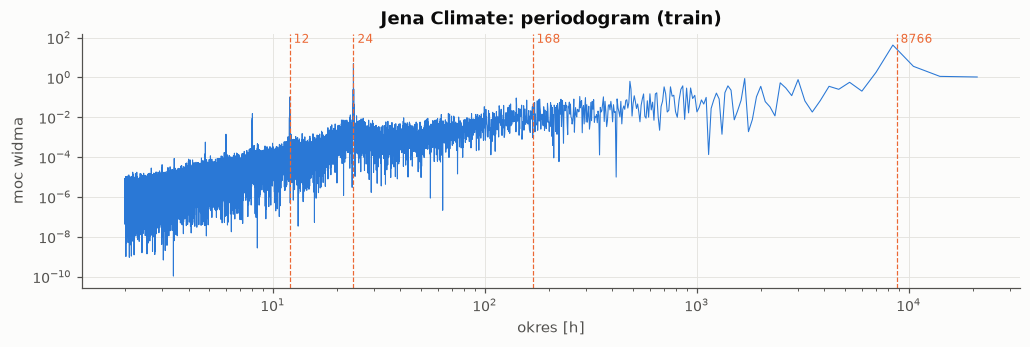

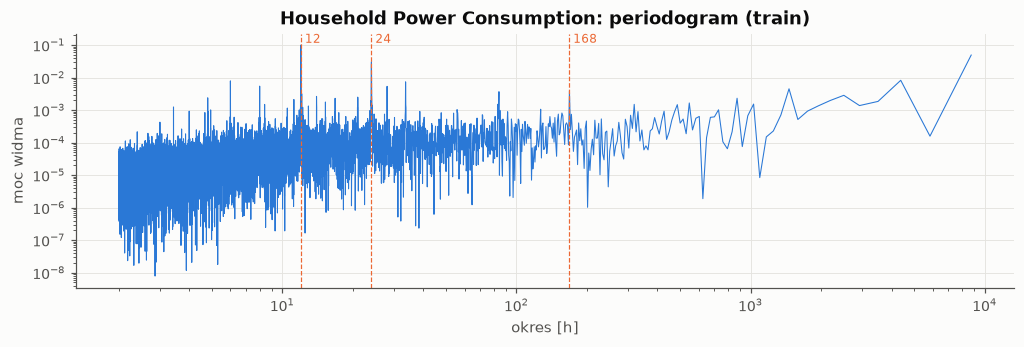

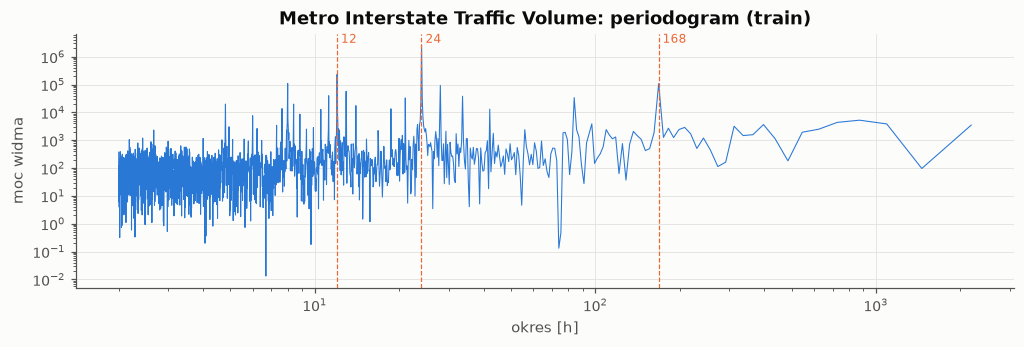

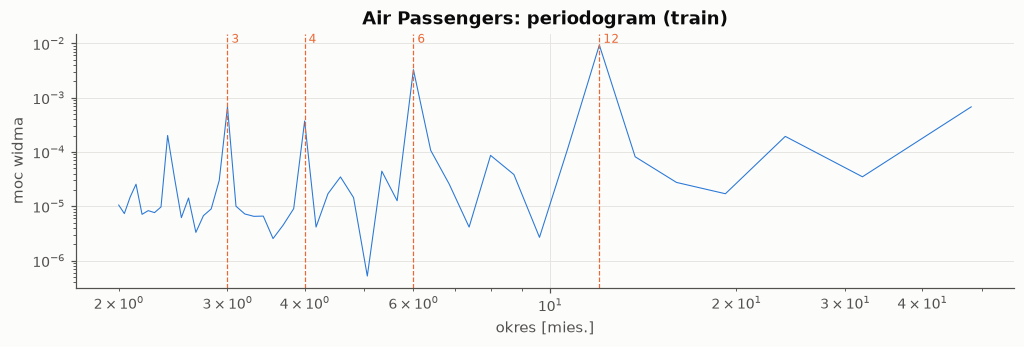

,zbiór danych,okres,udział mocy [%]
0,Jena Climate,8414.2,54.73
1,Jena Climate,24.0,6.49
2,Jena Climate,1682.8,1.15
3,Jena Climate,3005.1,1.01
4,Jena Climate,483.6,0.83
5,Jena Climate,5258.9,0.74
0,Household Power Consumption,12.0,11.90
1,Household Power Consumption,24.0,3.64
2,Household Power Consumption,4376.2,0.98
3,Household Power Consumption,6.0,0.94


In [33]:
peak_rows = []
for key in td.SPECS:
    d = D[key]; spec = d['spec']
    y_train = d['h_f'].loc[d['split'] == 'train', spec.target]
    sp, peaks = td.periodogram(y_train, spec)
    td.plot_periodogram(sp, peaks, spec, OUT); plt.show()
    peaks.insert(0, 'zbiór danych', spec.name); peak_rows.append(peaks)
    d['peaks'] = peaks
td.save_table(pd.concat(peak_rows), OUT, 'periodogram_szczyty', index=False)

**Komentarz.** Periodogram potwierdza okresy wskazane przez ACF i dekompozycję:

- **Jena Climate:** najsilniejszy jest cykl roczny (pik przy 8414 h, czyli ok. 351 dni – rozdzielczość widma przy fragmencie 4,8 roku nie pozwala trafić dokładnie w 8766 h), który odpowiada za 54,7% mocy widma. Cykl dobowy (24 h) to 6,5%; cyklu tygodniowego brak. Pozostałe piki (kilkanaście–kilkadziesiąt dni) to nieregularne zmiany pogody.
- **Household Power Consumption:** najsilniejszy pik ma okres 12 h (11,9%), a dopiero drugi 24 h (3,6%). Okres 12 h jest harmoniczną cyklu dobowego: profil zużycia ma dwa szczyty na dobę (rano i wieczorem, punkt 3.1), więc kształt doby rozkłada się na składowe 24 h i 12 h. Cykl tygodniowy nie wyróżnia się w widmie, mimo że prognoza sezonowa z lagiem 168 h była najlepsza na zbiorze uczącym; tygodniowy wzorzec jest słaby i zaszumiony. Wszystkie piki razem obejmują niewielką część mocy, co zgadza się z dużą resztą w dekompozycji (49%).
- **Metro Interstate Traffic Volume:** cykl dobowy dominuje (63,5% mocy), a dalsze piki to jego harmoniczne (12 h i 8 h) oraz cykl tygodniowy (168 h, 2,6%). Widmo liczymy na fragmencie 2015–2016 (ok. pół roku), więc cyklu rocznego nie widać.
- **Air Passengers** (logarytm z usuniętym trendem liniowym): najsilniejszy jest okres 12 miesięcy (59,6%), a kolejne piki 6, 3 i 4 miesiące to jego harmoniczne, opisujące kształt sezonu z letnim maksimum.

### 3.9 Zmienne pomocnicze

Zmienne pomocnicze mogą poprawić prognozę tylko wtedy, gdy niosą informację o przyszłej wartości targetu, której nie zawiera już jego własna historia. Na zbiorze uczącym pokazujemy dwie rzeczy:

- **macierz korelacji zmiennych** w tej samej chwili: wysokie korelacje między zmiennymi oznaczają redundancję (kilka kolumn niesie tę samą informację);
- **korelację zmiennej w chwili t z targetem w chwili t + h** dla h z naszych horyzontów; pierwszy wiersz to sam target (autokorelacja), czyli punkt odniesienia: zmienna jest obiecująca, jeśli jej korelacja z przyszłym targetem jest porównywalna z autokorelacją albo dotyczy horyzontu, przy którym autokorelacja jest słaba.

Korelacja Pearsona mierzy tylko zależność liniową, dlatego jest wskazówką, a nie rozstrzygnięciem; o przydatności zmiennych rozstrzyga eksperyment z wejściem wielowymiarowym (blok C). Air Passengers ma jedną zmienną i nie występuje w tej części.

#### Jena Climate

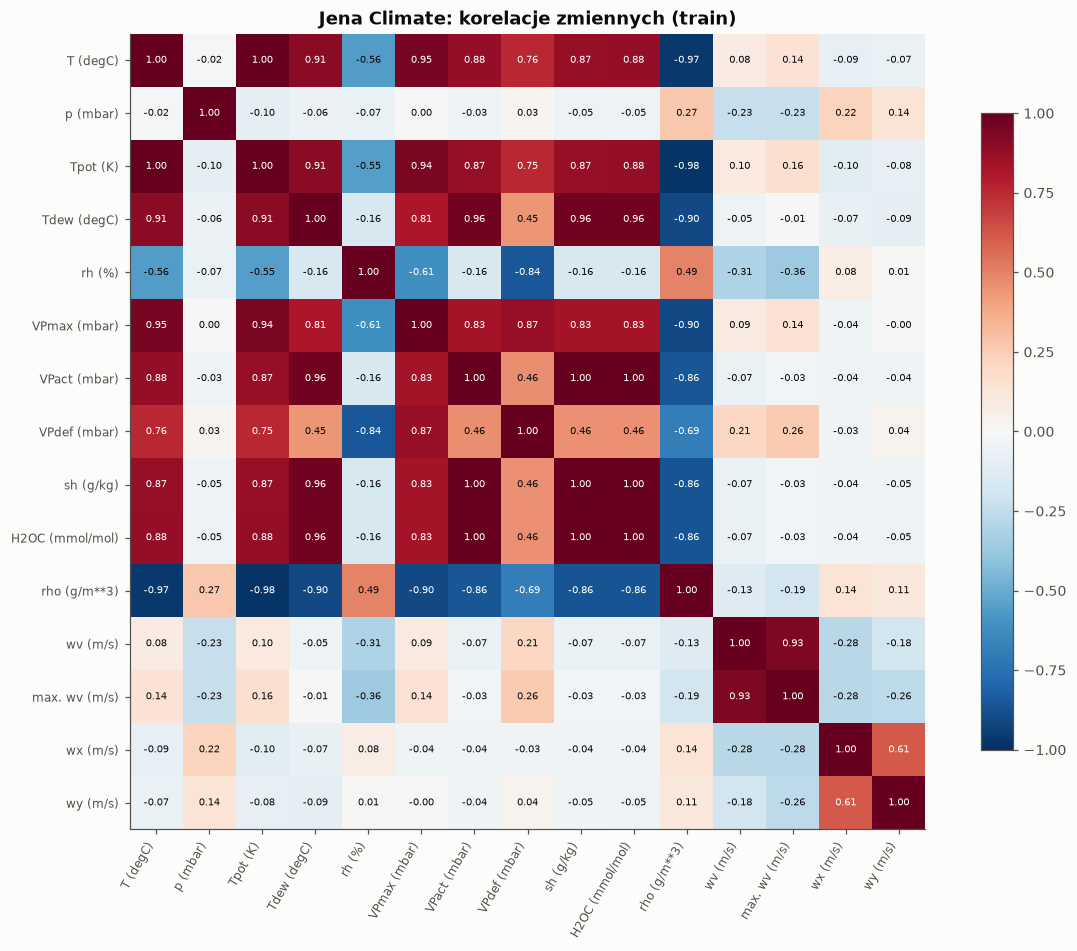

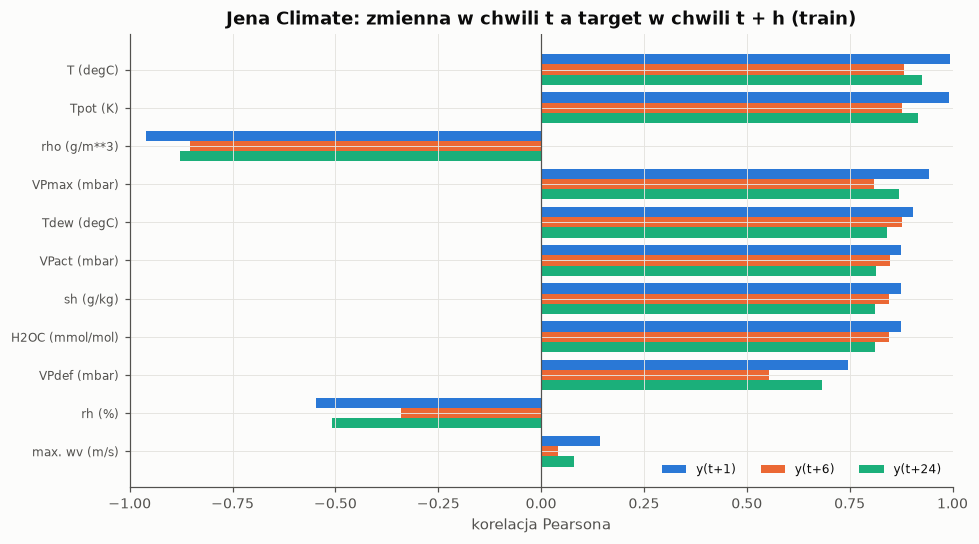

In [34]:
d = D['jena']; spec = d['spec']
h_train = d['h_f'][d['split'] == 'train']
corr = td.save_table(td.feature_correlations(h_train, spec), OUT, 'jena_macierz_korelacji')
td.plot_corr_matrix(corr, spec, OUT); plt.show()
lc = td.lagged_correlations(h_train, spec)
d['lagcorr'] = lc
td.plot_lagged_correlations(lc, spec, OUT); plt.show()

**Komentarz.** - **Redundancja:** temperatura potencjalna `Tpot` jest praktycznie kopią targetu (r = 1,00), a `VPact`, `sh` i `H2OC` są kopiami siebie nawzajem (r = 1,00); gęstość powietrza `rho` jest silnie ujemnie skorelowana z temperaturą (r = −0,97). Z 14 zmiennych pomocniczych niezależną informację niosą głównie ciśnienie, wilgotność względna i wiatr.
- **Związek z przyszłą temperaturą:** autokorelacja targetu wynosi 0,994 (h = 1), 0,882 (h = 6) i 0,925 (h = 24). Zmienne silnie skorelowane z przyszłą temperaturą (`Tpot`, `Tdew` 0,905 / 0,878 / 0,842, `rho` −0,96 / −0,85 / −0,88) powtarzają informację zawartą w samej temperaturze, a ciśnienie i wiatr mają korelacje bliskie zera.
- **Wniosek (H4):** spodziewamy się niewielkiego zysku z wejścia wielowymiarowego; ewentualna poprawa może wynikać z nieliniowych zależności (np. zmiana ciśnienia i wilgotności przed zmianą pogody), których korelacja liniowa nie pokazuje.

#### Household Power Consumption

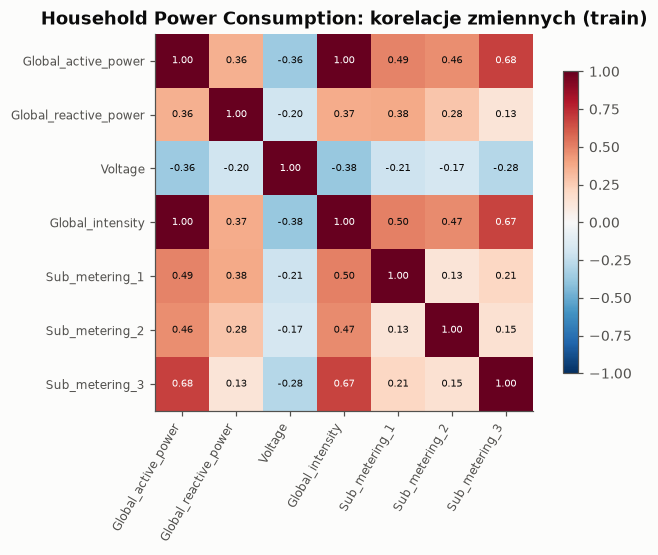

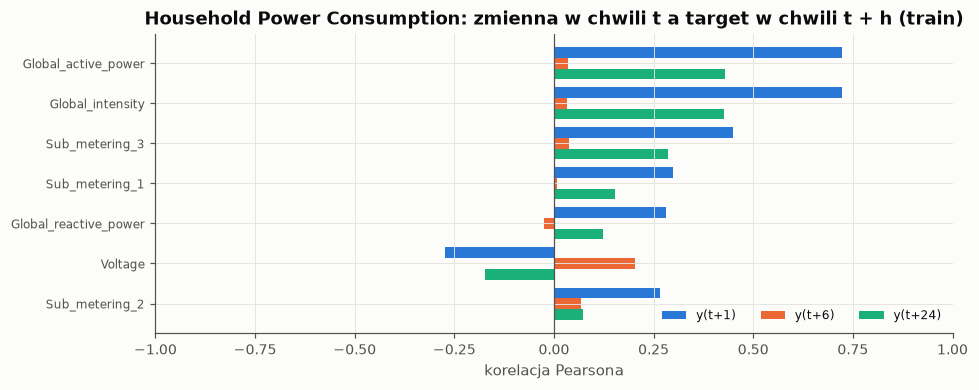

In [35]:
d = D['household']; spec = d['spec']
h_train = d['h_f'][d['split'] == 'train']
corr = td.save_table(td.feature_correlations(h_train, spec), OUT, 'household_macierz_korelacji')
td.plot_corr_matrix(corr, spec, OUT); plt.show()
lc = td.lagged_correlations(h_train, spec)
d['lagcorr'] = lc
td.plot_lagged_correlations(lc, spec, OUT); plt.show()

**Komentarz.** - **Redundancja:** natężenie prądu `Global_intensity` jest praktycznie kopią mocy czynnej (r = 1,00, bo moc to iloczyn napięcia i natężenia przy niemal stałym napięciu); podlicznik 3 (ogrzewanie wody i klimatyzacja) koreluje z mocą na poziomie 0,68.
- **Związek z przyszłą mocą:** autokorelacja targetu wynosi 0,722 (h = 1), 0,035 (h = 6) i 0,428 (h = 24). Przy h = 6 żadna zmienna nie ma silnego związku z przyszłą mocą; najwyższą korelację ma napięcie (0,204), wyższą niż sam target, co wynika z przesunięcia faz cyklu dobowego (napięcie spada przy dużym obciążeniu).
- **Wniosek (H4):** zmienne elektryczne w dużej części powielają target; niewielkiej poprawy można oczekiwać najwyżej dla h = 6, gdzie autokorelacja jest najsłabsza.

#### Metro Interstate Traffic Volume

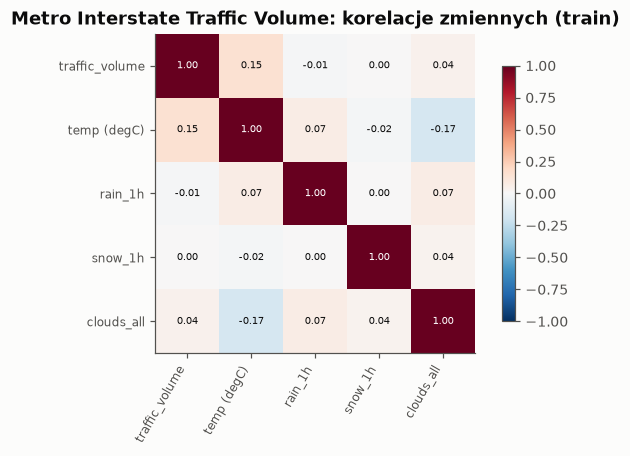

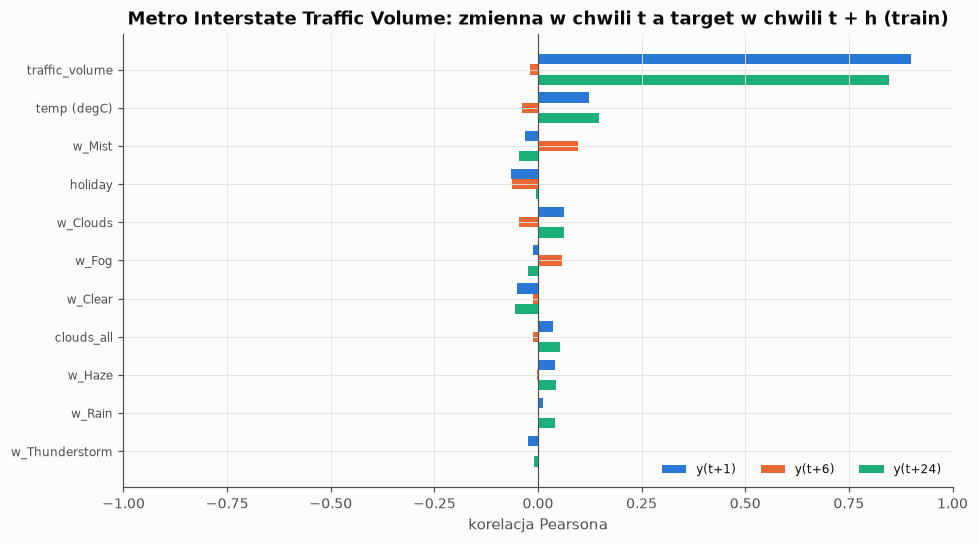

In [36]:
d = D['metro']; spec = d['spec']
h_train = d['h_f'][d['split'] == 'train']
corr = td.save_table(td.feature_correlations(h_train, spec), OUT, 'metro_macierz_korelacji')
td.plot_corr_matrix(corr, spec, OUT); plt.show()
lc = td.lagged_correlations(h_train, spec)
d['lagcorr'] = lc
td.plot_lagged_correlations(lc, spec, OUT); plt.show()

**Komentarz.** - **Redundancja:** zmienne pogodowe są ze sobą słabo powiązane (|r| ≤ 0,17), więc nie powielają się nawzajem.
- **Związek z przyszłym ruchem:** autokorelacja targetu wynosi 0,901 (h = 1), −0,02 (h = 6) i 0,848 (h = 24). Pogoda ma bardzo słaby liniowy związek z przyszłym ruchem: temperatura 0,124 / −0,039 / 0,147, opad deszczu i śniegu oraz typy pogody |r| < 0,1, flaga święta −0,066 / −0,063 / −0,006.
- **Wniosek (H4):** przy h = 6 ani historia ruchu, ani pogoda nie są liniowo związane z wartością przyszłą, bo zależność od pory dnia jest nieliniowa (dwa szczyty dobowe). Dlatego w bloku C dla Metro dodajemy zmienne kalendarzowe chwili prognozowanej (pora dnia, dzień tygodnia, święto), które są znane z wyprzedzeniem; to od nich, a nie od pogody, spodziewamy się największego zysku.

### 3.10 Wartości odstające

Wartości fizycznie niemożliwe usunęłyśmy w sekcji 1 regułami ustalonymi z góry. Tutaj opisujemy wartości możliwe, ale nietypowe. Rozróżniamy dwa pojęcia i liczymy je wyłącznie na zbiorze uczącym:

- **Wartości odstające według IQR** – nietypowe względem całego rozkładu zmiennej: poniżej Q1 − 1,5·IQR albo powyżej Q3 + 1,5·IQR (Q1, Q3 – kwartyle, IQR = Q3 − Q1). Metoda nie zna pory dnia ani roku, więc przy rozkładach wielomodalnych lub skośnych (cykle dobowe, nocne minima, opady równe zero przez większość godzin) może oznaczać prawidłowe obserwacje.
- **Anomalie względem sezonowości** – nietypowe *jak na daną porę*. Dla zbiorów godzinowych odchylenie liczymy od mediany targetu wyznaczonej na train dla tej samej pory, zgodnie z sezonowością zbioru: dla Jena Climate dla pary (miesiąc, godzina), bo dominują cykl roczny i dobowy, a tygodniowego nie ma; dla Household i Metro dla pary (dzień tygodnia, godzina), bo ich okres sezonowy to 168 h (grupy z mniej niż 10 obserwacjami pomijamy); dla Air Passengers jest to reszta dekompozycji STL logarytmu. Odchylenie dzielimy przez odporną skalę σ_robust = 1,4826·MAD (MAD – mediana odchyleń bezwzględnych od mediany) i za anomalię uznajemy |z| > 4. Gdyby MAD wynosiło 0, notatnik jawnie przechodzi na skalę 1,2533·średnie odchylenie bezwzględne. STL korzysta z sąsiednich obserwacji (także późniejszych), dlatego jego reszta służy tu wyłącznie do opisu zbioru uczącego, a nie jako cecha wejściowa modelu.

Żadna z tych metod nie oznacza automatycznie błędu danych i niczego nie usuwamy: skrajne wartości należą do zjawiska, które model ma prognozować. Tabela największych anomalii podaje daty; ich możliwe przyczyny wskazujemy tylko wtedy, gdy potwierdzają je zmienne zbioru (dla Metro tabela zawiera flagę święta i pogodę w danej godzinie).

Jena Climate - największe odchylenia od profilu sezonowego:


,czas,dzień tygodnia,wartość,oczekiwana (profil),odporny z
0,2009-01-07 04:00:00,śr,-22.592,-2.122,-4.7
1,2009-01-07 05:00:00,śr,-22.228,-2.275,-4.6
2,2009-01-07 06:00:00,śr,-22.235,-2.300,-4.6
3,2009-01-07 08:00:00,śr,-22.337,-2.555,-4.6
4,2009-01-07 07:00:00,śr,-22.020,-2.383,-4.5
5,2009-01-07 03:00:00,śr,-21.757,-2.230,-4.5
6,2009-01-07 10:00:00,śr,-21.370,-1.993,-4.5
7,2009-01-07 02:00:00,śr,-21.400,-2.210,-4.4
8,2012-02-07 04:00:00,wt,-20.780,-1.697,-4.4
9,2009-01-07 09:00:00,śr,-21.525,-2.452,-4.4


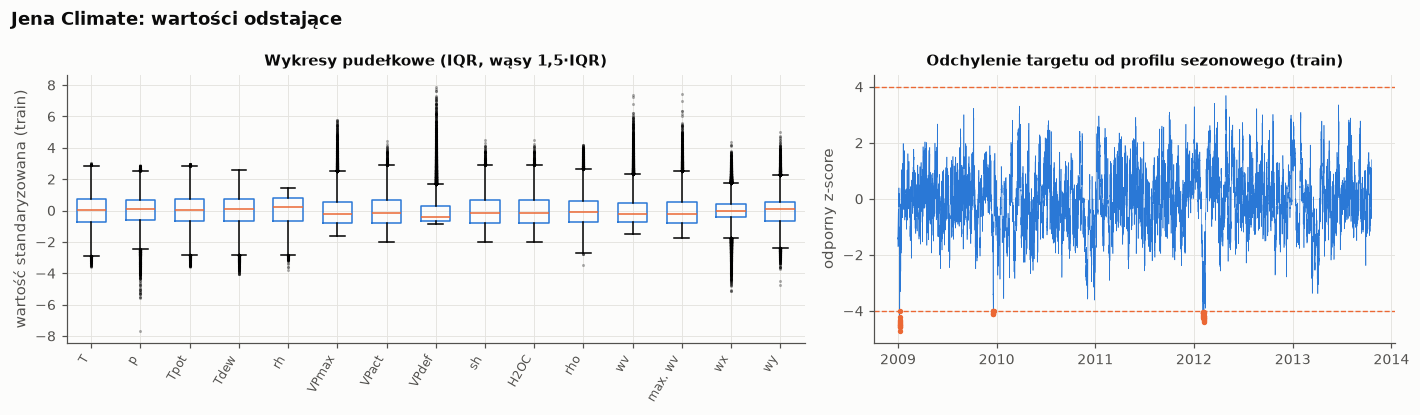

Household Power Consumption - największe odchylenia od profilu sezonowego:


,czas,dzień tygodnia,wartość,oczekiwana (profil),odporny z
0,2007-12-28 18:00:00,pt,6.312,0.701,10.1
1,2008-10-19 02:00:00,nd,5.682,0.615,9.2
2,2008-11-23 19:00:00,nd,6.566,1.641,8.9
3,2007-12-28 17:00:00,pt,5.199,0.496,8.5
4,2009-01-16 21:00:00,pt,6.467,1.773,8.5
5,2007-02-22 22:00:00,cz,6.334,1.830,8.1
6,2007-12-28 16:00:00,pt,5.075,0.611,8.1
7,2009-02-11 19:00:00,śr,5.242,0.806,8.0
8,2008-10-19 01:00:00,nd,5.207,0.809,7.9
9,2007-01-13 23:00:00,so,5.830,1.515,7.8


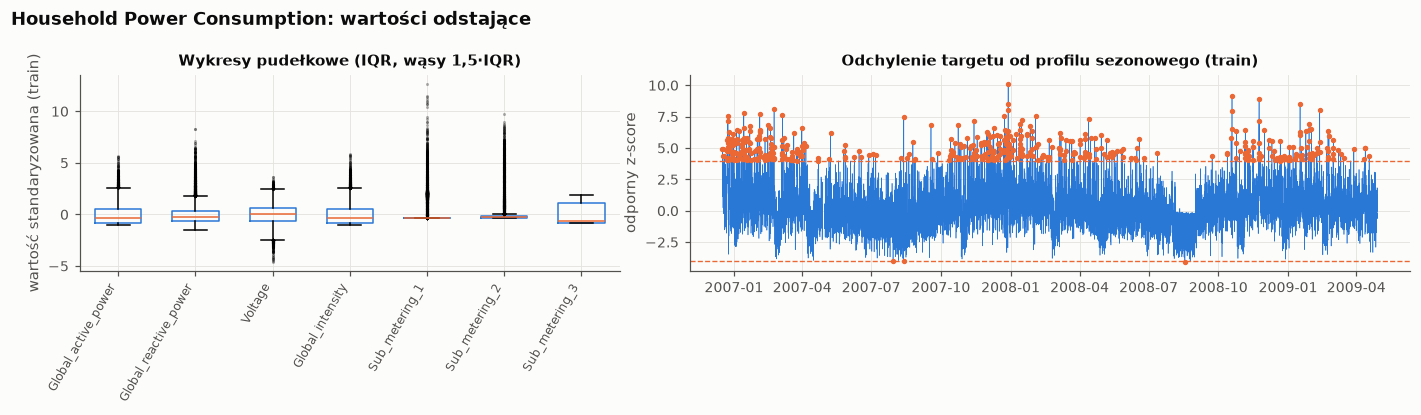

Metro Interstate Traffic Volume - największe odchylenia od profilu sezonowego:


,czas,dzień tygodnia,wartość,oczekiwana (profil),odporny z,święto,temp (degC),rain_1h,snow_1h,typ pogody
0,2012-12-25 07:00:00,wt,478.0,6323.0,-23.6,1.0,-9.70,0.0,0.0,"Mist, Snow"
1,2015-12-25 07:00:00,pt,481.0,6316.5,-23.6,1.0,-2.98,0.0,0.0,Clouds
2,2013-12-25 07:00:00,śr,538.0,6264.5,-23.1,1.0,-9.82,0.0,0.0,"Mist, Snow"
3,2013-01-01 07:00:00,wt,745.0,6323.0,-22.5,1.0,-12.49,0.0,0.0,Clear
4,2015-10-16 07:00:00,pt,815.0,6316.5,-22.2,0.0,1.98,0.0,0.0,Clear
5,2014-01-01 07:00:00,śr,772.0,6264.5,-22.2,1.0,-22.00,0.0,0.0,Clouds
6,2015-11-26 07:00:00,cz,827.0,6279.0,-22.0,1.0,2.07,0.0,0.0,Clouds
7,2016-01-01 07:00:00,pt,882.0,6316.5,-21.9,1.0,-8.99,0.0,0.0,Clear
8,2013-05-27 07:00:00,pn,943.0,6303.0,-21.6,1.0,11.27,0.0,0.0,Clouds
9,2013-12-25 08:00:00,śr,675.0,6019.0,-21.6,1.0,-9.44,0.0,0.0,"Mist, Snow"


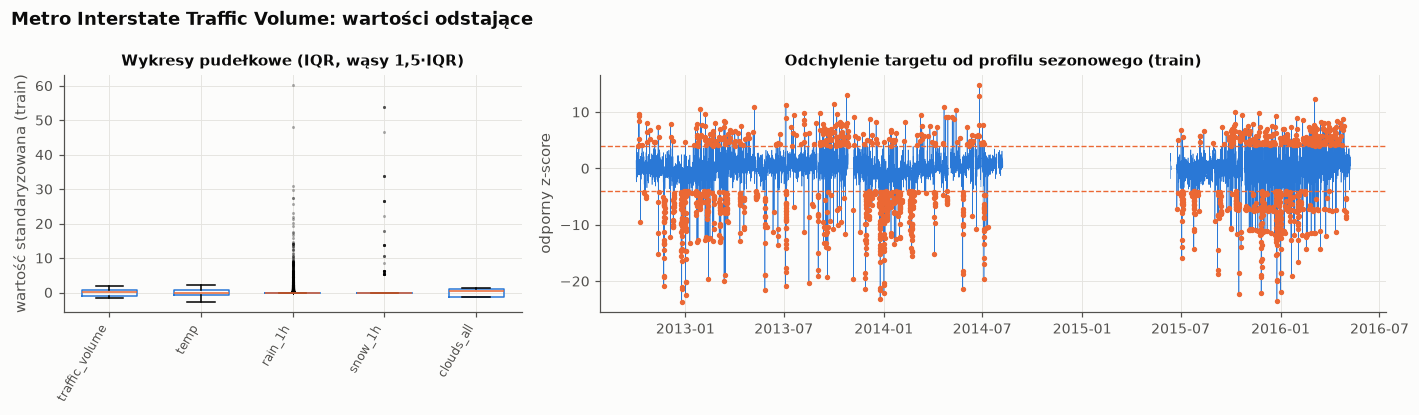

Air Passengers - największe odchylenia od profilu sezonowego:


,czas,dzień tygodnia,wartość,oczekiwana (profil),odporny z
0,1954-02-01,pn,188.0,211.048,-8.3
1,1953-04-01,śr,235.0,209.379,8.2
2,1953-05-01,pt,229.0,209.615,6.3
3,1951-05-01,wt,172.0,157.592,6.2
4,1953-03-01,nd,236.0,217.574,5.8
5,1951-03-01,cz,178.0,165.638,5.1
6,1950-01-01,nd,115.0,123.258,-5.0
7,1950-11-01,śr,114.0,122.077,-4.9
8,1950-05-01,pn,125.0,133.811,-4.9
9,1954-01-01,pt,204.0,213.164,-3.1


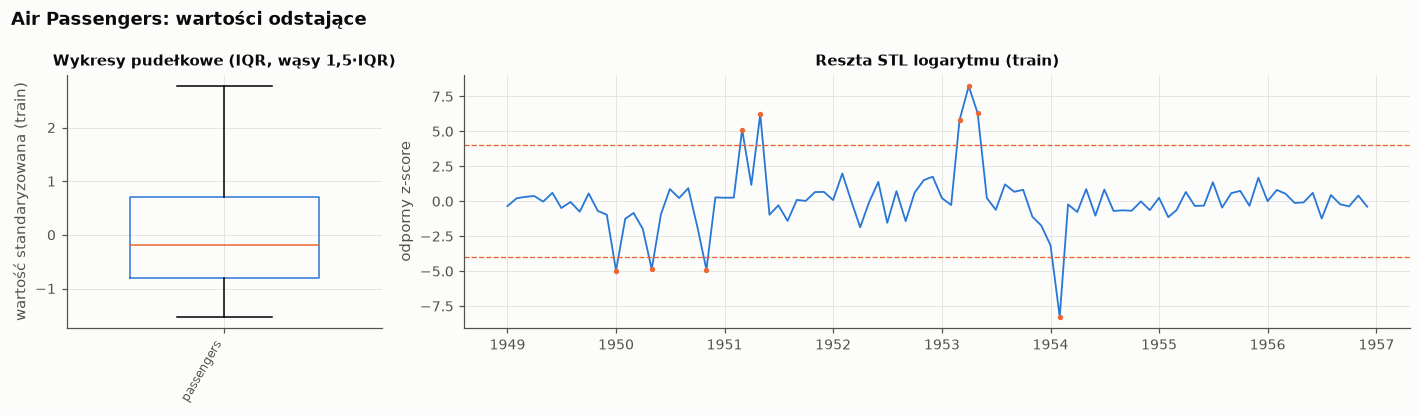

,zbiór danych,zmienna,Q1,Q3,IQR,dolna granica,górna granica,poniżej,powyżej,odstające %,min,max,udział zer %
0,Jena Climate,T (degC),2.690,15.354,12.664,-16.306,34.350,105,17,0.29,-22.592,35.520,0.0
1,Jena Climate,p (mbar),983.798,994.218,10.420,968.168,1009.848,646,93,1.76,925.053,1012.797,0.0
2,Jena Climate,Tpot (K),276.881,289.409,12.528,258.088,308.202,167,26,0.46,251.037,309.683,0.0
3,Jena Climate,Tdew (degC),-0.302,9.918,10.219,-15.630,25.246,302,0,0.72,-24.533,23.017,0.0
4,Jena Climate,rh (%),65.136,89.250,24.114,28.965,125.421,74,0,0.18,13.767,100.000,0.0
5,Jena Climate,VPmax (mbar),7.415,17.482,10.067,-7.685,32.582,0,975,2.32,0.985,57.927,0.0
6,Jena Climate,VPact (mbar),5.975,12.228,6.253,-3.405,21.608,0,120,0.29,0.827,28.168,0.0
7,Jena Climate,VPdef (mbar),0.817,5.307,4.490,-5.918,12.042,0,3154,7.50,0.000,41.867,0.3
8,Jena Climate,sh (g/kg),3.777,7.722,3.945,-2.141,13.639,0,126,0.30,0.518,18.023,0.0
9,Jena Climate,H2OC (mmol/mol),6.057,12.355,6.298,-3.391,21.802,0,123,0.29,0.833,28.660,0.0


,zbiór danych,kroki,skala,sigma_robust,anomalie (|z| > 4),anomalie %,w górę,w dół,dni z anomaliami
0,Jena Climate,42071,"1,4826·MAD",4.3453,40,0.10,0,40,8.0
1,Household Power Consumption,20680,"1,4826·MAD",0.5536,474,2.29,471,3,243.0
2,Metro Interstate Traffic Volume,22354,"1,4826·MAD",247.5942,1480,6.62,460,1020,474.0
3,Air Passengers,96,"1,4826·MAD",0.0140,9,9.38,5,4,NaN


In [37]:
iqr_rows, anom_rows = [], []
for key in td.SPECS:
    d = D[key]; spec = d['spec']
    h_train = d['h_f'][d['split'] == 'train']
    t = td.outlier_iqr_table(h_train, spec); t.insert(0, 'zbiór danych', spec.name); iqr_rows.append(t)
    summ, tops, rz = td.seasonal_anomalies(h_train, spec)
    d.update(iqr=t, anom_summ=summ)
    anom_rows.append({'zbiór danych': spec.name, **summ})
    td.save_table(tops, OUT, f'{key}_najwieksze_anomalie', index=False)
    print(spec.name, '- największe odchylenia od profilu sezonowego:'); display(tops)
    td.plot_outliers(h_train, spec, rz, out_dir=OUT); plt.show()
display(td.save_table(pd.concat(iqr_rows), OUT, 'odstajace_iqr', index=False))
display(td.save_table(pd.DataFrame(anom_rows), OUT, 'odstajace_profil', index=False))

**Komentarz.** - **Jena Climate:** według IQR 0,29% godzin temperatury jest odstających (105 poniżej −16,3 °C, 17 powyżej 34,4 °C); względem profilu miesiąc × godzina (σ_robust = 4,35 °C) anomalii jest 40 godzin (0,1%), wszystkie w dół, w 8 dniach: fale mrozu na początku stycznia 2009 r. (najsilniej 7.01.2009, 4:00: −22,6 °C przy typowych −2,1 °C, z = −4,7), na przełomie 2009 i 2010 r. i na początku lutego 2012 r. Są to ciągi kolejnych godzin z płynnym przebiegiem temperatury, co przemawia za rzeczywistymi zdarzeniami. Najwięcej wartości odstających według IQR mają zmienne o skośnych rozkładach (składowa wiatru wx 10,15%, VPdef 7,5%).
- **Household Power Consumption:** według IQR 2,14% godzin mocy leży powyżej 3,64 kW; względem profilu dzień tygodnia × godzina (σ_robust = 0,55 kW) anomalii jest 474 godziny (2,29%) w 243 dniach, prawie wyłącznie w górę (471), głównie zimą. Największa: 28.12.2007, 18:00, 6,31 kW przy typowych 0,70 kW (z = 10,1). Przyczyn pojedynczych skoków nie przypisujemy, bo dane nie mówią, które urządzenia pracowały. Podliczniki mają dużo wartości odstających według IQR (podlicznik 1: 14,8%), bo w 85% godzin wynoszą 0.
- **Metro Interstate Traffic Volume:** według IQR natężenie ruchu nie ma wartości odstających (rozkład szeroki i wielomodalny); względem profilu (σ_robust = 248 pojazdów/h) anomalii jest 1480 godzin (6,62%) w 474 dniach, w tym 1020 w dół. Dziesięć największych to poranny szczyt z ruchem kilkakrotnie mniejszym od typowego; w dziewięciu zbiór ma flagę święta (m.in. 25.12 i 1.01), w jednym (16.10.2015) dane nie wskazują przyczyny. Część anomalii w górę wynika z tego, że skala jest wspólna dla wszystkich godzin, a w nocy ruch jest mały i mało zmienny.
- **Air Passengers:** według IQR brak wartości odstających (wysokie wartości z końca szeregu to trend); reszta STL logarytmu ma bardzo małą skalę (σ_robust = 0,014, ok. 1,4%), więc próg odpowiada odchyleniu o ok. 6% i przekracza go 9 z 96 miesięcy (1950, wiosna 1951 i 1953, luty 1954: 188 zamiast ok. 211 tys., z = −8,3).

**Wniosek:** analiza nie dała przesłanek, aby uznać wartości nietypowe za błędy pomiarowe, więc zostają w danych jako potencjalnie rzeczywiste zdarzenia ekstremalne; strata MSE będzie na nie wrażliwa (szczególnie Household i Metro), dlatego konfiguracje wybieramy według MAE, a flaga święta dla chwili prognozowanej w Metro ma uzasadnienie także w tej analizie.

### 3.11 Zestawienie zbiorcze i porównanie zbiorów

Tabela zbiorcza charakteryzuje wszystkie cztery zbiory w jednym miejscu, a tabela decyzji zbiera ustalenia dotyczące przygotowania danych.

In [38]:
summary, decisions = [], []
for key, spec in td.SPECS.items():
    d = D[key]; split = d['split']
    summary.append({
        'zbiór': spec.name, 'źródło': spec.source, 'zakres': d['range'],
        'dane surowe: wiersze': d['raw_rows'],
        'duplikaty czasu (nadmiarowe wiersze)': d['reg']['nadmiarowe wiersze (duplikaty)'],
        'brakujące punkty siatki surowej': d['reg']['brakujące punkty siatki'],
        'wartości fizycznie niemożliwe': int(d['anom']['liczba'].sum()) if len(d['anom']) else 0,
        'kroki robocze': len(d['h_f']), 'braki targetu po agregacji %': round(100 * d['miss_after'], 2),
        'braki targetu po uzupełnieniu %': round(100 * d['miss_final'], 2),
        'train / val / test': ' / '.join(str(int((split == s).sum())) for s in td.SPLITS),
        **{f'ACF lag {s}': round(d['acf_lvl'].get(s, np.nan), 3) for s in spec.seasonal_candidates},
        **{f'ACF różnic lag {s}': round(d['acf_tr'].get(s, np.nan), 3) for s in spec.seasonal_candidates},
        'proponowany okres s': d['s'],
        'siła trendu F_T': d['strength']['siła trendu F_T'],
        **{k: v for k, v in d['strength'].items() if k.startswith('siła: ')},
        'poziomy stacjonarne?': d['stationarity'].iloc[0]['wniosek'],
        'najsilniejszy okres (periodogram)': d['peaks'].iloc[0]['okres'],
        'KS val / test vs train': f"{d['dist'].iloc[1]['KS vs train']} / {d['dist'].iloc[2]['KS vs train']}",
        'test poza zakresem train %': d['dist'].iloc[2]['poza zakresem train [%]'],
        'target: odstające IQR %': d['iqr'].iloc[0]['odstające %'],
        'target: anomalie wzgl. profilu %': d['anom_summ']['anomalie %'],
    })
    decisions += [
        {'zbiór': spec.name, 'decyzja': 'okres sezonowy s', 'wartość': d['s'],
         'uzasadnienie': 'najmniejsze średnie MAE seasonal naive na train spośród ' + str(spec.seasonal_candidates)},
        {'zbiór': spec.name, 'decyzja': 'wartości fizycznie niemożliwe', 'wartość': summary[-1]['wartości fizycznie niemożliwe'],
         'uzasadnienie': 'zamienione na braki; reguły ustalone z góry'},
        {'zbiór': spec.name, 'decyzja': 'luki ≤ 3 kroki', 'wartość': 'ostatnia znana wartość',
         'uzasadnienie': 'uzupełnianie przyczynowe; okna przecinające dłuższe luki są pomijane'},
        {'zbiór': spec.name, 'decyzja': 'skalowanie', 'wartość': 'StandardScaler (train)',
         'uzasadnienie': 'parametry wyłącznie ze zbioru uczącego'},
        {'zbiór': spec.name, 'decyzja': 'okno bazowe', 'wartość': '72 h' if spec.freq == 'h' else '24 mies.',
         'uzasadnienie': {24: 'trzy cykle dobowe, obejmuje okres s = 24 (sekcja 3.5)',
                          168: 'trzy cykle dobowe; okres s = 168 dłuższy od okna (sekcja 3.5)',
                          12: 'dwa pełne cykle roczne (sekcja 3.5)'}[d['s']]},
    ]
td.save_table(pd.DataFrame(summary).set_index('zbiór'), OUT, 'zestawienie_zbiorcze')
td.save_table(pd.DataFrame(decisions), OUT, 'decyzje', index=False)

,zbiór,decyzja,wartość,uzasadnienie
0,Jena Climate,okres sezonowy s,24,najmniejsze średnie MAE seasonal naive na trai...
1,Jena Climate,wartości fizycznie niemożliwe,38,zamienione na braki; reguły ustalone z góry
2,Jena Climate,luki ≤ 3 kroki,ostatnia znana wartość,uzupełnianie przyczynowe; okna przecinające dł...
3,Jena Climate,skalowanie,StandardScaler (train),parametry wyłącznie ze zbioru uczącego
4,Jena Climate,okno bazowe,72 h,"trzy cykle dobowe, obejmuje okres s = 24 (sekc..."
5,Household Power Consumption,okres sezonowy s,168,najmniejsze średnie MAE seasonal naive na trai...
6,Household Power Consumption,wartości fizycznie niemożliwe,0,zamienione na braki; reguły ustalone z góry
7,Household Power Consumption,luki ≤ 3 kroki,ostatnia znana wartość,uzupełnianie przyczynowe; okna przecinające dł...
8,Household Power Consumption,skalowanie,StandardScaler (train),parametry wyłącznie ze zbioru uczącego
9,Household Power Consumption,okno bazowe,72 h,trzy cykle dobowe; okres s = 168 dłuższy od ok...


**Komentarz.**

- **Najsilniejsza sezonowość:** Metro (cykl dobowy i tygodniowy, ACF różnic 0,66 przy lagu 168) oraz Jena Climate (cykl dobowy, 0,58 przy lagu 24). Household ma najsłabszą autokorelację i najwięcej szumu.
- **Najwięcej braków:** Metro (17,5% godzin targetu po uzupełnieniu, w tym 29,1% kroków zbioru uczącego); pozostałe zbiory mają najwyżej 1,23%.
- **Najsilniejszy trend:** tylko Air Passengers, z przesunięciem walidacji i testu o 2,25 i 3,33 odchylenia względem zbioru uczącego.
- **Oczekiwania wobec hipotez:** największej przewagi LSTM/GRU nad persistence spodziewamy się dla Jena Climate na horyzontach 6 i 24 h, gdzie szereg jest gładki i regularny, a persistence traci przewagę (H1). Dla Metro trudnym punktem odniesienia będzie prognoza sezonowa z lagiem tygodniowym, więc ważne będzie okno 168 h (H2). Dla Air Passengers mała liczba przykładów (61 przy L = 24, h = 12) i ekstrapolacja trendu sprzyjają modelom prostym (H3). Wejście wielowymiarowe ma największe szanse pomóc dla Metro dzięki zmiennym kalendarzowym, a niewielkie dla Jena Climate, bo część zmiennych niemal powiela temperaturę (H4).
- **Charakterystyka rozszerzona (punkty 2.1 i 3.6–3.9):** Metro ma najsilniejszą i najbardziej regularną sezonowość (siła dobowa 0,92, tygodniowa 0,69, cykl dobowy to 63,5% mocy widma), Jena Climate – dominujący wolny trend z cyklem rocznym (F_T = 0,90, cykl roczny 54,7% mocy) i umiarkowany cykl dobowy (0,51), Household – najwięcej szumu (reszta 49% wariancji), a Air Passengers – trend i sezonowość roczną, które opisują szereg niemal całkowicie (0,99 i 0,94). Poziomy szeregów godzinowych dają niejednoznaczny wynik testów stacjonarności (ADF i KPSS odrzucają swoje hipotezy), a po zróżnicowaniu są stacjonarne; Air Passengers jest niestacjonarny. Rozkłady walidacji i testu są bliskie uczącemu dla zbiorów godzinowych (KS ≤ 0,13) i bardzo odległe dla Air Passengers (KS 0,85 i 0,94).
- **Zmienne pomocnicze (H4):** w Jenie i Household dużą część zmiennych stanowią kopie targetu (`Tpot`, `Global_intensity`, r = 1,00), a w Metro pogoda jest słabo związana z przyszłym ruchem, dlatego największego zysku z wejścia wielowymiarowego spodziewamy się po zmiennych kalendarzowych chwili prognozowanej w Metro.

## Eksport wyników

In [39]:
archive = shutil.make_archive('dane_wyniki', 'zip', OUT)
print('Archiwum:', archive, '| czas wykonania notatnika: %.1f min' % ((time.time() - T0) / 60))

Archiwum: C:\projekt2a\dane_wyniki.zip | czas wykonania notatnika: 4.5 min
